# Báo cáo phân tích bộ dữ liệu DAD


## Tóm tắt một trang

**Dữ liệu là gì.** 7 ngày (21–27/10/2019) lưu lượng MQTT của **16 cảm biến nhiệt độ** trên **4 tủ làm mát InRow** (13, 15, 23, 25) trong data center CITIC: 101.583 gói tin, trong đó **32.288 bản tin nhiệt độ**. Theo bài báo gốc [1], giá trị nhiệt độ được dựng lại từ 14 ngày đo thật. Mỗi tủ có 4 cảm biến: nước vào (TFEU ≈ 11 °C), nước ra (TFSU ≈ 15 °C), khí cấp (TAS ≈ 20 °C), khí hồi (TAR ≈ 27 °C).

**Bình thường trông thế nào.**
- Mỗi cảm biến gửi đúng **300,1 giây** một lần, lệch cỡ mili-giây; 16 cảm biến gửi gần như cùng một khoảnh khắc.
- Giá trị dao động **±0,3 °C** quanh một mức cố định; **không có chu kỳ ngày**, không ngày nào giống ngày nào.
- Gai nhiễu ±1–2 °C chỉ đơn lẻ, đối xứng, **không quá 2 bản tin liền**.
- Thứ tự vật lý TFEU < TFSU < TAS < TAR luôn đúng, cách nhau ít nhất 3,5 °C.

**Bất thường.** Chỉ **InRow 13** bị tấn công, **11 cửa sổ sự cố**, mỗi kiểu một dấu vết riêng và luôn tác động **cả 4 cảm biến** của tủ:

| Kiểu | Dấu vết | Có nhãn? |
|---|---|---|
| chặn gói (4 cửa sổ) | khoảng hở 10–55 phút trong nhịp gửi | không |
| node tự ngừng gửi (1 cửa sổ, **phát hiện mới**) | gửi xong 288 bản tin của phiên rồi DISCONNECT sớm 52 phút | không |
| chèn bản tin (3 cửa sổ) | bản tin đến cách nhau 30–104 giây, giá trị thấp | có |
| sửa giá trị (3 cửa sổ) | cả tủ bị **trừ 0–3 °C** cùng lúc, khoảng cách giữa cảm biến không đổi | có |

Nhãn chỉ có **544 bản tin** (bài báo ghi 1.088 vì đếm cả gói xác nhận); khoảng 1/3 slot có nhãn không hề bị đổi giá trị.

**Những đặc điểm dễ gây hiểu nhầm (mục “Cấu trúc giữa các cảm biến và giữa các tủ”, mục “Trông như bất thường nhưng không phải”).** Một số đặc điểm của dữ liệu trông như tín hiệu nhưng không phản ánh tấn công: InRow 13, 15, 23 có nhiệt độ gần như trùng nhau (tương quan 0,998) vào ngày bình thường, còn vào các ngày bị tấn công InRow 13 lệch khỏi nhóm **cả ngày**, kể cả những giờ không bị tấn công; `keepalive` đổi theo ngày ở mọi tủ; hiệu giữa các cảm biến lặp lại mỗi 1 giờ; các đợt tấn công rơi vào khung giờ cố định. Dùng chúng làm tín hiệu sẽ báo sai.

**Đúc kết nghiệp vụ.**
- **Giám sát vận hành thông thường bị mù:** nhiệt độ khí cấp vẫn trong vùng ASHRAE, RCI ≥ 98%, ΔT không đổi, vì tấn công trừ đều cả 4 cảm biến. Phải có lớp **"dữ liệu có đáng tin không"**.
- Ba quy tắc giải thích được, chỉ dùng quá khứ: **im lặng > 1,5 chu kỳ**, **đến sớm < 0,8 chu kỳ**, **lệch âm ≥ 3/6 chu kỳ**. Kết quả: bắt **11/11 cửa sổ, 0 báo giả** trên 4 tủ cả tuần; trễ 1–28 phút; ngưỡng chọn trên T2–T5 vẫn đúng trên T6–T7.
- Gộp cảnh báo theo tủ: từ 41 cảnh báo/10 phút về **2,6 sự cố/ngày**.
- Điều tra tự động suy đúng kiểu sự cố **11/11**, kèm số bản tin mất/thừa, mức bị trừ (thường 2 °C), phạm vi (4/4 cảm biến).
- Danh mục 20 tín hiệu ứng viên ở mục “Danh mục tín hiệu”: 8 đưa vào (7 cảnh báo + 1 chỉ số báo cáo ngày), 6 chỉ hiển thị hoặc dùng khi điều tra, 5 loại, 1 thay bằng cách đo khác.

**Giới hạn.** Một tủ bị tấn công, 7 ngày, dao động và tương quan đơn giản hơn dữ liệu đo thật, không có lỗi cảm biến lẻ: đủ để thiết kế và chứng minh, chưa đủ để nói về hiệu năng ngoài đời.

In [1]:
import os, sys, glob, re, json, gzip, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath(os.path.join("..", "src")))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from IPython.display import display, Markdown
from dad_loader import load_all, dad_files, INROW_IP, BROKER_IP, DAYS
import dad_mining as dm

RAW = os.path.abspath(os.path.join("..", "..", "data"))         # dữ liệu gốc: data/binh_thuong/ (T2, CN), data/bat_thuong/ (T3–T7)
CACHE = os.path.abspath(os.path.join("..", "data", "processed"))  # cache đọc PCAP (không commit)
FIG_DIR = os.path.abspath(os.path.join("figures", "khung")); os.makedirs(FIG_DIR, exist_ok=True)
TZ = "Europe/Madrid"
P = dm.PERIOD_S                                                   # 300,1 giây
SENSORS = ["TFEU", "TFSU", "TAS", "TAR"]                          # thứ tự vật lý: lạnh nhất → nóng nhất
DAY_VI = dict(zip(DAYS, ["T2 21/10", "T3 22/10", "T4 23/10", "T5 24/10", "T6 25/10", "T7 26/10", "CN 27/10"]))

pd.set_option("display.width", 180); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 90)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]; ALERT = "#e34948"; INK = "#0b0b0b"; INK2 = "#52514e"; GRID = "#c3c2b7"
MUTED = "#9a9890"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "grid.color": GRID,
                     "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.4,
                     "axes.prop_cycle": plt.cycler(color=SERIES), "axes.edgecolor": INK2,
                     "text.color": INK, "axes.labelcolor": INK2, "axes.titlesize": 11})


def save(fig, name: str) -> None:
    """Lưu hình cho slide (PNG 150 dpi, nền trắng) vào figures/khung/."""
    fig.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=150, bbox_inches="tight", facecolor="white")


FACTS: list[dict] = []


def fact(key: str, value, expect=None, tol: float = 0.0):
    """Ghi lại một con số được nhắc trong phần chữ và so với giá trị mong đợi (nếu có)."""
    if expect is None:
        ok = None
    elif isinstance(expect, (int, float, np.integer, np.floating)) and not isinstance(expect, bool):
        ok = bool(abs(float(value) - float(expect)) <= tol)
    else:
        ok = value == expect
    FACTS.append({"mục": key, "giá trị tính được": value, "phần chữ ghi": expect, "khớp": ok})
    return value


def local(ts: pd.Series, fmt: str = "%a %d/%m %H:%M") -> pd.Series:
    return ts.dt.tz_convert(TZ).dt.strftime(fmt)

In [2]:
packets, pubs = load_all(RAW, CACHE)                                   # 1 dòng / gói; 1 dòng / bản tin nhiệt độ
pubs = dm.add_baseline(pubs)                                           # thêm new_conn, base, dev, slot
net = dm.parse_network(RAW, os.path.join(CACHE, "network.pkl"))        # 1 dòng / gói, đủ trường IP/TCP/UDP/MQTT
net["day"] = pd.Categorical(net["day"], categories=DAYS, ordered=True)
nodes = dm.node_slots(pubs)                                            # 1 dòng / (tủ, slot 5 phút)
gt = dm.ground_truth(pubs)                                             # 11 cửa sổ sự cố
r13 = pubs[pubs.inrow == 13]
CLEAN = (pubs.inrow != 13) | pubs.day.isin(["mon", "sun"])             # bản tin chắc chắn không bị tấn công
print(f"gói: {len(net):,} | bản tin nhiệt độ: {len(pubs):,} | cảm biến: {pubs.client_id.nunique()} | "
      f"slot (tủ × 5 phút): {len(nodes):,} | cửa sổ sự cố: {len(gt)}")

gói: 101,583 | bản tin nhiệt độ: 32,288 | cảm biến: 16 | slot (tủ × 5 phút): 8,018 | cửa sổ sự cố: 11


---
# Bài toán và nguồn gốc dữ liệu

## Ngoài đời thật, dữ liệu đo cái gì?

**Sự cố gốc.** Data center của CITIC (Đại học A Coruña, Tây Ban Nha) từng sập: phần mềm cấu hình sai khiến cảm biến gửi nhiệt độ sai tới hệ thống làm mát, máy chủ quá nhiệt, phần cứng hỏng. Bộ dữ liệu DAD được làm ra để luyện phát hiện đúng loại sự cố này.

*Nguồn: [1] mục 1.1 ("An initial software failure, derived from incorrect sensor configuration in the data center, caused temperature sensors to send incorrect data to the cooling system").*

**Cách phòng máy được làm mát:**
- Rack máy chủ hút khí lạnh từ **lối lạnh** ở mặt trước, thổi khí nóng ra **lối nóng** ở mặt sau.
- **Tủ làm mát InRow** đặt xen giữa các rack: hút khí nóng, cho đi qua dàn ống có **nước lạnh**, thổi khí đã làm mát ra lối lạnh.
- Nước lạnh vào tủ, nhận nhiệt từ không khí, ra ấm hơn, quay về máy làm lạnh trung tâm.

Mỗi tủ có 4 cảm biến nhiệt độ ([1] mục 3.1). Sơ đồ dưới đây tóm tắt vị trí và vai trò của chúng; ΔT khí, ΔT nước, approach giải thích ở mục “Bốn lớp tín hiệu”:

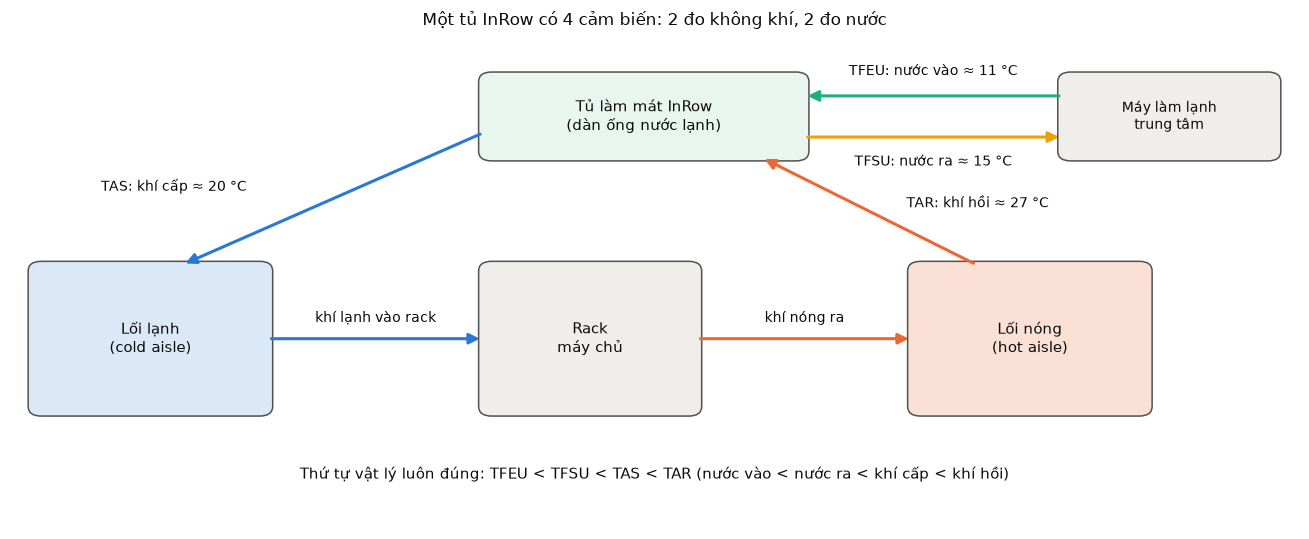

In [3]:
fig, ax = plt.subplots(figsize=(12, 5)); ax.set_xlim(0, 12); ax.set_ylim(0, 6); ax.axis("off")
def box(x, y, w, h, text, fc, ec=INK2, fs=10):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.12", fc=fc, ec=ec, lw=1))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, color=INK)
def arrow(x1, y1, x2, y2, color):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=14, color=color, lw=2))
def note(x, y, text, ha="center"):
    ax.text(x, y, text, ha=ha, va="center", fontsize=9, color=INK)
box(0.2, 1.4, 2.2, 1.8, "Lối lạnh\n(cold aisle)", "#dbe8f8")
box(4.4, 1.4, 2.0, 1.8, "Rack\nmáy chủ", "#efeeea")
box(8.4, 1.4, 2.2, 1.8, "Lối nóng\n(hot aisle)", "#fbe0d6")
box(4.4, 4.5, 3.0, 1.0, "Tủ làm mát InRow\n(dàn ống nước lạnh)", "#e9f6f0")
box(9.8, 4.5, 2.0, 1.0, "Máy làm lạnh\ntrung tâm", "#efeeea", fs=9)
arrow(2.4, 2.3, 4.4, 2.3, SERIES[0]); note(3.4, 2.55, "khí lạnh vào rack")
arrow(6.4, 2.3, 8.4, 2.3, SERIES[1]); note(7.4, 2.55, "khí nóng ra")
arrow(9.0, 3.2, 7.0, 4.5, SERIES[1]); note(8.35, 3.95, "TAR: khí hồi ≈ 27 °C", ha="left")
arrow(4.4, 4.8, 1.6, 3.2, SERIES[0]); note(2.2, 4.15, "TAS: khí cấp ≈ 20 °C", ha="right")
arrow(9.8, 5.25, 7.4, 5.25, SERIES[2]); note(8.6, 5.55, "TFEU: nước vào ≈ 11 °C")
arrow(7.4, 4.75, 9.8, 4.75, SERIES[3]); note(8.6, 4.45, "TFSU: nước ra ≈ 15 °C")
ax.text(6, 0.6, "Thứ tự vật lý luôn đúng: TFEU < TFSU < TAS < TAR (nước vào < nước ra < khí cấp < khí hồi)",
        ha="center", fontsize=10, color=INK)
ax.set_title("Một tủ InRow có 4 cảm biến: 2 đo không khí, 2 đo nước", color=INK)
plt.tight_layout(); save(fig, "A1_tu_inrow_4_cam_bien"); plt.show()

In [4]:
from dad_paper import REAL_TABLE1, SENSOR_INFO
HINH1 = {"TFEU": 1, "TFSU": 2, "TAR": 3, "TAS": 4}          # số ghi trên Hình 1 của bài báo
cam_bien = pd.DataFrame([(HINH1[s], s, SENSOR_INFO[s][0], SENSOR_INFO[s][1], SENSOR_INFO[s][2],
                          min(REAL_TABLE1[(i, s)][2] for i in (13, 15, 23, 25)), max(REAL_TABLE1[(i, s)][3] for i in (13, 15, 23, 25)),
                          np.mean([REAL_TABLE1[(i, s)][1] for i in (13, 15, 23, 25)]))
                         for s in sorted(HINH1, key=HINH1.get)],
                        columns=["số trên Hình 1", "mã", "tên đầy đủ (bài báo)", "đo cái gì", "chữ số cuối clientId",
                                 "min (°C)", "max (°C)", "độ lệch chuẩn TB (°C)"]).set_index("số trên Hình 1")
print("4 cảm biến của mỗi tủ làm mát. Ba cột cuối: số đo 14 ngày tại CITIC, gộp 4 tủ ([1] Table 1).")
cam_bien.round(2)

4 cảm biến của mỗi tủ làm mát. Ba cột cuối: số đo 14 ngày tại CITIC, gộp 4 tủ ([1] Table 1).


,mã,tên đầy đủ (bài báo),đo cái gì,chữ số cuối clientId,min (°C),max (°C),độ lệch chuẩn TB (°C)
số trên Hình 1,,,,,,,
1,TFEU,Unit Entering Fluid Temperature,nước lạnh đi vào tủ,1,8.1,14.3,0.98
2,TFSU,Unit Leaving Fluid Temperature,nước đi ra khỏi tủ,2,12.8,17.8,0.86
3,TAR,Unit Return Air Temperature,khí hồi từ lối nóng,4,25.1,28.1,0.24
4,TAS,Unit Supply Air Temperature,khí cấp ra lối lạnh,3,17.9,21.2,0.38


Mỗi tủ làm mát có **4 cảm biến**, đánh số 1–4 như trên Hình 1 bên dưới. Ba cột số đo lấy từ **Table 1 của bài báo** ([1] mục 3.2): 14 ngày đo tại CITIC ở 4 tủ (theo trục Hình 2 của bài báo là nửa đầu tháng 11; bài báo không ghi năm). Tên đầy đủ của cảm biến: [1] mục 3.1. Hai cảm biến nước (TFEU, TFSU) dao động mạnh nhất (độ lệch chuẩn ≈ 0,9 °C), khí cấp và khí hồi ổn định hơn (≈ 0,2–0,4 °C).

**Vì sao 4 cảm biến này quan trọng** (suy luận của dự án từ [1] mục 1.1): nếu TAS báo **thấp hơn nhiệt độ thực tế**, bộ điều khiển tưởng phòng đang mát và **giảm làm lạnh**, trong khi máy chủ đang nóng dần. Đó chính là kịch bản của sự cố CITIC, và cũng là kiểu tấn công "sửa giá trị" trong DAD (mục “Sửa giá trị”): mọi giá trị bị sửa đều **thấp hơn** giá trị đúng.

### Sơ đồ phòng máy (Hình 1 của bài báo)

![Hình 1: kiến trúc vật lý](figures/paper/fig01.png)

*Nguồn: Vigoya et al., Sensors 2020, Hình 1 (CC BY 4.0).*

- Hai dãy tủ quay lưng vào nhau, giữa là **lối nóng** (đỏ), hai bên là **lối lạnh** (xanh). Dãy trên có InRow 15 và 13, dãy dưới có InRow 25 và 23. `SAI` là bộ lưu điện (UPS).
- `NETBOTZ 1/2` (IP `10.6.56.58` và `10.6.56.49`, [1] mục 3.1) là thiết bị giám sát môi trường của APC, gom dữ liệu cảm biến của mỗi dãy.
- Số trên hình: **1 = TFEU, 2 = TFSU** (gắn trên ống nước), **3 = TAR** (phía lối nóng), **4 = TAS** (phía lối lạnh).
- **Lưu ý khi đọc dữ liệu:** chữ số cuối của `clientId` trong file dữ liệu khớp với hình ở 1 và 2, nhưng **đảo ở 3 và 4**: `x3` là TAS (≈ 20 °C), `x4` là TAR (≈ 27 °C), xác định bằng giá trị đo (mục “Từ điển định danh”). Bảng trên có cột "chữ số cuối clientId" để đối chiếu.

## Bài báo gốc nói gì

**L. Vigoya, D. Fernandez, V. Carneiro, F. Cacheda**, *Annotated Dataset for Anomaly Detection in a Data Center with IoT Sensors*, **Sensors 2020, 20(13), 3745**, doi:10.3390/s20133745. Bài báo truy cập mở (CC BY 4.0): https://pmc.ncbi.nlm.nih.gov/articles/PMC7374380/ . Trong notebook gọi là **[1]**; danh sách nguồn đầy đủ ở mục “Nguồn tham khảo”.

| Khía cạnh | Bài báo mô tả |
|---|---|
| Mục tiêu | tạo bộ dữ liệu **có gán nhãn** về lưu lượng mạng IoT để luyện phát hiện bất thường, vì chưa có bộ nào phù hợp |
| Dữ liệu thật | 14 ngày đo tại CITIC bằng cảm biến thụ động NFC trên rack, PDU và tủ InRow. Bộ dữ liệu chỉ gồm **cảm biến InRow**, vì giá trị ở rack và PDU gần như không đổi |
| Hạ tầng | VMware ESXi 6.5, mạng ảo nội bộ; **5 máy ảo Ubuntu 18.04**: 1 máy chạy broker **Mosquitto** + `tcpdump`, 4 máy là 4 tủ, mỗi máy chạy 4 tiến trình cảm biến |
| Giao thức | **MQTT, không xác thực, không mã hoá** (giống hệ thống thật); đồng bộ giờ bằng NTP |
| Tấn công | chỉ InRow 13 bị tấn công, theo 3 kiểu: **chặn** (bản tin bị xoá, không có nhãn), **sửa** giá trị, **chèn** (gửi thêm bản tin) |
| Gán nhãn | script Scapy đọc từng capture và log của client, ghi `frame.number`, IP, cổng, `clientId`, `msgid`, `label` ra CSV và XML |
| Số liệu công bố | 101.583 gói; 98.142 TCP; 3.441 UDP; 64.872 gói MQTT; **1.088 gói bất thường**; 67.848 flow một chiều (timeout 30 s), 544 flow bất thường |
| Đánh giá phát hiện | **không có**. Bài báo chỉ mô tả dữ liệu và thống kê |

*Nguồn từng dòng trong [1]: mục tiêu: mục 1; dữ liệu thật, cảm biến NFC, rack/PDU "static": mục 3.1–3.2; hạ tầng ("VMWare ESXi6.5", "five virtual machines with Ubuntu server 18.04", Mosquitto, tcpdump): mục 3.3; giao thức ("MQTT clients do not implement any of the authentication and transfer security mechanisms"): mục 4.1; tấn công: mục 4.1; gán nhãn (Scapy, log của client, CSV và XML): mục 3.3, 4.1–4.3; số liệu: mục 5.1 và Table 5.*

**Những chỗ bài báo không nhất quán** (đã đối chiếu với file; chi tiết ở các mục B):
- "1.088 gói bất thường" là đếm cả PUBACK của broker; file nhãn chỉ có **544** bản tin PUBLISH nhãn 1 (mục “Nhãn”).
- Chú thích Hình 1 đảo TAS và TAR (mục “Từ điển định danh”).
- Mục 3.1 ghi "288 samples per hour, for a total of 4032 samples per sensor every day", trong khi mục 3.2.2 ghi đúng "288 samples per day" (5 phút một mẫu).
- Mục 5.1 ghi "16% of these packets are anomalies", trong khi Table 5 cho 1.088 / 64.872 ≈ 1,7%.
- Mục 5.2 nhắc broker ở IP `10.6.51.1`, khác với `10.6.56.1` ở mọi chỗ khác và trong dữ liệu.

### Môi trường thu dữ liệu và tính chất chung

![Hình 6: môi trường thu dữ liệu](figures/paper/fig06.png)

*Nguồn: Vigoya et al., Sensors 2020, Hình 6 (CC BY 4.0). Broker `10.6.56.1` và 4 node, mỗi node 4 cảm biến.*

| Thành phần | Tính chất trong dữ liệu | Hệ quả cho phân tích |
|---|---|---|
| Lưu lượng mạng (TCP, MQTT, NTP) | mạng rất sạch: không có retransmission, không mất gói ngoài các đợt chặn gói | mọi bất thường nằm ở bản tin của InRow 13 |
| Giá trị nhiệt độ | dao động nhỏ hơn và các cảm biến đi cùng nhau hơn so với dữ liệu đo thật ([1] Table 1, Hình 3) | ngưỡng tìm được ở đây có thể phải nới khi áp vào dữ liệu thật (mục “Giá trị nhiệt độ”, mục “Cấu trúc giữa các cảm biến và giữa các tủ”) |
| Tấn công | chỉ InRow 13, 7 ngày, theo lịch ở [1] mục 5 | đủ để thiết kế và kiểm chứng, chưa đủ để nói về hiệu năng tổng quát |
| Nhãn | 544 bản tin; chặn gói không có nhãn | nhãn đánh dấu "đang bị tấn công", không nói bị sửa thế nào |


---
# Giải phẫu file gốc

Phần này trả lời: repo có những file gì, bên trong mỗi file là gì, ghép chúng lại thế nào, và sau khi giải mã thì **một bản ghi chuẩn** trông ra sao. Mọi phân tích ở các phần sau đều dựa trên bản ghi chuẩn này.

## Kiểm kê file và ranh giới thời gian

In [5]:
rows = []
for f in dad_files(RAW, "capture_*"):
    name = os.path.basename(f)
    stamp = re.search(r"capture_(\d{10})", name).group(1)
    rows.append(dict(thư_mục=os.path.basename(os.path.dirname(f)), ngày=pd.to_datetime(stamp, format="%y%m%d%H%M").strftime("%a %d/%m/%Y"), stamp=stamp,
                     loại=name.rsplit(".", 1)[1], KB=round(os.path.getsize(f) / 1024)))
inv = pd.DataFrame(rows)
files = inv.pivot_table(index=["stamp", "ngày", "thư_mục"], columns="loại", values="KB", aggfunc="sum").droplevel(0)
files.columns = [f"{c} (KB)" for c in files.columns]
fact("số file dữ liệu gốc", len(inv), 21)
print(f"{len(inv)} file: 7 ngày × (pcap, csv, xml); tổng {inv.KB.sum() / 1024:.1f} MB")
files

21 file: 7 ngày × (pcap, csv, xml); tổng 17.7 MB


,,csv (KB),pcap (KB),xml (KB)
ngày,thư_mục,,,
Mon 21/10/2019,binh_thuong,385,1249,948
Tue 22/10/2019,bat_thuong,384,1245,945
Wed 23/10/2019,bat_thuong,387,1256,954
Thu 24/10/2019,bat_thuong,387,1257,955
Fri 25/10/2019,bat_thuong,388,1258,955
Sat 26/10/2019,bat_thuong,390,1265,961
Sun 27/10/2019,binh_thuong,387,1256,953


In [6]:
span = net.groupby("day", observed=True).agg(gói=("ts", "size"), t0=("ts", "min"), t1=("ts", "max"))
t0 = pd.to_datetime(span.t0, unit="s", utc=True); t1 = pd.to_datetime(span.t1, unit="s", utc=True)
span = pd.DataFrame({"gói": span.gói, "gói đầu (UTC)": t0.dt.strftime("%d/%m %H:%M:%S"),
                     "gói đầu (Madrid)": t0.dt.tz_convert(TZ).dt.strftime("%d/%m %H:%M:%S %z"),
                     "gói cuối (Madrid)": t1.dt.tz_convert(TZ).dt.strftime("%d/%m %H:%M:%S %z"),
                     "giờ phủ": ((span.t1 - span.t0) / 3600).round(2)})
span.index = [DAY_VI[d] for d in span.index]
fact("mọi file bắt đầu lúc 22:00 UTC hôm trước", bool((t0.dt.hour == 22).all() and (t0.dt.minute == 0).all()), True)
fact("ngày cuối kết thúc theo giờ mùa đông (+0100)", t1.iloc[-1].tz_convert(TZ).strftime("%z"), "+0100")
span

,gói,gói đầu (UTC),gói đầu (Madrid),gói cuối (Madrid),giờ phủ
T2 21/10,14431,20/10 22:00:02,21/10 00:00:02 +0200,21/10 23:59:58 +0200,24.00
T3 22/10,14398,21/10 22:00:02,22/10 00:00:02 +0200,22/10 23:56:46 +0200,23.95
T4 23/10,14524,22/10 22:00:01,23/10 00:00:01 +0200,23/10 23:59:50 +0200,24.00
T5 24/10,14538,23/10 22:00:02,24/10 00:00:02 +0200,24/10 23:55:31 +0200,23.92
T6 25/10,14544,24/10 22:00:02,25/10 00:00:02 +0200,25/10 23:57:25 +0200,23.96
T7 26/10,14630,25/10 22:00:02,26/10 00:00:02 +0200,26/10 23:56:37 +0200,23.94
CN 27/10,14518,26/10 22:00:02,27/10 00:00:02 +0200,27/10 22:55:31 +0100,23.92


- Dữ liệu gốc nằm trong thư mục `data/` của repo, chia theo ngày:
  - `data/binh_thuong/`: thứ Hai 21/10 và Chủ nhật 27/10, không có tấn công nào;
  - `data/bat_thuong/`: thứ Ba 22/10 đến thứ Bảy 26/10, có ít nhất một đợt tấn công. **Không phải mọi bản tin trong đó đều bất thường**: 3 tủ còn lại vẫn bình thường cả ngày, InRow 13 chỉ bị tấn công trong vài khung giờ (11 cửa sổ ở mục “Danh sách sự cố chuẩn”).
- Mỗi ngày có 3 file: `capture_YYMMDDhhmm_<thứ>.pcap` (toàn bộ gói tin), `_labels.csv` và `_labels.xml` (nhãn).
- **File được chia theo nửa đêm giờ Tây Ban Nha**, không phải UTC: gói đầu tiên của mỗi file là 00:00:02 giờ Madrid, tức **22:00 UTC của ngày hôm trước**. Gom dữ liệu theo ngày UTC sẽ cắt mỗi "ngày DAD" thành hai mảnh.
- **27/10/2019 đổi giờ mùa đông** (03:00 +0200 lùi về 02:00 +0100): file Chủ nhật kết thúc lúc 22:55 giờ địa phương mà vẫn phủ đủ 24 giờ thực. Trong giờ địa phương, khung 02:00–03:00 Chủ nhật xuất hiện **hai lần**.
- **Quy tắc:** lưu và tính mọi thứ theo **UTC**; chỉ đổi sang giờ Madrid khi hiển thị.

**Tra file gốc:** bảng T11 trong [`KIEM_CHUNG_DU_LIEU_GOC.md`](../KIEM_CHUNG_DU_LIEU_GOC.md) (giờ của gói đầu và gói cuối mỗi file). Khi mở PCAP bằng Wireshark, đặt *View → Time Display Format → UTC Date and Time of Day*, nếu không Wireshark hiển thị theo múi giờ máy bạn.

## File nhãn: CSV và XML

In [7]:
chk = []
for d, fcsv in zip(DAYS, dad_files(RAW, "capture_*_labels.csv")):
    c = pd.read_csv(fcsv, sep=";")
    x = re.findall(r"<frame\.number>(\d+)</frame\.number><label>(\d)</label>", open(fcsv[:-4] + ".xml").read())
    x = pd.DataFrame(x, columns=["frame", "label"]).astype(int)
    chk.append(dict(ngày=DAY_VI[d], **{"dòng CSV": len(c), "dòng XML": len(x), "gói trong PCAP": int((net.day == d).sum()),
                    "XML trùng CSV": bool(len(x) == len(c) and (x.frame.values == c["frame.number"].values).all()
                                          and (x.label.values == c.label.values).all()),
                    "nhãn 1": int(c.label.sum())}))
chk = pd.DataFrame(chk).set_index("ngày")
fact("XML trùng CSV cả 7 ngày", bool(chk["XML trùng CSV"].all()), True)
fact("số dòng CSV = số gói PCAP mỗi ngày", bool((chk["dòng CSV"] == chk["gói trong PCAP"]).all()), True)
print("Cột CSV:", list(pd.read_csv(dad_files(RAW, "*_labels.csv")[0], sep=";", nrows=1).columns))
chk

Cột CSV: ['frame.number', 'ip.src', 'tcp.srcport', 'mqtt.clientid', 'mqtt.msgid', 'label']


,dòng CSV,dòng XML,gói trong PCAP,XML trùng CSV,nhãn 1
ngày,,,,,
T2 21/10,14431,14431,14431,True,0
T3 22/10,14398,14398,14398,True,0
T4 23/10,14524,14524,14524,True,104
T5 24/10,14538,14538,14538,True,56
T6 25/10,14544,14544,14544,True,192
T7 26/10,14630,14630,14630,True,192
CN 27/10,14518,14518,14518,True,0


| Cột CSV (phân cách `;`) | Ý nghĩa | Khi nào có giá trị |
|---|---|---|
| `frame.number` | số thứ tự gói trong PCAP **cùng ngày**, bắt đầu từ 1 | mọi dòng |
| `ip.src` | IP máy gửi: `10.6.56.1` là broker, 4 IP còn lại là 4 tủ | mọi dòng |
| `tcp.srcport` | cổng TCP nguồn (`1883` nếu broker gửi) | gói TCP |
| `mqtt.clientid` | mã cảm biến, ví dụ `131` | chỉ dòng PUBLISH |
| `mqtt.msgid` | số thứ tự bản tin trong kết nối | chỉ dòng PUBLISH |
| `label` | 1 = bản tin của node đang bị can thiệp, 0 = bình thường | mọi dòng |

- **Ghép nhãn với gói tin theo cặp (ngày, `frame.number`).** Dòng thứ *n* của CSV là gói thứ *n* của PCAP cùng ngày.
- File XML chỉ có `frame.number` và `label`, **trùng hoàn toàn** CSV: bỏ qua được.
- **Nhiệt độ không có trong file nhãn.** Muốn có nhiệt độ phải giải mã payload trong PCAP (`src/dad_loader.py`).

**Tra file gốc:** [`KIEM_CHUNG_DU_LIEU_GOC.md`](../KIEM_CHUNG_DU_LIEU_GOC.md) mục 1.2 và 3.1 (cách mở CSV; frame *n* ở dòng *n* + 1), bảng T3 (ví dụ dòng CSV đặt cạnh gói PCAP cùng frame).

## Tầng mạng: trong 101.583 gói có gì

In [8]:
kind = np.select(
    [net.mtype.eq(3), net.mtype.eq(4), net.mtype.isin([1, 2, 14]),
     net.proto.eq("TCP") & net.mtype.isna() & net.tcp_flags.eq("A"),
     net.proto.eq("TCP") & net.mtype.isna(), net.proto.eq("UDP") & (net.dport.eq(123) | net.sport.eq(123)),
     net.proto.eq("UDP") & net.dport.eq(137)],
    ["MQTT PUBLISH", "MQTT PUBACK", "MQTT CONNECT / CONNACK / DISCONNECT", "TCP ACK thuần", "TCP mở/đóng kết nối (SYN, FIN, RST)",
     "NTP (UDP 123)", "NetBIOS (UDP 137)"], "khác")
role = net.src.map(lambda ip: "broker" if ip == BROKER_IP else f"InRow {INROW_IP[ip]}")
mix = pd.crosstab(kind, role, margins=True, margins_name="tổng")
mix["tỷ lệ"] = (mix["tổng"] / len(net) * 100).round(1).astype(str) + "%"
fact("tổng số gói", len(net), 101583)
fact("gói TCP", int((net.proto == "TCP").sum()), 98142)
fact("gói UDP", int((net.proto == "UDP").sum()), 3441)
fact("gói có MQTT", int(net.mtype.notna().sum()), 64872)
fact("bản tin PUBLISH", int((net.mtype == 3).sum()), 32288)
mix.sort_values("tổng", ascending=False)

src,InRow 13,InRow 15,InRow 23,InRow 25,broker,tổng,tỷ lệ
row_0,,,,,,,
tổng,16906,16882,16885,16311,34599,101583,100.0%
TCP ACK thuần,8156,8144,8144,8144,112,32700,32.2%
MQTT PUBLISH,8084,8068,8068,8068,0,32288,31.8%
MQTT PUBACK,0,0,0,0,32268,32268,31.8%
NTP (UDP 123),573,573,573,0,1719,3438,3.4%
"TCP mở/đóng kết nối (SYN, FIN, RST)",42,47,48,48,385,570,0.6%
MQTT CONNECT / CONNACK / DISCONNECT,51,50,52,51,112,316,0.3%
NetBIOS (UDP 137),0,0,0,0,3,3,0.0%


In [9]:
t5 = pd.DataFrame({"MQTT (Table 5)": [9248, 9184, 9264, 9268, 9292, 9339, 9277],
                   "UDP (Table 5)": [495, 490, 492, 490, 490, 492, 492],
                   "Pack_Anomaly (Table 5)": [0, 0, 208, 112, 384, 384, 0]}, index=DAYS)
t5["MQTT đo được"] = net[net.mtype.notna()].groupby("day", observed=True).size().reindex(DAYS).values
t5["UDP đo được"] = net[net.proto == "UDP"].groupby("day", observed=True).size().reindex(DAYS).values
t5["nhãn 1 trong CSV"] = chk["nhãn 1"].values
t5["Pack_Anomaly / nhãn 1"] = (t5["Pack_Anomaly (Table 5)"] / t5["nhãn 1 trong CSV"].replace(0, np.nan)).round(2)
fact("MQTT, UDP khớp Table 5 từng ngày", bool((t5["MQTT (Table 5)"] == t5["MQTT đo được"]).all() and (t5["UDP (Table 5)"] == t5["UDP đo được"]).all()), True)
fact("Pack_Anomaly = 2 × nhãn 1", bool((t5["Pack_Anomaly (Table 5)"] == 2 * t5["nhãn 1 trong CSV"]).all()), True)
t5.index = [DAY_VI[d] for d in t5.index]; t5

,MQTT (Table 5),UDP (Table 5),Pack_Anomaly (Table 5),MQTT đo được,UDP đo được,nhãn 1 trong CSV,Pack_Anomaly / nhãn 1
T2 21/10,9248,495,0,9248,495,0,NaN
T3 22/10,9184,490,0,9184,490,0,NaN
T4 23/10,9264,492,208,9264,492,104,2.0
T5 24/10,9268,490,112,9268,490,56,2.0
T6 25/10,9292,490,384,9292,490,192,2.0
T7 26/10,9339,492,384,9339,492,192,2.0
CN 27/10,9277,492,0,9277,492,0,NaN


- Số gói khớp bài báo **từng ngày** (Table 5). Cột `Pack_Anomaly` của bài báo luôn đúng **gấp đôi** số nhãn 1: bài báo đếm cả PUBACK đi kèm.
- Chỉ **32%** số gói mang nhiệt độ (PUBLISH). Phần còn lại là "giấy tờ" của giao thức: PUBACK, TCP ACK, mở/đóng kết nối, đồng bộ giờ.
- **InRow 25 (`10.6.56.34`) không có gói NTP** trong capture: theo bài báo, node này đồng bộ giờ qua **card mạng thứ hai**. Thiếu traffic trên một kênh chưa chắc là lỗi; phải biết topology thiết bị.
- **Mọi tấn công đều nằm trong bản tin PUBLISH.** Các loại gói khác đều bình thường.

*Nguồn: Table 5 và mục 5.1 của [1]; node có card mạng thứ hai: [1] mục 5.1 ("The node with IP address 10.6.56.34 has a second network interface through which it synchronizes with the NTP server").* **Tra file gốc:** [`KIEM_CHUNG_DU_LIEU_GOC.md`](../KIEM_CHUNG_DU_LIEU_GOC.md) mục 2.4 (số dòng Wireshark hiện ra cho từng bộ lọc, từng file).

## MQTT: một phiên của cảm biến trông thế nào

In [10]:
mtype_name = {1: "CONNECT", 2: "CONNACK", 3: "PUBLISH", 4: "PUBACK", 14: "DISCONNECT"}
conn131 = net[(net.day == "mon") & (net.client_id == "131")].conn.iloc[0]
s = net[(net.day == "mon") & (net.conn == conn131) & net.mtype.notna()].head(7)
s.assign(giờ=local(pd.to_datetime(s.ts, unit="s", utc=True), "%H:%M:%S.%f").str[:-3],
         chiều=np.where(s.dport == 1883, "cảm biến → broker", "broker → cảm biến"),
         loại=s.mtype.map(mtype_name), msgid=s.msgid.astype("Int64"))[["frame", "giờ", "chiều", "loại", "client_id", "msgid", "payload"]]

,frame,giờ,chiều,loại,client_id,msgid,payload
124,125,00:00:02.607,cảm biến → broker,CONNECT,131,<NA>,NaN
132,133,00:00:02.607,broker → cảm biến,CONNACK,NaN,<NA>,NaN
142,143,00:00:02.608,cảm biến → broker,PUBLISH,NaN,1,12.12
143,144,00:00:02.608,broker → cảm biến,PUBACK,NaN,1,NaN
198,199,00:05:02.709,cảm biến → broker,PUBLISH,NaN,2,12.12
199,200,00:05:02.709,broker → cảm biến,PUBACK,NaN,2,NaN
248,249,00:10:02.811,cảm biến → broker,PUBLISH,NaN,3,12.31


In [11]:
pub_net = net[net.mtype == 3]
con = net[net.mtype == 1]
con_t = pd.to_datetime(con.ts, unit="s", utc=True).dt.tz_convert(TZ)
topics = sorted(pubs.topic.unique())
mq = pd.DataFrame({
    "số bản tin theo loại": [net.mtype.map(mtype_name).value_counts().to_dict()],
    "topic": [topics],
    "QoS của PUBLISH": [sorted(pub_net.qos.dropna().astype(int).unique().tolist())],
    "cờ DUP": [sorted(pub_net.dup.dropna().astype(int).unique().tolist())],
    "dạng payload": [pub_net.payload.str.replace(r"\d", "9", regex=True).value_counts().to_dict()],
    "bước tăng msgid trong 1 kết nối": [pub_net.sort_values("ts").groupby("conn").msgid.diff().dropna().value_counts().to_dict()],
    "giờ CONNECT (Madrid)": [con_t.dt.strftime("%H:%M:%S").value_counts().head(3).to_dict()],
}).T.rename(columns={0: "giá trị"})
fact("topic duy nhất", topics, ["IoT"])
fact("payload luôn 2 chữ số thập phân", bool(pub_net.payload.str.fullmatch(r"\d{1,2}\.\d{2}").all()), True)
fact("msgid luôn tăng đúng 1", sorted(pub_net.sort_values("ts").groupby("conn").msgid.diff().dropna().unique().tolist()), [1.0])
mq

,giá trị
số bản tin theo loại,"{'PUBLISH': 32288, 'PUBACK': 32268, 'CONNECT': 112, 'CONNACK': 112, 'DISCONNECT': 92}"
topic,[IoT]
QoS của PUBLISH,[1]
cờ DUP,[0]
dạng payload,"{'99.99': 32176, '9.99': 112}"
bước tăng msgid trong 1 kết nối,{1.0: 32176}
giờ CONNECT (Madrid),{'00:00:02': 112}


In [12]:
ka = con.groupby("day", observed=True).agg(keepalive=("keepalive", lambda s: sorted(s.unique().astype(int).tolist())),
                                         clean_session=("clean_session", lambda s: sorted(s.unique().astype(int).tolist())),
                                         số_CONNECT=("ts", "size"))
ses = net[net.mtype == 3].groupby("conn").agg(day=("day", "first"), n=("ts", "size"))
ka["bản tin mỗi phiên"] = ses.groupby("day", observed=True).n.agg(lambda s: dict(s.value_counts().sort_index()))
ka["chặn gói giữa phiên (mục “Mất bản tin”)"] = ["", "có", "", "", "có", "có", ""]
ka.index = [DAY_VI[d] for d in ka.index]; ka

,keepalive,clean_session,số_CONNECT,bản tin mỗi phiên,chặn gói giữa phiên (mục “Mất bản tin”)
T2 21/10,[300],[1],16,{288: 16},
T3 22/10,[18000],[0],16,"{278: 4, 288: 12}",có
T4 23/10,[300],[1],16,{288: 16},
T5 24/10,[300],[1],16,{288: 16},
T6 25/10,[18000],[0],16,"{288: 12, 293: 4}",có
T7 26/10,[18000],[0],16,"{289: 12, 298: 4}",có
CN 27/10,[300],[1],16,{288: 16},


| Loại bản tin | Ai gửi | Ý nghĩa |
|---|---|---|
| `CONNECT` | cảm biến | "Tôi là client `131`". Đây là **chỗ duy nhất có `clientId`**, nên phải nhớ (IP, cổng) → `clientId` để biết bản tin PUBLISH sau đó là của ai |
| `CONNACK` | broker | đồng ý kết nối |
| `PUBLISH` | cảm biến | bản tin dữ liệu: topic `IoT`, payload là nhiệt độ dạng chữ (`"12.12"`), `msgid` tăng dần |
| `PUBACK` | broker | đã nhận bản tin `msgid` này (vì QoS 1) |
| `DISCONNECT` | cảm biến | ngắt kết nối, mỗi ngày một lần lúc chuyển ngày |

Những điều phải nhớ:
- **Mỗi cảm biến mở một kết nối mới mỗi ngày lúc 00:00:02** (giờ Madrid) với một cổng TCP mới: 16 × 7 = **112 phiên**. Đợt kết nối lại này là bình thường; monitor phải bỏ qua khung 00:00–00:02.
- **Payload luôn có 2 chữ số thập phân**: độ phân giải 0,01 °C, không có giá trị rác, không có đơn vị.
- **`msgid` luôn tăng đúng 1, kể cả khi bị chặn gói** (số thứ tự vẫn liên tục dù bản tin bị mất). Trong DAD **không thể đếm bản tin mất bằng `msgid`**; chỉ phát hiện được bằng **thời gian**. Ở hệ thống thật, số thứ tự do thiết bị tự đếm là cách rẻ nhất để đếm bản tin mất; DAD không cho kiểm chứng điều đó.
- **`keepalive` đổi theo ngày** (300 giây hoặc 18.000 giây) và trùng **đúng** với các ngày có chặn gói giữa phiên (T3, T6, T7). Thay đổi áp lên **mọi tủ**, kể cả 3 tủ không bị tấn công, nên đây là cấu hình chung của phiên thu dữ liệu ngày hôm đó, không phải dấu hiệu tấn công ở một tủ. Không dùng làm tín hiệu phát hiện.
- **Mỗi phiên gửi theo hạn mức cố định** rồi DISCONNECT: bình thường 288 bản tin (289 nếu kết nối lại trễ 30 giây). Hạn mức này giải thích khoảng im lặng cuối ngày thứ Năm của InRow 13 (mục “Mất bản tin”).

*Nguồn: QoS, topic, giao thức: dữ liệu; bài báo nhắc việc phải đổi thời gian chờ khi có chặn gói: [1] mục 4.1 ("the waiting times for sending the token must be modified to avoid timeout problems"). Bài báo không nhắc tên trường `keepalive`; liên hệ giữa câu trên và `keepalive` là suy luận của dự án.* **Tra file gốc:** bảng T1 (một phiên), T6 (`msgid` liên tục qua khoảng hở), T9 (keepalive từng ngày) trong [`KIEM_CHUNG_DU_LIEU_GOC.md`](../KIEM_CHUNG_DU_LIEU_GOC.md).

## Nhãn: 544 bản tin, và cái gì không có nhãn

In [13]:
lab = pd.concat([pd.read_csv(f, sep=";").assign(day=d) for d, f in zip(DAYS, dad_files(RAW, "*_labels.csv"))])
on_pub = lab["mqtt.clientid"].notna()
fact("tổng dòng nhãn", len(lab), 101583)
fact("bản tin nhãn 1", int(lab.label.sum()), 544)
fact("nhãn 1 đều nằm trên PUBLISH", int((on_pub & (lab.label == 1)).sum()), 544)
fact("nhãn 1 đều từ IP 10.6.56.41", sorted(lab[lab.label == 1]["ip.src"].unique()), ["10.6.56.41"])
by_day = lab[lab.label == 1].groupby("day").size().reindex(DAYS, fill_value=0)
fact("nhãn 1 theo ngày (T4, T5, T6, T7)", by_day[["wed", "thu", "fri", "sat"]].tolist(), [104, 56, 192, 192])
by_sensor = lab[lab.label == 1]["mqtt.clientid"].astype(int).value_counts().sort_index()
fact("mỗi cảm biến InRow 13 có 136 nhãn", by_sensor.to_dict(), {131: 136, 132: 136, 133: 136, 134: 136})
print("Nhãn 1 theo ngày:", {DAY_VI[d]: int(v) for d, v in by_day.items()})
print("Nhãn 1 theo cảm biến:", by_sensor.to_dict())

Nhãn 1 theo ngày: {'T2 21/10': 0, 'T3 22/10': 0, 'T4 23/10': 104, 'T5 24/10': 56, 'T6 25/10': 192, 'T7 26/10': 192, 'CN 27/10': 0}
Nhãn 1 theo cảm biến: {131: 136, 132: 136, 133: 136, 134: 136}


In [14]:
# Tái tạo cách đếm flow của bài báo: chuỗi gói cùng chiều, cùng (IP, cổng) nguồn–đích, ngắt khi im quá 30 giây
x = net.merge(packets[["day", "frame", "label"]], on=["day", "frame"], how="left").sort_values("ts")
x["key"] = x.proto + x.src + ":" + x.sport.astype("Int64").astype(str) + ">" + x.dst + ":" + x.dport.astype("Int64").astype(str)
gap = x.groupby("key").ts.diff()
x["flow"] = (gap.isna() | (gap > 30)).cumsum()
fl = x.groupby("flow").agg(label=("label", "max"))
fact("flow bất thường (bài báo 544)", int((fl.label == 1).sum()), 544)
print(f"Tổng số flow: {len(fl):,} (bài báo 67.848) | flow bất thường: {int((fl.label == 1).sum())} (bài báo 544)")

Tổng số flow: 68,201 (bài báo 67.848) | flow bất thường: 544 (bài báo 544)


**Ba điều phải nhớ về nhãn**
1. Chỉ **544 bản tin PUBLISH** có nhãn 1, đều của InRow 13 (`131`–`134`, mỗi cảm biến 136). "1.088 gói bất thường" của bài báo = 544 PUBLISH + 544 PUBACK. Theo flow (cách đếm của bài báo), mỗi bản tin là một flow riêng, nên cũng ra đúng **544** flow bất thường. (Tổng số flow tái tạo lệch bài báo khoảng 0,5% do khác chi tiết cách cắt flow; số flow bất thường thì khớp.)
2. **Chặn gói không có nhãn**: gói bị chặn đã biến mất khỏi PCAP, không có dòng nào để gắn nhãn. Phải tìm **khoảng hở** trong nhịp gửi (mục “Mất bản tin”).
3. Nhãn chỉ nói "bản tin của node đang bị can thiệp", không nói bị sửa thế nào. Mục “Sửa giá trị” cho thấy có những bản tin mang nhãn 1 mà **giá trị không hề bị đổi**.

*Nguồn: chặn gói không có nhãn: [1] mục 5.1 ("interception anomalies have not been marked"); flow một chiều, timeout 30 s, 67.848 flow, 544 flow bất thường: [1] mục 5.1.* **Tra file gốc:** bảng T10 trong [`KIEM_CHUNG_DU_LIEU_GOC.md`](../KIEM_CHUNG_DU_LIEU_GOC.md) (đếm thẳng các dòng `;1` của từng file CSV).

## Từ điển định danh: IP, tủ, `clientId`, loại cảm biến

In [15]:
ntp_src = set(net[(net.proto == "UDP") & (net.dport == 123)].src)
ids = pd.DataFrame([(ip, r) for ip, r in INROW_IP.items()], columns=["IP", "InRow"]).sort_values("InRow")
ids["clientId"] = ids.InRow.map(lambda r: ", ".join(sorted(con[con.client_id.str.startswith(str(r))].client_id.unique())))
ids["số CONNECT (7 ngày)"] = ids.IP.map(con.groupby("src").size())
ids["thấy NTP"] = ids.IP.map(lambda ip: "có" if ip in ntp_src else "không (card mạng khác)")
ids["bị tấn công"] = np.where(ids.InRow == 13, "CÓ (mọi tấn công)", "không")
ids = pd.concat([pd.DataFrame([{"IP": BROKER_IP, "InRow": "broker", "clientId": "Mosquitto, cổng 1883", "số CONNECT (7 ngày)": 0,
                                "thấy NTP": "là máy chủ NTP", "bị tấn công": "không"}]), ids])
ids.set_index("IP")

,InRow,clientId,số CONNECT (7 ngày),thấy NTP,bị tấn công
IP,,,,,
10.6.56.1,broker,"Mosquitto, cổng 1883",0,là máy chủ NTP,không
10.6.56.41,13,"131, 132, 133, 134",28,có,CÓ (mọi tấn công)
10.6.56.36,15,"151, 152, 153, 154",28,có,không
10.6.56.50,23,"231, 232, 233, 234",28,có,không
10.6.56.34,25,"251, 252, 253, 254",28,không (card mạng khác),không


In [16]:
pos = pubs[CLEAN].assign(vị_trí=lambda d: d.client_id.str[2]).groupby(["vị_trí", "inrow"]).value.mean().unstack().round(2)
pos["Hình 1 bài báo ghi"] = ["TFEU", "TFSU", "TAR", "TAS"]
pos["giá trị đo cho thấy"] = ["TFEU (nước vào ≈ 11–12)", "TFSU (nước ra ≈ 15–16)", "TAS (khí cấp ≈ 20)", "TAR (khí hồi ≈ 26–27)"]
fact("vị trí 3 ≈ 20 °C (TAS), vị trí 4 ≈ 27 °C (TAR)", bool(pos.loc["3", [13, 15, 23, 25]].between(19.5, 20.5).all() and pos.loc["4", [13, 15, 23, 25]].between(26, 28).all()), True)
print("Nhiệt độ trung bình (ngày sạch) theo chữ số cuối của clientId:"); pos

Nhiệt độ trung bình (ngày sạch) theo chữ số cuối của clientId:


inrow,13,15,23,25,Hình 1 bài báo ghi,giá trị đo cho thấy
vị_trí,,,,,,
1,11.91,11.68,11.13,11.24,TFEU,TFEU (nước vào ≈ 11–12)
2,15.87,15.36,14.95,15.34,TFSU,TFSU (nước ra ≈ 15–16)
3,20.02,20.00,20.00,20.01,TAR,TAS (khí cấp ≈ 20)
4,27.37,27.20,26.29,26.79,TAS,TAR (khí hồi ≈ 26–27)


In [17]:
ports = con[con.client_id.str.startswith("13")].pivot_table(index="client_id", columns="day", values="sport", aggfunc="first", observed=True)[DAYS].astype(int)
ports.columns = [DAY_VI[d] for d in ports.columns]
print("Cổng TCP nguồn của 4 cảm biến InRow 13 theo ngày (mỗi ngày một cổng mới):"); ports

Cổng TCP nguồn của 4 cảm biến InRow 13 theo ngày (mỗi ngày một cổng mới):


,T2 21/10,T3 22/10,T4 23/10,T5 24/10,T6 25/10,T7 26/10,CN 27/10
client_id,,,,,,,
131,49134,49146,49150,49158,49166,49174,49182
132,49140,49144,49154,49160,49168,49180,49186
133,49136,49142,49152,49162,49170,49176,49184
134,49138,49148,49156,49164,49172,49178,49188


- **`clientId` = số tủ + một chữ số vị trí (1–4).** Vị trí ứng với loại cảm biến theo **giá trị đo**: 1 = TFEU, 2 = TFSU, **3 = TAS, 4 = TAR**. Hình 1 của bài báo ghi ngược vị trí 3 và 4; dự án theo giá trị đo.
- **Một tủ = một IP**, bốn cảm biến của tủ dùng chung IP, mỗi cảm biến một cổng TCP riêng, cổng đổi mỗi ngày. Định danh ổn định của một cảm biến là `clientId`, **không phải** (IP, cổng).
- Tấn công nằm ở **node** InRow 13: cả 4 cảm biến của tủ này luôn bị tác động cùng lúc (Phần “Bất thường”).

*Nguồn: IP của 4 tủ, mỗi node chạy 4 tiến trình cảm biến: [1] mục 3.3 và Hình 6; ánh xạ chữ số cuối → loại cảm biến là suy luận của dự án từ giá trị đo (bảng trên).* **Tra file gốc:** [`KIEM_CHUNG_DU_LIEU_GOC.md`](../KIEM_CHUNG_DU_LIEU_GOC.md) mục 1.4.

## Sau khi giải mã: bản ghi chuẩn

`load_all()` (`src/dad_loader.py`) đọc 7 PCAP, ghép `clientId` từ CONNECT và nhãn từ CSV, trả về bảng `pubs`: **mỗi dòng là một bản tin nhiệt độ**. Đây là **bản ghi chuẩn** của toàn dự án: mọi phân tích phía sau dùng đúng các trường này.

In [18]:
fact("số bản tin nhiệt độ", len(pubs), 32288)
fact("16 cảm biến", pubs.client_id.nunique(), 16)
pubs[["day", "frame", "time", "src", "sport", "client_id", "inrow", "sensor", "msgid", "value", "gap_s", "label"]].head(4)

,day,frame,time,src,sport,client_id,inrow,sensor,msgid,value,gap_s,label
0,mon,143,2019-10-21 00:00:02.608530998+02:00,10.6.56.41,49134,131,13,TFEU,1,12.12,NaN,0
1,mon,199,2019-10-21 00:05:02.709629059+02:00,10.6.56.41,49134,131,13,TFEU,2,12.12,300.101098,0
2,mon,249,2019-10-21 00:10:02.811069965+02:00,10.6.56.41,49134,131,13,TFEU,3,12.31,300.101441,0
3,mon,297,2019-10-21 00:15:02.912472010+02:00,10.6.56.41,49134,131,13,TFEU,4,12.13,300.101402,0


| Trường | Lấy từ đâu | Ghi chú |
|---|---|---|
| thời điểm nhận (`ts`, `time_utc`, `time`) | thời gian của gói PUBLISH trong PCAP | đồng hồ của **broker**, không phải của thiết bị |
| tủ (`inrow`) | IP nguồn → InRow | 4 giá trị: 13, 15, 23, 25 |
| cảm biến (`client_id`) | `clientId` trong gói CONNECT trước đó, ghép theo (IP, cổng) | định danh ổn định của cảm biến |
| loại cảm biến (`sensor`) | chữ số cuối của `clientId` | ánh xạ theo giá trị đo (mục “Từ điển định danh”) |
| nhiệt độ (`value`) | payload PUBLISH, chữ → số | °C, 2 chữ số thập phân |
| số thứ tự (`msgid`) | trường của MQTT | đã đánh số lại, không lộ mất gói |
| kết nối (`src`, `sport`) | IP và cổng nguồn | đổi mỗi ngày; dùng để biết bản tin đầu của một kết nối mới (`new_conn`) |
| khoảng cách (`gap_s`) | tính từ `ts` | giây kể từ bản tin trước của **cùng cảm biến**; bình thường ≈ 300,1 |
| nguồn gốc (`day`, `frame`) | tên file, `frame.number` | để truy ngược về gói gốc |
| nhãn (`label`) | CSV | **chỉ dùng để chấm**, không bao giờ dùng làm đầu vào của quy tắc phát hiện |

**Không có thời điểm đo của thiết bị** trong payload: dataset chỉ có thời điểm broker nhận. Mọi phân tích nhịp gửi trong notebook vì vậy là nhịp **broker nhận được**; trong mạng ảo sạch của DAD hai thứ này gần như trùng nhau.

> **Thông điệp (Phần “Giải phẫu file gốc”).** 7 ngày, 21 file, 101.583 gói, nhưng dữ liệu cần dùng chỉ là **32.288 bản tin nhiệt độ** của 16 cảm biến. Ghép theo (ngày, `frame.number`), định danh bằng `clientId`, xử lý theo UTC. Nhãn có 544 bản tin, chỉ ở InRow 13, và **không bao phủ chặn gói**. `msgid` đã được đánh số lại, nên mất gói chỉ thấy được qua thời gian.

---
# Hành vi bình thường: "khoẻ mạnh" trông thế nào

Muốn phát hiện bất thường thì phải biết bình thường là gì, chính xác đến từng con số. Mọi ngưỡng ở Phần “Đúc kết nghiệp vụ” và G đều lấy căn cứ từ phần này. Dữ liệu "sạch" ở đây là: InRow 15, 23, 25 cả tuần, cộng InRow 13 vào thứ Hai và Chủ nhật.

## Nhịp gửi: đều như đồng hồ

In [19]:
g = pubs[CLEAN & ~pubs.new_conn & pubs.gap_s.notna()]
med_gap = g.gap_s.median()
dev_ms = (g.gap_s - med_gap) * 1000
rhythm = pd.Series({"số khoảng cách đo": f"{len(g):,}", "chu kỳ trung vị (s)": round(med_gap, 4),
                    "lệch so với trung vị: p0,1 (ms)": round(dev_ms.quantile(0.001), 2), "p99,9 (ms)": round(dev_ms.quantile(0.999), 2),
                    "lệch nhỏ nhất (ms)": round(dev_ms.min(), 1), "lệch lớn nhất (ms)": round(dev_ms.max(), 1),
                    "tỷ lệ lệch dưới 2 ms": f"{(dev_ms.abs() < 2).mean():.2%}", "tỷ lệ lệch dưới 1 giây": f"{(dev_ms.abs() < 1000).mean():.2%}"},
                   name="nhịp gửi khi bình thường")
fact("chu kỳ gửi trung vị (s)", round(med_gap, 2), 300.10, tol=0.005)
fact("mọi khoảng cách bình thường lệch dưới 1 giây", bool((dev_ms.abs() < 1000).all()), True)
rhythm.to_frame()

,nhịp gửi khi bình thường
số khoảng cách đo,"26,388"
chu kỳ trung vị (s),300.1017
"lệch so với trung vị: p0,1 (ms)",-1.14
"p99,9 (ms)",1.8
lệch nhỏ nhất (ms),-2.6
lệch lớn nhất (ms),32.0
tỷ lệ lệch dưới 2 ms,99.94%
tỷ lệ lệch dưới 1 giây,100.00%


In [20]:
# 16 cảm biến có gửi cùng lúc không? So thời điểm gửi trong cùng slot 5 phút
ok_slot = pubs[CLEAN & ~pubs.new_conn]
same_node = ok_slot.groupby(["inrow", "slot"]).ts.agg(lambda s: (s.max() - s.min()) * 1000)
full = ok_slot[ok_slot.inrow != 13].groupby("slot").ts.agg(["min", "max", "size"])
all_nodes = (full["max"] - full["min"])[full["size"] == 12] * 1000
phase = (ok_slot.ts % 300)
sync = pd.DataFrame({
    "4 cảm biến cùng tủ (ms)": same_node.describe(percentiles=[.5, .99])[["50%", "99%", "max"]].round(1),
    "12 cảm biến của 3 tủ sạch (ms)": all_nodes.describe(percentiles=[.5, .99])[["50%", "99%", "max"]].round(1)})
fact("4 cảm biến cùng tủ gửi lệch nhau tối đa (ms) < 50", bool(same_node.max() < 50), True)
fact("các tủ sạch gửi lệch nhau tối đa (ms) < 350", bool(all_nodes.max() < 350), True)
fact("pha gửi bình thường nằm trong giây 2–33 của slot", bool(phase.between(2, 33).all()), True)
print(f"Vị trí của bản tin trong ô 5 phút (dữ liệu sạch): giây {phase.min():.1f} đến giây {phase.max():.1f}")
sync

Vị trí của bản tin trong ô 5 phút (dữ liệu sạch): giây 2.2 đến giây 32.3


,4 cảm biến cùng tủ (ms),12 cảm biến của 3 tủ sạch (ms)
50%,0.5,142.9
99%,7.2,293.7
max,27.4,312.0


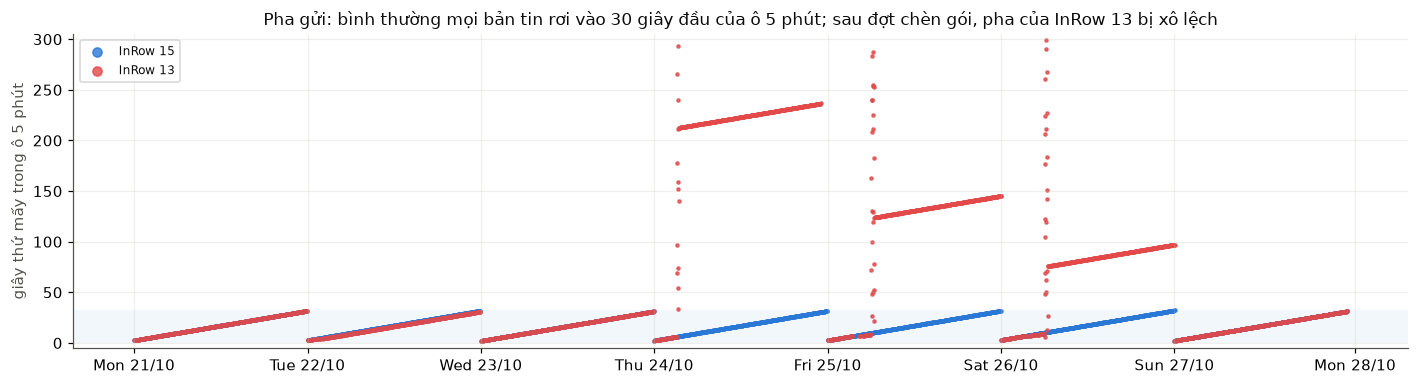

In [21]:
fig, ax = plt.subplots(figsize=(13, 3.6))
for inrow, col in [(15, SERIES[0]), (13, ALERT)]:
    x = pubs[(pubs.inrow == inrow) & (pubs.sensor == "TAS")]
    ax.scatter(x.time, x.ts % 300, s=4, color=col, label=f"InRow {inrow}", alpha=0.8)
ax.axhspan(0, 33, color=SERIES[0], alpha=0.06, lw=0)
ax.set_ylabel("giây thứ mấy trong ô 5 phút"); ax.set_ylim(-5, 305)
ax.set_title("Pha gửi: bình thường mọi bản tin rơi vào 30 giây đầu của ô 5 phút; sau đợt chèn gói, pha của InRow 13 bị xô lệch")
ax.legend(fontsize=8, loc="upper left", markerscale=3)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d/%m", tz=TZ))
plt.tight_layout(); save(fig, "C1_pha_gui_trong_slot"); plt.show()

- **Chu kỳ 300,1 giây**, mọi khoảng cách giữa 2 bản tin bình thường lệch nhau cỡ **mili-giây**, chưa bao giờ quá 1 giây. Vì vậy quy tắc theo nhịp gửi (D1 im lặng, D2 gửi dồn) gần như không thể báo giả trên DAD.
- **16 cảm biến gửi gần như cùng một khoảnh khắc**: 4 cảm biến của một tủ lệch nhau dưới 1 ms (trung vị), các tủ lệch nhau dưới 0,35 giây. Mọi bản tin bình thường rơi vào **30 giây đầu của mỗi ô 5 phút**, vì phiên nào cũng bắt đầu lúc 00:00:02 và chu kỳ dài hơn 300 s đúng 0,1 s (mỗi ngày pha trôi khoảng 29 giây).
- **Hệ quả khi gom theo ô 5 phút:** gom 4 cảm biến vào cùng ô là an toàn với dữ liệu bình thường. Nhưng **sau đợt chèn gói (thứ Năm trở đi), pha của InRow 13 bị xô lệch** tới sát ranh giới ô: một ô có thể có 2 bản tin, ô kế tiếp có 0. Các quy tắc so khoảng cách giữa 2 bản tin liên tiếp (D1, D2) không bị ảnh hưởng; các quy tắc gom theo ô (D4 theo tủ, độ đầy đủ, bất biến vật lý) phải chịu được ô rỗng.
- **Tra file gốc:** bảng T2 trong [`KIEM_CHUNG_DU_LIEU_GOC.md`](../KIEM_CHUNG_DU_LIEU_GOC.md) (cả 16 cảm biến gửi trong cùng giây 00:10:02 thứ Hai).
- **Hệ quả khi phát lại dữ liệu:** phải giữ nguyên khoảng cách gốc giữa các bản tin, không "làm tròn" về lịch 5 phút đều; làm tròn sẽ xoá mất dấu hiệu chèn gói.

## Giá trị nhiệt độ: mức nào, dao động bao nhiêu, có chu kỳ ngày không

In [22]:
prof = (pubs[CLEAN].groupby(["sensor", "inrow"]).value
        .agg(TB="mean", độ_lệch_chuẩn="std", p01=lambda s: s.quantile(.01), p99=lambda s: s.quantile(.99), min="min", max="max").round(2))
prof["thật: TB"] = [REAL_TABLE1[(i, s)][0] for s, i in prof.index]
prof["thật: độ lệch chuẩn"] = [REAL_TABLE1[(i, s)][1] for s, i in prof.index]
prof = prof.reindex(SENSORS, level=0)
fact("độ lệch chuẩn DAD mọi cảm biến trong 0,29–0,38 °C", bool(prof["độ_lệch_chuẩn"].between(0.29, 0.38).all()), True)
fact("giá trị nhỏ nhất / lớn nhất cả dataset (°C)", (float(pubs.value.min()), float(pubs.value.max())), (8.67, 29.4))
prof

TB  độ_lệch_chuẩn    p01    p99    min    max  thật: TB  thật: độ lệch chuẩn
sensor inrow                                                                                 
TFEU   13     11.91           0.36  11.08  13.79   9.94  14.12     11.94                 0.93
       15     11.68           0.37  10.71  12.95   9.49  13.96     11.69                 0.98
       23     11.13           0.36  10.15  12.39   8.86  13.40     11.14                 1.00
       25     11.24           0.34  10.27  12.35   8.93  13.51     11.24                 1.00
TFSU   13     15.87           0.35  15.04  17.76  13.89  18.05     15.89                 0.79
       15     15.36           0.37  14.43  16.63  13.15  17.67     15.37                 0.89
       23     14.95           0.36  13.96  16.17  12.71  17.21     14.95                 0.88
       25     15.34           0.34  14.42  16.44  13.09  17.61     15.34                 0.88
TAS    13     20.02           0.32  19.25  21.96  18.03  22.05     20.00                 0.38
       15     20.00           0.32  18.98  21.06  17.92  22.05     20.00                 0.42
       23     20.00           0.32  18.98  21.04  17.93  22.07     20.00                 0.34
       25     20.01           0.30  19.04  21.02  17.91  22.07     20.00                 0.37
TAR    13     27.37           0.33  26.59  29.34  25.31  29.40     27.33                 0.24
       15     27.20           0.33  26.23  28.27  25.09  29.26     27.20                 0.25
       23     26.29           0.33  25.33  27.35  24.16  28.37     26.29                 0.27
       25     26.79           0.30  25.85  27.81  24.72  28.88     26.79                 0.22

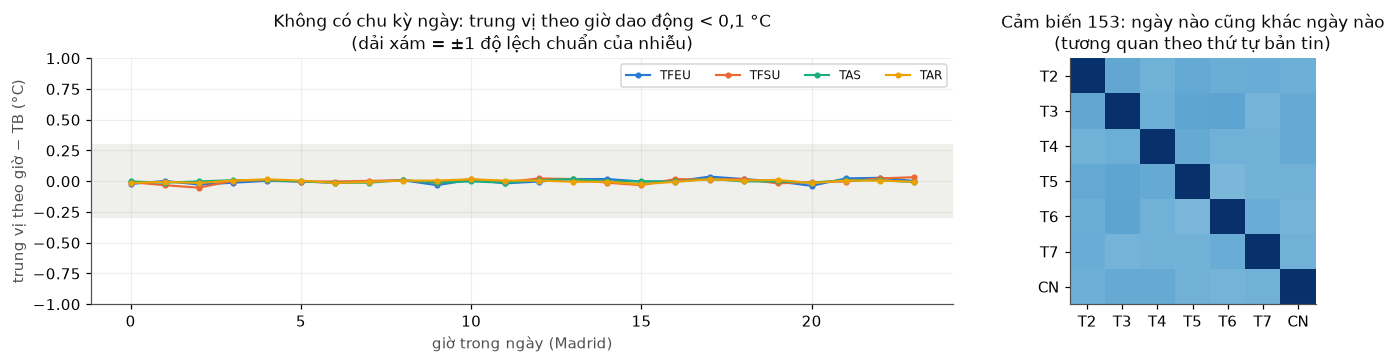

Biên độ của trung vị theo giờ (°C): {'TFEU': 0.07, 'TFSU': 0.08, 'TAS': 0.03, 'TAR': 0.04}


In [23]:
cl = pubs[CLEAN].copy(); cl["giờ"] = cl.time.dt.hour
hourly = cl.groupby(["sensor", "giờ"]).value.median().unstack(0)[SENSORS]
amp = (hourly.max() - hourly.min()).round(2)
wday = pubs[pubs.client_id == "153"].assign(k=lambda d: d.groupby("day", observed=True).cumcount())
cmat = wday.pivot_table(index="k", columns="day", values="value", observed=True).corr()
off_diag = cmat.values[~np.eye(len(cmat), dtype=bool)]
fact("biên độ trung vị theo giờ trong ngày, lớn nhất (°C)", float(amp.max()), 0.08, tol=0.005)
fact("biên độ theo giờ < 0,1 °C (không có chu kỳ ngày)", bool(amp.max() < 0.1), True)
fact("tương quan giữa các ngày < 0,1 (|r| lớn nhất)", bool(np.abs(off_diag).max() < 0.1), True)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4), gridspec_kw={"width_ratios": [2, 1]})
for i, s in enumerate(SENSORS):
    axes[0].plot(hourly.index, hourly[s] - hourly[s].mean(), color=SERIES[i], marker="o", ms=3, label=s)
axes[0].axhspan(-0.3, 0.3, color=GRID, alpha=0.25, lw=0); axes[0].set_ylim(-1, 1)
axes[0].set_xlabel("giờ trong ngày (Madrid)"); axes[0].set_ylabel("trung vị theo giờ − TB (°C)")
axes[0].set_title("Không có chu kỳ ngày: trung vị theo giờ dao động < 0,1 °C\n(dải xám = ±1 độ lệch chuẩn của nhiễu)")
axes[0].legend(ncol=4, fontsize=8)
axes[1].imshow(cmat.values, cmap="Blues", vmin=-1, vmax=1); axes[1].grid(False)
axes[1].set_xticks(range(7)); axes[1].set_xticklabels([DAY_VI[d][:2] for d in cmat.columns]); axes[1].set_yticks(range(7)); axes[1].set_yticklabels([DAY_VI[d][:2] for d in cmat.index])
axes[1].set_title("Cảm biến 153: ngày nào cũng khác ngày nào\n(tương quan theo thứ tự bản tin)")
plt.tight_layout(); save(fig, "C2_khong_co_chu_ky_ngay"); plt.show()
print("Biên độ của trung vị theo giờ (°C):", amp.to_dict())

- **Mỗi cảm biến dao động quanh một mức gần như cố định**, độ lệch chuẩn ≈ 0,3 °C, kể cả hai cảm biến nước. Dữ liệu đo thật dao động mạnh hơn nhiều ở cảm biến nước (≈ 0,9 °C): DAD **đều hơn** dữ liệu thật. *Hai cột "thật" lấy từ [1] Table 1 ("Statistical information"), đã đối chiếu đủ 16 dòng.*
- **Không có chu kỳ ngày, không có xu hướng:** trung vị theo từng giờ chỉ xê dịch dưới 0,1 °C, và chuỗi của các ngày không tương quan gì với nhau. Thực chất DAD là **nhiễu dừng quanh một mức cố định**.
- **Hệ quả:**
  - baseline đơn giản (trung vị 1 ngày trước đó) là đủ; không cần mô hình mùa vụ;
  - mô hình phát hiện bất thường giả định mùa vụ (ngày/tuần) không có gì để học trên DAD;
  - một ngày là đủ để "làm nóng" baseline khi demo.
- Độ phân giải 0,01 °C; toàn bộ dataset nằm trong 8,67–29,4 °C.

## Cấu trúc giữa các cảm biến và giữa các tủ

In [24]:
w_all = pubs.pivot_table(index=["inrow", "slot"], columns="sensor", values="value", aggfunc="first").dropna()
margins = pd.Series({"TFSU − TFEU": (w_all.TFSU - w_all.TFEU).min(), "TAS − TFSU": (w_all.TAS - w_all.TFSU).min(),
                     "TAR − TAS": (w_all.TAR - w_all.TAS).min()}).round(2)
viol = int((~((w_all.TFEU < w_all.TFSU) & (w_all.TFSU < w_all.TAS) & (w_all.TAS < w_all.TAR))).sum())
fact("vi phạm thứ tự vật lý trên toàn bộ dữ liệu (kể cả lúc tấn công)", viol, 0)
fact("khoảng cách nhỏ nhất giữa 2 mức liên tiếp (°C)", float(margins.min()), 3.53, tol=0.005)
w_clean = pubs[CLEAN].pivot_table(index=["inrow", "slot"], columns="sensor", values="value", aggfunc="first").dropna()
offs = pd.DataFrame({"TFSU − TFEU": w_clean.TFSU - w_clean.TFEU, "TAS − TFSU": w_clean.TAS - w_clean.TFSU, "TAR − TAS": w_clean.TAR - w_clean.TAS})
offs_tab = offs.groupby(level=0).agg(["mean", "std"]).round(2)
cyc = pubs[CLEAN].assign(k=lambda d: d.groupby(["client_id", "day"], observed=True).cumcount())
ac = []
for (inrow, day), gg in cyc[cyc.inrow != 13].groupby(["inrow", "day"], observed=True):
    s = gg.pivot_table(index="k", columns="sensor", values="value").pipe(lambda w: w.TAS - w.TFSU)
    ac.append({"tủ": inrow, "ngày": day, **{f"trễ {l}": s.autocorr(l) for l in (1, 3, 6, 12, 24)}})
ac = pd.DataFrame(ac)
fact("hiệu giữa cảm biến lặp lại mỗi 12 bản tin: tự tương quan trễ 12 (trung vị theo ngày)", round(ac["trễ 12"].median(), 2), 0.99, tol=0.02)
print("Khoảng cách nhỏ nhất giữa 2 mức liên tiếp trên toàn bộ dữ liệu (°C):", margins.to_dict(), "| số slot vi phạm:", viol)
print("Tự tương quan của (TAS − TFSU) trong từng ngày, trung vị qua 3 tủ sạch × 7 ngày:",
      ac[[c for c in ac.columns if c.startswith("trễ")]].median().round(2).to_dict())
s0 = cyc[(cyc.inrow == 15) & (cyc.day == "mon")].pivot_table(index="k", columns="sensor", values="value").pipe(lambda w: w.TAS - w.TFSU)
print("Ví dụ InRow 15 thứ Hai, 24 giá trị đầu của TAS − TFSU:", s0.round(2).values[:24].tolist())
print("\nĐộ lệch giữa các cảm biến trong cùng tủ (ngày sạch), TB và độ lệch chuẩn (°C):"); offs_tab

Khoảng cách nhỏ nhất giữa 2 mức liên tiếp trên toàn bộ dữ liệu (°C): {'TFSU − TFEU': 3.53, 'TAS − TFSU': 3.91, 'TAR − TAS': 6.08} | số slot vi phạm: 0
Tự tương quan của (TAS − TFSU) trong từng ngày, trung vị qua 3 tủ sạch × 7 ngày: {'trễ 1': 0.37, 'trễ 3': -0.29, 'trễ 6': -0.18, 'trễ 12': 0.99, 'trễ 24': 0.99}
Ví dụ InRow 15 thứ Hai, 24 giá trị đầu của TAS − TFSU: [4.57, 4.52, 4.53, 4.53, 4.46, 4.48, 4.53, 4.55, 4.57, 4.52, 4.52, 4.57, 4.57, 4.52, 4.53, 4.53, 4.46, 4.48, 4.54, 4.55, 4.57, 4.52, 4.52, 4.57]

Độ lệch giữa các cảm biến trong cùng tủ (ngày sạch), TB và độ lệch chuẩn (°C):


TFSU − TFEU       TAS − TFSU       TAR − TAS      
             mean   std       mean   std      mean   std
inrow                                                   
13           3.95  0.02       4.16  0.12      7.34  0.07
15           3.68  0.06       4.64  0.18      7.20  0.08
23           3.81  0.04       5.06  0.16      6.29  0.08
25           4.09  0.05       4.67  0.17      6.79  0.08

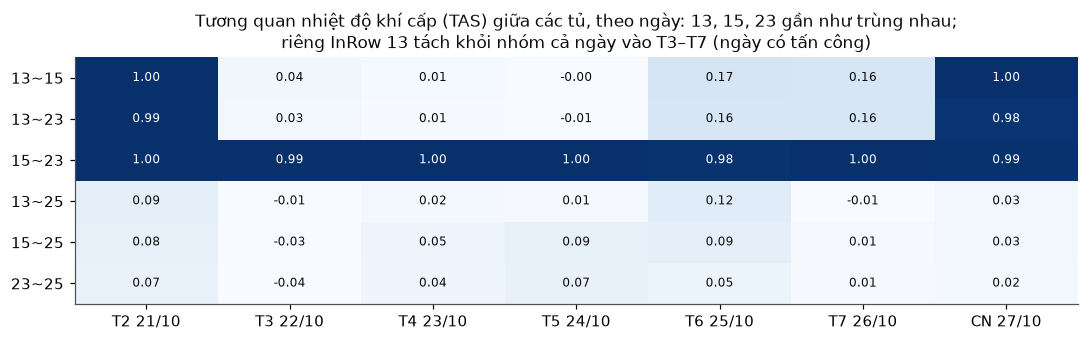

,13~15,13~23,15~23,13~25,15~25,23~25
T2 21/10,0.998,0.995,0.997,0.086,0.082,0.067
T3 22/10,0.036,0.027,0.995,-0.011,-0.034,-0.039
T4 23/10,0.015,0.007,0.998,0.016,0.050,0.043
T5 24/10,-0.004,-0.011,0.997,0.009,0.085,0.075
T6 25/10,0.170,0.159,0.985,0.115,0.090,0.054
T7 26/10,0.161,0.162,0.997,-0.014,0.010,0.008
CN 27/10,0.996,0.981,0.989,0.029,0.025,0.018


In [25]:
tas = pubs[pubs.sensor == "TAS"].pivot_table(index="slot", columns="inrow", values="value", aggfunc="first")
tas["day"] = pubs[pubs.sensor == "TAS"].groupby("slot").day.first()
pairs = [(13, 15), (13, 23), (15, 23), (13, 25), (15, 25), (23, 25)]
twin = pd.DataFrame({f"{a}~{b}": tas.groupby("day", observed=True).apply(lambda g: g[a].corr(g[b])) for a, b in pairs}).round(3)
twin.index = [DAY_VI[d] for d in twin.index]
fact("tương quan TAS 13~15 ngày thứ Hai", float(twin.loc["T2 21/10", "13~15"]), 0.998, tol=0.002)
fact("tương quan TAS 13~15 T3–T7 < 0,2", bool((twin.iloc[1:6]["13~15"].abs() < 0.2).all()), True)
fact("tương quan TAS 15~23 mọi ngày > 0,98", bool((twin["15~23"] > 0.98).all()), True)
fact("InRow 25 độc lập với các tủ khác (|r| < 0,15 mọi ngày)", bool((twin[["13~25", "15~25", "23~25"]].abs() < 0.15).all().all()), True)
fig, ax = plt.subplots(figsize=(10, 3.2))
im = ax.imshow(twin.T.values, cmap="Blues", vmin=0, vmax=1, aspect="auto"); ax.grid(False)
for i in range(twin.shape[1]):
    for j in range(twin.shape[0]):
        v = twin.T.values[i, j]; ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.6 else INK)
ax.set_xticks(range(len(twin))); ax.set_xticklabels(twin.index); ax.set_yticks(range(len(pairs))); ax.set_yticklabels(twin.columns)
ax.set_title("Tương quan nhiệt độ khí cấp (TAS) giữa các tủ, theo ngày: 13, 15, 23 gần như trùng nhau;\nriêng InRow 13 tách khỏi nhóm cả ngày vào T3–T7 (ngày có tấn công)")
plt.tight_layout(); save(fig, "C3_tuong_quan_giua_cac_tu"); plt.show()
twin

In [26]:
real_corr = {("TFEU", "TFSU"): .97, ("TFEU", "TAS"): .617, ("TFEU", "TAR"): .452, ("TFSU", "TAS"): .516, ("TFSU", "TAR"): .587, ("TAS", "TAR"): .234}
w25 = pubs[CLEAN & (pubs.inrow == 25)].pivot_table(index="slot", columns="sensor", values="value", aggfunc="first")
pd.DataFrame([(f"{a} – {b}", r, round(w25[a].corr(w25[b]), 3)) for (a, b), r in real_corr.items()],
             columns=["cặp cảm biến (InRow 25)", "dữ liệu thật (Hình 3 bài báo)", "DAD"])

,cặp cảm biến (InRow 25),dữ liệu thật (Hình 3 bài báo),DAD
0,TFEU – TFSU,0.970,0.990
1,TFEU – TAS,0.617,0.885
2,TFEU – TAR,0.452,0.897
3,TFSU – TAS,0.516,0.871
4,TFSU – TAR,0.587,0.912
5,TAS – TAR,0.234,0.967


**Trong một tủ:**
- Thứ tự vật lý **TFEU < TFSU < TAS < TAR đúng 100%**, kể cả lúc bị tấn công, với khoảng cách rất rộng (ít nhất 3,5 °C). Kiểm tra này **không bắt được gì trong DAD**, vì tấn công trừ đều cả 4 cảm biến; nó chỉ có ích khi **một cảm biến lẻ** hỏng (ngoài đời có, DAD không có). Vẫn nên giữ: rẻ, dễ giải thích.
- 4 cảm biến của một tủ gần như là **một chuỗi chung cộng độ lệch cố định** (độ lệch chuẩn của hiệu 0,02–0,18 °C, tương quan ≥ 0,87). Ngoài đời không như vậy: chỉ cặp nước vào–nước ra liên quan chặt (0,97), khí hồi gần như độc lập với khí cấp (0,23) (dữ liệu thật: [1] Hình 3, InRow 25).
- Phần dao động nhỏ còn lại của các hiệu đó **lặp lại y hệt mỗi 12 bản tin (đúng 1 giờ)**: tự tương quan ở trễ 12 ≈ 0,99 trong khi ở trễ 1, 3, 6 thì thấp. Đây là một mẫu lặp theo chu kỳ của dữ liệu, không có ý nghĩa vật lý, không dùng làm tín hiệu.

**Giữa các tủ (phát hiện quan trọng, cũng là một điểm dễ hiểu nhầm):**
- InRow 13, 15, 23 có nhiệt độ **gần như trùng nhau** (tương quan ≈ 0,99). InRow 25 độc lập hoàn toàn.
- **Từ thứ Ba đến thứ Bảy, InRow 13 tách khỏi nhóm cả ngày** (tương quan ≈ 0), kể cả những giờ không có tấn công. Nói cách khác, vào các ngày bị tấn công, cả chuỗi nhiệt độ của InRow 13 khác hẳn hai tủ còn lại, không chỉ trong cửa sổ tấn công.
- **Hệ quả:** quy tắc kiểu "so tủ này với tủ bên cạnh" sẽ báo động InRow 13 **suốt cả ngày** thứ Ba đến thứ Bảy. Nó trông như bắt được tấn công, nhưng thực ra báo cả những giờ InRow 13 hoàn toàn bình thường. **Không dùng so sánh giữa các tủ làm bộ phát hiện.** Ngoài đời, so sánh nhóm vẫn có giá trị (các tủ dùng chung vòng nước lạnh), nhưng DAD không kiểm chứng được.

## Nhiễu: gai đơn lẻ, đối xứng, không kéo dài

In [27]:
c = pubs[CLEAN & pubs.dev.notna()].sort_values(["client_id", "ts"])
step = c.groupby("client_id").value.diff().abs().dropna()
run = c.assign(o=c.dev.abs() > dm.DEV_T).groupby("client_id").o.apply(lambda s: s.groupby((~s).cumsum()).sum().max())
same = c.groupby("client_id").value.apply(lambda s: s.groupby((s != s.shift()).cumsum()).size().max())
noise = pd.Series({"|Δ| giữa 2 bản tin liên tiếp: p50 (°C)": round(step.quantile(.5), 2), "p95": round(step.quantile(.95), 2),
                   "p99": round(step.quantile(.99), 2), "max": round(step.max(), 2),
                   "số bản tin lệch baseline > +1 °C": int((c.dev > 1).sum()), "số bản tin lệch baseline < −1 °C": int((c.dev < -1).sum()),
                   "chuỗi dài nhất |dev| > 0,8 °C liên tiếp (bản tin)": int(run.max()),
                   "chuỗi dài nhất cùng một giá trị (bản tin)": int(same.max())}, name="dữ liệu sạch")
fact("chuỗi dài nhất |dev| > 0,8 °C liên tiếp ở dữ liệu sạch", int(run.max()), 2)
fact("chuỗi dài nhất giá trị đứng yên ở dữ liệu sạch", int(same.max()), 4)
noise.to_frame()

,dữ liệu sạch
|Δ| giữa 2 bản tin liên tiếp: p50 (°C),0.11
p95,0.91
p99,2.05
max,4.10
số bản tin lệch baseline > +1 °C,314.00
số bản tin lệch baseline < −1 °C,254.00
"chuỗi dài nhất |dev| > 0,8 °C liên tiếp (bản tin)",2.00
chuỗi dài nhất cùng một giá trị (bản tin),4.00


- Dữ liệu sạch có **gai đơn lẻ ±1–2 °C** (p99 của bước nhảy ≈ 2 °C), **đối xứng** lên và xuống, và **không bao giờ kéo dài quá 2 bản tin liền**.
- **Hệ quả cho ngưỡng:**
  - không được báo động dựa trên **một điểm** đơn lẻ: sẽ báo giả liên tục;
  - quy tắc giá trị phải đòi hỏi **nhiều chu kỳ**: D4 đòi ít nhất **3 trong 6 chu kỳ** lệch âm, đúng một bậc trên mức nhiễu dài nhất (2);
  - quy tắc "cảm biến đứng giá trị" đặt ở 12 bản tin liền (1 giờ), xa hơn nhiều so với mức dài nhất của dữ liệu sạch.

## Sức khoẻ tầng mạng: sạch tuyệt đối

In [28]:
ack = net[net.mtype == 4][["conn", "msgid", "ts"]].rename(columns={"ts": "ack_ts"})
pa = net[net.mtype == 3][["day", "frame", "ts", "conn", "src", "msgid"]].merge(ack, on=["conn", "msgid"], how="left")
pa["puback_ms"] = (pa.ack_ts - pa.ts) * 1000
lat = pa.groupby("src").puback_ms.describe(percentiles=[.5, .99]).round(2)[["count", "50%", "99%", "max"]]
lat.index = [f"InRow {INROW_IP[i]}" for i in lat.index]
un = pa[pa.ack_ts.isna()]
un_t = pd.to_datetime(un.ts, unit="s", utc=True).dt.tz_convert(TZ)
tcp = net[(net.proto == "TCP") & (net.plen > 0)]
retx = int(tcp.duplicated(["src", "sport", "dst", "dport", "seq", "plen"]).sum())
ntp = net[(net.proto == "UDP") & (net.dport == 123) & (net.src != BROKER_IP)].sort_values("ts")
ntp_period = ntp.groupby("src").ts.diff().median()
fact("PUBLISH không được PUBACK", len(un), 20)
fact("PUBLISH không được PUBACK đều trong khung 00:00–00:03", bool(((un_t.dt.hour == 0) & (un_t.dt.minute < 3)).all()), True)
fact("TCP retransmission", retx, 0)
print(f"PUBLISH không có PUBACK: {len(un)}, lúc {sorted(un_t.dt.strftime('%a %H:%M:%S').unique())}")
print(f"TCP retransmission: {retx} | chu kỳ NTP trung vị: {ntp_period:.0f} s (≈ {ntp_period / 60:.1f} phút)")
print("\nĐộ trễ PUBLISH → PUBACK của broker (ms):"); lat

PUBLISH không có PUBACK: 20, lúc ['Sat 00:02:25', 'Sun 00:00:32', 'Sun 00:01:37']
TCP retransmission: 0 | chu kỳ NTP trung vị: 1057 s (≈ 17.6 phút)

Độ trễ PUBLISH → PUBACK của broker (ms):


,count,50%,99%,max
InRow 25,8064.0,0.17,0.45,1.39
InRow 15,8064.0,0.13,0.63,3.65
InRow 13,8076.0,0.18,0.63,2.76
InRow 23,8064.0,0.17,0.62,2.79


- Broker trả PUBACK sau **0,1–0,2 ms** (trung vị), p99 ≈ 0,6 ms. Mạng rất sạch: không có retransmission.
- **Tra file gốc:** bảng T8 trong [`KIEM_CHUNG_DU_LIEU_GOC.md`](../KIEM_CHUNG_DU_LIEU_GOC.md) (đủ 20 bản tin, kèm số frame).
- **20 PUBLISH không được ACK**, đều rơi vào khung **00:00–00:03** (thiết bị còn gửi trên kết nối cũ ngay trước khi kết nối lại). Đây là hiện tượng bình thường của đợt chuyển ngày, không phải tấn công.
- **Hệ quả:** trong DAD, mọi bất thường nằm ở **tầng ứng dụng** (giá trị, nhịp gửi). Tầng mạng không có sự cố hạ tầng nào để học: DAD không chứa tình huống "đường truyền dữ liệu chậm" hay "hệ thống thu thập lỗi".

> **Thông điệp (Phần “Hành vi bình thường”).** Bình thường của DAD **rất dễ đoán**: mỗi cảm biến gửi đúng 300,1 giây một lần, 16 cảm biến gửi cùng lúc, giá trị dao động ±0,3 °C quanh một mức cố định, không có chu kỳ ngày, gai nhiễu không kéo dài quá 2 bản tin. Vì vậy chỉ cần **ít quy tắc đơn giản** là tách được bất thường. Đổi lại, dữ liệu có vài đặc điểm không phản ánh tấn công (cảm biến trong tủ đi cùng nhau, ba tủ gần như trùng nhau), nên **không dùng chúng làm tín hiệu**.

---
# Bất thường: ba kiểu tấn công để lại dấu vết gì

Mọi bất thường trong DAD đến từ **một node: InRow 13** (`10.6.56.41`). Phần này đặt lịch tấn công của README cạnh những gì thật sự thấy trong dữ liệu, mổ xẻ từng kiểu, rồi chốt danh sách 11 cửa sổ sự cố. Mục “Trông như bất thường nhưng không phải” liệt kê những thứ **trông như bất thường nhưng không phải**.

## Lịch tấn công: README nói gì, dữ liệu cho thấy gì

In [29]:
r13 = pubs[pubs.inrow == 13].copy()
r13["early"] = (r13.gap_s < dm.BURST_FACTOR * P) & ~r13.new_conn          # đến sớm hơn 0,8 chu kỳ, cùng kết nối
r13["hole"] = r13.gap_s > dm.SILENCE_FACTOR * P                            # khoảng hở hơn 1,5 chu kỳ
readme = ["không tấn công", "xoá một số gói (không gắn nhãn)", "sửa giá trị 4h–6h", "chèn gói < 5 phút lúc 3h",
          "trộn 3 kiểu lúc 6h và 14–16h", "trộn 3 kiểu lúc 6h và 14–16h", "không tấn công"]
week = r13[r13.sensor == "TAS"].groupby("day", observed=True).agg(
    nhãn_1=("label", "sum"), khoảng_hở=("hole", "sum"), đến_sớm=("early", "sum"), bản_tin=("ts", "size"), ô_5_phút_có_dữ_liệu=("slot", "nunique"))
week.insert(0, "README", readme)
week.index = [DAY_VI[d] for d in week.index]
print("InRow 13, tính cho MỘT cảm biến (TAS); 3 cảm biến còn lại y hệt. Bình thường: 288 bản tin, 288 ô.")
week

InRow 13, tính cho MỘT cảm biến (TAS); 3 cảm biến còn lại y hệt. Bình thường: 288 bản tin, 288 ô.


,README,nhãn_1,khoảng_hở,đến_sớm,bản_tin,ô_5_phút_có_dữ_liệu
T2 21/10,không tấn công,0,0,0,288,288
T3 22/10,xoá một số gói (không gắn nhãn),0,5,0,278,278
T4 23/10,sửa giá trị 4h–6h,26,0,0,288,288
T5 24/10,chèn gói < 5 phút lúc 3h,14,0,14,288,277
T6 25/10,trộn 3 kiểu lúc 6h và 14–16h,48,5,24,292,273
T7 26/10,trộn 3 kiểu lúc 6h và 14–16h,48,6,24,298,278
CN 27/10,không tấn công,0,0,0,289,288


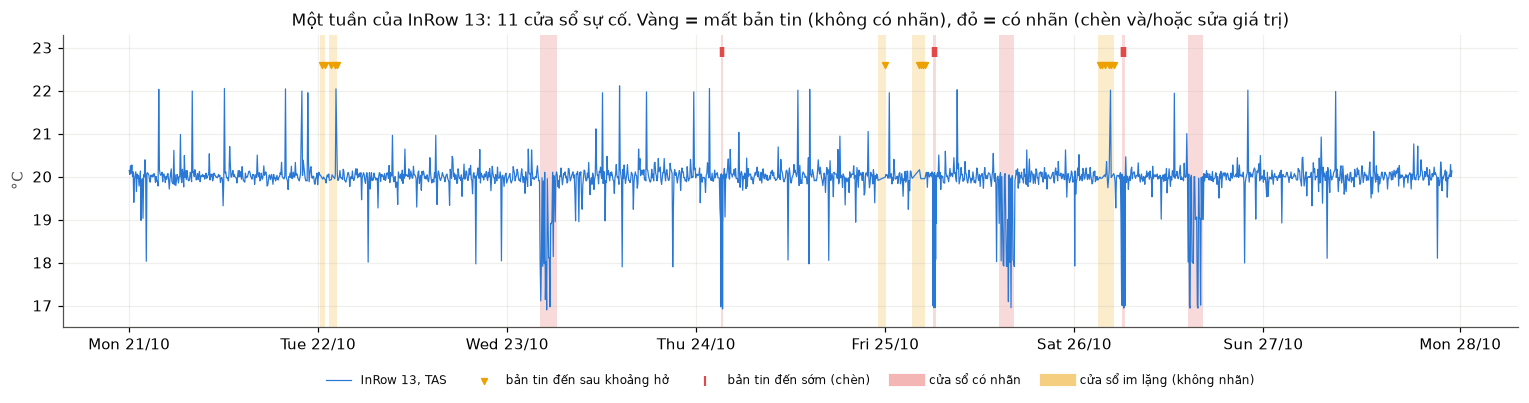

In [30]:
fig, ax = plt.subplots(figsize=(14, 3.8))
g = r13[r13.sensor == "TAS"]
ax.plot(g.time, g.value, color=SERIES[0], lw=0.8, label="InRow 13, TAS")
for _, w in gt.iterrows():
    ax.axvspan(w.start, w.end, color=ALERT if w.kind == "labeled" else SERIES[3], alpha=0.2, lw=0)
h = g[g.hole]; ax.scatter(h.time, np.full(len(h), 22.6), marker="v", s=14, color=SERIES[3], zorder=3, label="bản tin đến sau khoảng hở")
e = g[g.early]; ax.scatter(e.time, np.full(len(e), 22.9), marker="|", s=40, color=ALERT, zorder=3, label="bản tin đến sớm (chèn)")
ax.plot([], [], color=ALERT, alpha=0.4, lw=8, label="cửa sổ có nhãn"); ax.plot([], [], color=SERIES[3], alpha=0.5, lw=8, label="cửa sổ im lặng (không nhãn)")
ax.set_ylabel("°C"); ax.set_ylim(16.5, 23.3)
ax.legend(ncol=5, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
ax.set_title("Một tuần của InRow 13: 11 cửa sổ sự cố. Vàng = mất bản tin (không có nhãn), đỏ = có nhãn (chèn và/hoặc sửa giá trị)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d/%m", tz=TZ))
plt.tight_layout(); save(fig, "D1_mot_tuan_inrow13"); plt.show()

*Nguồn của cột README: README của repo gốc [2]; bài báo ghi cùng lịch ở [1] mục 5.*

README đúng ở nét lớn nhưng **thiếu nhiều chi tiết**, và dữ liệu cho thấy rõ hơn:
- **Thứ Ba:** mất bản tin trong 2 đợt rạng sáng (00:15–00:55, 01:25–02:25), không có nhãn.
- **Thứ Tư:** chỉ sửa giá trị, 04:10–06:15; nhịp gửi không đổi.
- **Thứ Năm:** chèn bản tin 03:05–03:22; **và** im lặng từ 23:03 đến hết ngày, điều README không nhắc (mục “Mất bản tin”).
- **Thứ Sáu, thứ Bảy:** ngoài "6h và 14–16h" như README, còn **mất bản tin rạng sáng (03:00–05:00)**. Lúc 6h là chèn bản tin (kèm giá trị thấp), lúc 14–16h là sửa giá trị.
- **Đếm bản tin dễ đánh lừa:** thứ Năm InRow 13 có **đúng 288 bản tin**, trông như hoàn hảo, nhưng chỉ **277/288 ô 5 phút** có dữ liệu (bản tin chèn bù vào chỗ bản tin mất). Thứ Sáu có 292 bản tin (> 288) mà chỉ 273 ô có dữ liệu.

In [31]:
fact("InRow 13 thứ Năm: số bản tin mỗi cảm biến", int(week.loc["T5 24/10", "bản_tin"]), 288)
fact("InRow 13 thứ Năm: số ô 5 phút có dữ liệu", int(week.loc["T5 24/10", "ô_5_phút_có_dữ_liệu"]), 277)
fact("InRow 13 thứ Sáu: số bản tin / số ô", (int(week.loc["T6 25/10", "bản_tin"]), int(week.loc["T6 25/10", "ô_5_phút_có_dữ_liệu"])), (292, 273))

(292, 273)

## Mất bản tin: chặn gói, và một khoảng im lặng không phải chặn gói

In [32]:
disc = net[(net.mtype == 14) & (net.src == "10.6.56.41")]
rows = []
for i, w in gt[gt.kind == "interception"].iterrows():
    x = r13[(r13.time_utc > w.start) & (r13.time_utc <= w.end + pd.Timedelta("1s")) & r13.hole]
    lost = ((x.gap_s / P).round() - 1).groupby(x.client_id).sum()
    d_in = disc[(disc.ts > w.start.timestamp()) & (disc.ts < w.end.timestamp())]
    rows.append({"cửa sổ": w.local, "khoảng hở / cảm biến": len(x) // 4, "bản tin mất / cảm biến": int(lost.iloc[0]),
                 "4 cảm biến mất như nhau": bool(lost.nunique() == 1 and len(lost) == 4),
                 "hở dài nhất (phút)": round(x.gap_s.max() / 60, 1),
                 "DISCONNECT trong cửa sổ": len(d_in) // 4 if len(d_in) else 0,
                 "nguyên nhân": "node gửi xong phiên rồi tự ngắt kết nối sớm" if len(d_in) else "bản tin bị xoá giữa phiên (chặn gói)",
                 "ngày": w.start.tz_convert(TZ).strftime("%a")})
inter = pd.DataFrame(rows).set_index("cửa sổ")
ka_days = sorted(con[con.keepalive == 18000].day.astype(str).map(lambda d: d.capitalize()).unique())
fact("mỗi lần mất bản tin, cả 4 cảm biến mất như nhau", bool(inter["4 cảm biến mất như nhau"].all()), True)
fact("số cửa sổ chặn gói giữa phiên", int((inter["DISCONNECT trong cửa sổ"] == 0).sum()), 4)
fact("ngày chặn gói giữa phiên = ngày keepalive 18000", sorted(inter[inter["DISCONNECT trong cửa sổ"] == 0].ngày.unique()), ka_days)
inter.drop(columns="ngày")

,khoảng hở / cảm biến,bản tin mất / cảm biến,4 cảm biến mất như nhau,hở dài nhất (phút),DISCONNECT trong cửa sổ,nguyên nhân
cửa sổ,,,,,,
Tue 22/10 00:15–00:55,2,4,True,15.0,0,bản tin bị xoá giữa phiên (chặn gói)
Tue 22/10 01:25–02:25,3,6,True,20.0,0,bản tin bị xoá giữa phiên (chặn gói)
Thu 24/10 23:03–00:00,1,10,True,56.1,1,node gửi xong phiên rồi tự ngắt kết nối sớm
Fri 25/10 03:25–05:00,4,15,True,55.0,0,bản tin bị xoá giữa phiên (chặn gói)
Sat 26/10 03:00–05:00,6,10,True,20.0,0,bản tin bị xoá giữa phiên (chặn gói)


In [33]:
thu = net[(net.src == "10.6.56.41") & (net.day == "thu") & (net.ts >= pd.Timestamp("2019-10-24 21:00", tz="UTC").timestamp())]
thu = thu.assign(giờ=local(pd.to_datetime(thu.ts, unit="s", utc=True), "%H:%M:%S"),
                 loại=np.where(thu.proto == "UDP", "NTP", thu.mtype.map(mtype_name).fillna("TCP " + thu.tcp_flags.astype(str))))
print("Mọi gói InRow 13 gửi đi sau 23:00 thứ Năm (gộp 4 cảm biến):")
print(thu.groupby(["giờ", "loại"]).agg(số_gói=("ts", "size"), msgid=("msgid", lambda s: sorted(s.dropna().astype(int).unique()))).to_string())
ses13 = net[(net.mtype == 3) & (net.src == "10.6.56.41")].groupby("conn").agg(day=("day", "first"), n=("ts", "size"), last=("msgid", "max"))
fact("phiên thứ Năm của InRow 13 dừng sau đúng 288 bản tin", sorted(ses13[ses13.day == "thu"].n.unique().tolist()), [288])

Mọi gói InRow 13 gửi đi sau 23:00 thứ Năm (gộp 4 cảm biến):
                     số_gói  msgid
giờ      loại                     
23:03:11 NTP              1     []
23:03:56 PUBLISH          4  [288]
         TCP A            4     []
23:08:56 DISCONNECT       4     []
         TCP A            4     []
         TCP FA           4     []
23:20:32 NTP              1     []
23:37:47 NTP              1     []
23:55:20 NTP              1     []


[288]

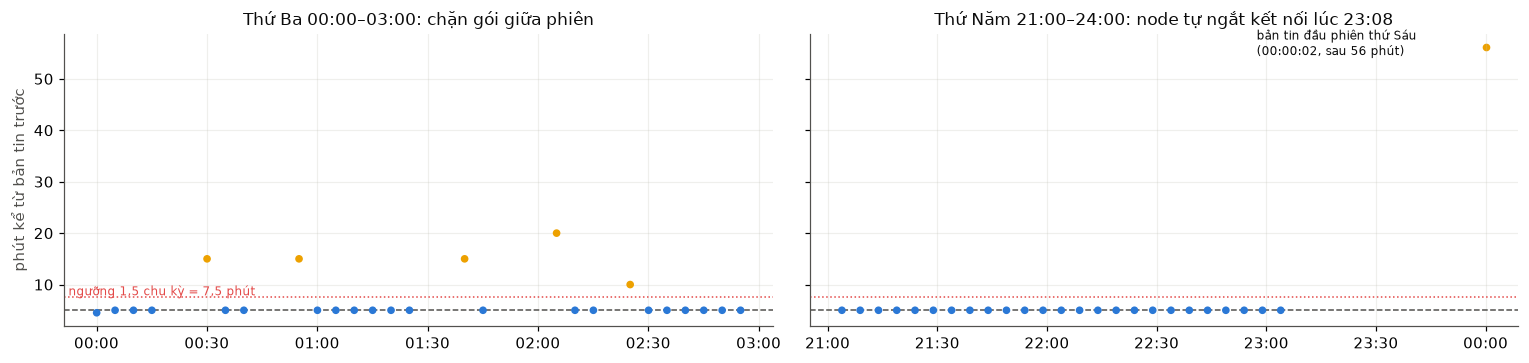

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.4), sharey=True)
for ax, (day, h0, h1, title) in zip(axes, [("tue", 0, 3, "Thứ Ba 00:00–03:00: chặn gói giữa phiên"),
                                           ("thu", 21, 24, "Thứ Năm 21:00–24:00: node tự ngắt kết nối lúc 23:08")]):
    d = r13[(r13.day == day) & (r13.sensor == "TAS") & (r13.time.dt.hour >= h0) & (r13.time.dt.hour < h1)]
    ax.scatter(d.time, d.gap_s / 60, s=16, color=[SERIES[3] if v else SERIES[0] for v in d.hole], zorder=3)
    ax.axhline(5, color=INK2, ls="--", lw=1); ax.axhline(7.5, color=ALERT, ls=":", lw=1)
    ax.set_title(title); ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=TZ))
nxt = r13[(r13.day == "fri") & (r13.sensor == "TAS")].iloc[0]
axes[1].scatter([nxt.time], [nxt.gap_s / 60], s=16, color=SERIES[3]); axes[1].annotate("bản tin đầu phiên thứ Sáu\n(00:00:02, sau 56 phút)", (nxt.time, nxt.gap_s / 60), xytext=(-150, -5), textcoords="offset points", fontsize=8)
axes[0].set_ylabel("phút kể từ bản tin trước"); axes[0].text(axes[0].get_xlim()[0], 7.9, " ngưỡng 1,5 chu kỳ = 7,5 phút", fontsize=8, color=ALERT)
plt.tight_layout(); save(fig, "D2_mat_ban_tin"); plt.show()

**Dấu vết của chặn gói (interception):**
- Bản tin biến mất, khoảng cách tới bản tin kế tiếp nhảy lên **10–20 phút** (2–4 chu kỳ), có lần 55 phút. Mỗi đợt mất 1–3 bản tin liền.
- **Cả 4 cảm biến của tủ mất đúng như nhau**: đây là tấn công vào **node** (đường truyền của cả tủ), không phải 4 sự cố riêng.
- **Không có nhãn**, `msgid` vẫn liên tục, không có gói nào báo lỗi: **chỉ thời gian** cho thấy có chuyện.
- 4 cửa sổ chặn gói thật rơi đúng vào 3 ngày có `keepalive = 18000` (T3, T6, T7), khớp lời giải thích của bài báo ([1] mục 4.1: chặn gói = "randomly deleting some sent packets", phải đổi thời gian chờ để tránh timeout).
- **Tra file gốc:** bảng T6 trong [`KIEM_CHUNG_DU_LIEU_GOC.md`](../KIEM_CHUNG_DU_LIEU_GOC.md): thứ Ba, cảm biến 131, bản tin `msgid` 4 lúc 00:15:03 rồi `msgid` 5 lúc 00:30:03, hở 900 giây.

**Phát hiện mới: khoảng im lặng 23:03–00:00 thứ Năm không phải chặn gói.**
- Lúc 23:03:56, InRow 13 gửi bản tin `msgid = 288`, tức bản tin thứ 288 của phiên. 5 phút sau, cả 4 cảm biến **chủ động gửi DISCONNECT** và đóng kết nối TCP. NTP vẫn chạy đều đến hết ngày: node còn sống, chỉ thôi gửi.
- Giải thích hợp lý nhất: client gửi **288 bản tin mỗi phiên rồi dừng**. Sáng thứ Năm, 13 bản tin chèn (mục “Chèn bản tin”) đã "tiêu" trước hạn mức, nên phiên kết thúc sớm khoảng 52 phút.
- **Tra file gốc:** bảng T7 trong [`KIEM_CHUNG_DU_LIEU_GOC.md`](../KIEM_CHUNG_DU_LIEU_GOC.md) (frame 14097–14100: `msgid` 288; frame 14145–14153: DISCONNECT; frame 14273, 14387, 14501: NTP vẫn chạy). Đây là phát hiện của dự án, bài báo không nhắc.
- Về vận hành, đây vẫn là sự cố "tủ không gửi dữ liệu" (56 phút mù nhiệt độ), và quy tắc im lặng vẫn phải bắt. Nhưng **nguyên nhân khác**, và có dấu hiệu phân biệt: **có DISCONNECT** (thiết bị chủ động dừng) so với **không có gì** (bản tin bị chặn trên đường đi).

## Chèn bản tin (duplication)

In [35]:
e = r13[r13.early].sort_values("ts").copy()
e["đợt"] = (e.ts.diff() > 5).cumsum()
bursts = e.groupby("đợt").agg(t=("time", "first"), cảm_biến=("client_id", "nunique"), lệch_ms=("ts", lambda s: (s.max() - s.min()) * 1000),
                              gap_s=("gap_s", "first"), dev=("dev", "mean"), nhãn=("label", "min"))
fact("số đợt chèn (mỗi đợt cả 4 cảm biến cùng gửi)", int(len(bursts)), 62)
fact("mọi đợt chèn đều đủ 4 cảm biến", bool((bursts.cảm_biến == 4).all()), True)
fact("bản tin đến sớm: tổng / có nhãn 1", (len(e), int(e.label.sum())), (248, 236))
lab_end = gt[gt.kind == "labeled"].end
after = e[e.label == 0].time_utc.apply(lambda t: ((t - lab_end) > pd.Timedelta(0)).any() and ((t - lab_end)[(t - lab_end) > pd.Timedelta(0)].min() < pd.Timedelta("5min")))
fact("bản tin đến sớm không nhãn đều là bản tin đầu tiên ngay sau đợt chèn (< 5 phút sau cửa sổ)", bool(after.all()), True)
fact("số đợt chèn không nhãn (bản tin bình thường bị xô pha)", int((bursts.nhãn == 0).sum()), 3)
fact("khoảng cách giữa các bản tin chèn: nhỏ nhất, lớn nhất (s)", (round(e.gap_s.min()), round(e.gap_s.max())), (30, 104))
dup_win = []
for _, w in gt[gt.kind == "labeled"].iterrows():
    x = r13[(r13.time_utc >= w.start) & (r13.time_utc <= w.end)]
    dup_win.append({"cửa sổ có nhãn": w.local, "bản tin nhãn 1": int(x.label.sum()), "trong đó đến sớm (chèn)": int(x.early.sum()),
                    "trong đó đúng nhịp": int((x.label.eq(1) & ~x.early).sum()),
                    "dev TB bản tin chèn (°C)": round(x[x.early].dev.mean(), 2) if x.early.any() else np.nan,
                    "dev TB bản tin đúng nhịp (°C)": round(x[~x.early & x.label.eq(1)].dev.mean(), 2)})
dup_win = pd.DataFrame(dup_win).set_index("cửa sổ có nhãn")
print(f"{len(bursts)} đợt chèn, mỗi đợt {int(bursts.cảm_biến.min())} cảm biến gửi cùng lúc (lệch tối đa {bursts.lệch_ms.max():.1f} ms); "
      f"khoảng cách {e.gap_s.min():.0f}–{e.gap_s.max():.0f} s (trung vị {e.gap_s.median():.0f} s)")
dup_win

62 đợt chèn, mỗi đợt 4 cảm biến gửi cùng lúc (lệch tối đa 1.6 ms); khoảng cách 30–104 s (trung vị 70 s)


,bản tin nhãn 1,trong đó đến sớm (chèn),trong đó đúng nhịp,dev TB bản tin chèn (°C),dev TB bản tin đúng nhịp (°C)
cửa sổ có nhãn,,,,,
Wed 23/10 04:10–06:15,104,0,104,NaN,-1.29
Thu 24/10 03:05–03:22,56,52,4,-1.40,-1.00
Fri 25/10 06:00–06:25,96,92,4,-1.67,-0.27
Fri 25/10 14:27–16:22,96,0,96,NaN,-1.21
Sat 26/10 06:00–06:25,96,92,4,-1.64,-2.98
Sat 26/10 14:26–16:21,96,0,96,NaN,-1.24


In [36]:
th = r13[(r13.client_id == "131") & (r13.day == "thu")]
th = th[(th.time.dt.hour == 3) & (th.time.dt.minute < 40)]
th.assign(giờ=th.time.dt.strftime("%H:%M:%S"))[["giờ", "msgid", "value", "label", "gap_s", "dev", "early"]].round(2).set_index("giờ")

,msgid,value,label,gap_s,dev,early
giờ,,,,,,
03:00:06,37,11.29,0,300.1,-0.68,False
03:05:06,38,11.05,1,300.1,-0.92,False
03:06:37,39,9.08,1,91.1,-2.89,True
03:07:57,40,12.23,1,80.1,0.26,True
03:09:25,41,12.28,1,88.1,0.31,True
03:11:09,42,10.23,1,104.1,-1.74,True
03:12:38,43,12.22,1,89.1,0.25,True
03:13:59,44,9.21,1,81.1,-2.76,True
03:15:33,45,9.19,1,94.1,-2.78,True


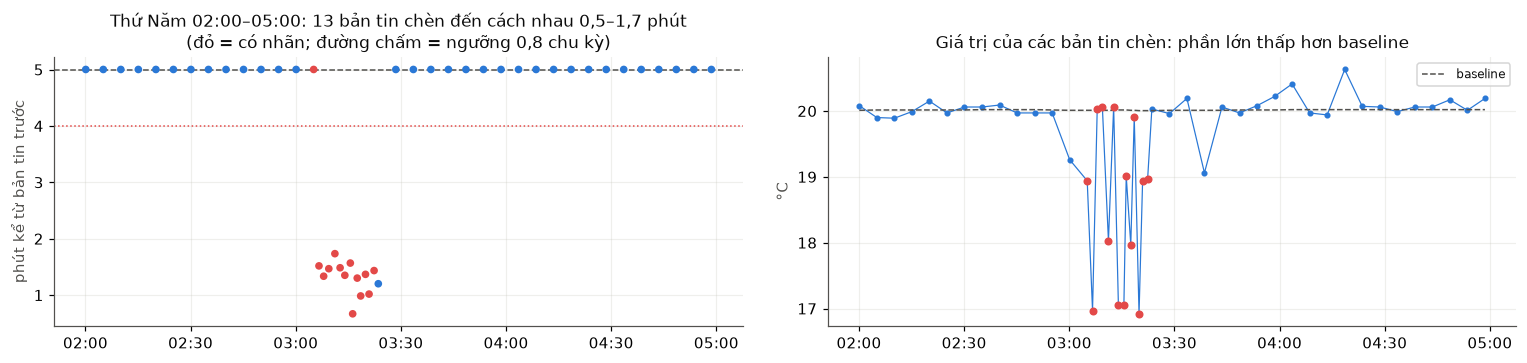

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.4))
d = r13[(r13.day == "thu") & (r13.sensor == "TAS") & (r13.time.dt.hour.between(2, 4))]
axes[0].scatter(d.time, d.gap_s / 60, s=16, color=[ALERT if l else SERIES[0] for l in d.label], zorder=3)
axes[0].axhline(5, color=INK2, ls="--", lw=1); axes[0].axhline(4, color=ALERT, ls=":", lw=1)
axes[0].set_ylabel("phút kể từ bản tin trước"); axes[0].set_title("Thứ Năm 02:00–05:00: 13 bản tin chèn đến cách nhau 0,5–1,7 phút\n(đỏ = có nhãn; đường chấm = ngưỡng 0,8 chu kỳ)")
axes[1].plot(d.time, d.value, color=SERIES[0], marker="o", ms=3, lw=0.8)
dl = d[d.label == 1]; axes[1].scatter(dl.time, dl.value, s=18, color=ALERT, zorder=3)
axes[1].plot(d.time, d.base, color=INK2, ls="--", lw=1, label="baseline"); axes[1].legend(fontsize=8)
axes[1].set_ylabel("°C"); axes[1].set_title("Giá trị của các bản tin chèn: phần lớn thấp hơn baseline")
for a in axes: a.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=TZ))
plt.tight_layout(); save(fig, "D3_chen_ban_tin"); plt.show()

**Dấu vết của chèn bản tin:**
- Mỗi đợt chèn, **cả 4 cảm biến gửi cùng lúc** (62 đợt, lệch nhau dưới 2 ms), cách nhau **30–104 giây** thay vì 300 giây. Bài báo mô tả chèn là "sending more tokens than the number initially planned" ([1] mục 4.1).
- **Tra file gốc:** bảng T4 (chuỗi bản tin của cảm biến 131, 03:00–03:30 thứ Năm) và T5 (một đợt chèn, 4 cảm biến cùng giây) trong [`KIEM_CHUNG_DU_LIEU_GOC.md`](../KIEM_CHUNG_DU_LIEU_GOC.md).
- 248 bản tin đến sớm, **236 có nhãn**. 12 bản tin còn lại (3 đợt × 4 cảm biến) là **bản tin bình thường đầu tiên ngay sau mỗi đợt chèn**: đến sớm 49–72 giây vì pha gửi đã bị xô, giá trị bình thường, không có nhãn. Ngược lại, mỗi cửa sổ chèn có đúng 1 bản tin/cảm biến **mang nhãn nhưng đến đúng nhịp**: bản tin mở đầu đợt.
- Giá trị của bản tin chèn **nhiễu và phần lớn thấp hơn baseline** (dev trung bình −1,4 đến −1,7 °C), nên chèn bản tin cũng mang dấu hiệu "sửa giá trị".
- Sau đợt chèn, **pha gửi bị xô lệch** (bản tin 03:23:32 đến sau 72 giây, từ đó mới quay lại nhịp 300 s), và thứ Năm còn kéo theo việc phiên kết thúc sớm (mục “Mất bản tin”).
- **Tín hiệu đúng là khoảng cách tới bản tin trước trên cùng kết nối**, không phải "lịch gửi dự kiến": lịch dự kiến sẽ coi mọi bản tin sau đợt chèn là lệch pha.

## Sửa giá trị (modification)

In [38]:
wed = r13[r13.day == "wed"]
tab = wed.pivot_table(index=wed.time.dt.strftime("%H:%M"), columns="sensor", values="value", aggfunc="first")[SENSORS]
tab["nhãn"] = wed.groupby(wed.time.dt.strftime("%H:%M")).label.max()
tab["TAR − TAS"] = tab.TAR - tab.TAS
tab["dev TB 4 cảm biến"] = wed.groupby(wed.time.dt.strftime("%H:%M")).dev.mean()
tab.loc["04:00":"05:10"].round(2)

sensor,TFEU,TFSU,TAS,TAR,nhãn,TAR − TAS,dev TB 4 cảm biến
time,,,,,,,
04:00,11.73,15.76,19.90,27.32,0,7.42,-0.16
04:05,11.78,15.76,19.91,27.21,0,7.30,-0.17
04:10,9.96,13.89,18.02,25.29,1,7.27,-2.05
04:15,9.15,13.07,17.11,24.34,1,7.23,-2.92
04:20,10.19,14.12,18.11,25.39,1,7.28,-1.88
04:25,11.96,15.96,19.97,27.39,1,7.42,-0.01
04:30,9.75,13.79,17.91,25.33,1,7.42,-2.14
04:35,11.74,15.76,19.90,27.32,1,7.42,-0.15
04:40,9.88,13.83,17.97,25.29,1,7.32,-2.09


In [39]:
mod_rows, same_level = [], []
for _, w in gt[gt.kind == "labeled"].iterrows():
    x = r13[(r13.time_utc >= w.start) & (r13.time_utc <= w.end) & (r13.label == 1) & ~r13.early]
    if x.slot.nunique() < 10:                                   # bỏ các cửa sổ chèn (chỉ có 1 bản tin đúng nhịp mỗi cảm biến)
        continue
    per = x.pivot_table(index="slot", columns="sensor", values="dev")
    lvl = (-per.mean(axis=1)).round().astype(int)
    same_level.append((per.round().nunique(axis=1) == 1).mean())
    mod_rows.append({"cửa sổ": w.local, "số slot có nhãn": len(per), **{f"trừ {k} °C": int((lvl == k).sum()) for k in range(4)},
                     "TAR − TAS trong cửa sổ": round((x[x.sensor == "TAR"].set_index("slot").value - x[x.sensor == "TAS"].set_index("slot").value).mean(), 2)})
mods = pd.DataFrame(mod_rows).set_index("cửa sổ")
normal_offset = offs_tab.loc[13, ("TAR − TAS", "mean")]
fact("3 cửa sổ sửa giá trị (T4, chiều T6, chiều T7)", len(mods), 3)
fact("slot có nhãn nhưng trừ 0 °C (giá trị không đổi), tổng 3 cửa sổ", int(mods["trừ 0 °C"].sum()), 26)
fact("mức trừ chỉ là 0, 1, 2, 3 °C", bool(mods[[f"trừ {k} °C" for k in range(4)]].sum(axis=1).equals(mods["số slot có nhãn"])), True)
fact("tỷ lệ slot mà 4 cảm biến bị trừ cùng mức (làm tròn 1 °C)", round(float(np.mean(same_level)), 2), 1.0)
print(f"TAR − TAS bình thường của InRow 13: {normal_offset:.2f} °C")
mods

TAR − TAS bình thường của InRow 13: 7.34 °C


,số slot có nhãn,trừ 0 °C,trừ 1 °C,trừ 2 °C,trừ 3 °C,TAR − TAS trong cửa sổ
cửa sổ,,,,,,
Wed 23/10 04:10–06:15,26,9,5,8,4,7.32
Fri 25/10 14:27–16:22,24,9,4,9,2,7.28
Sat 26/10 14:26–16:21,24,8,7,4,5,7.35


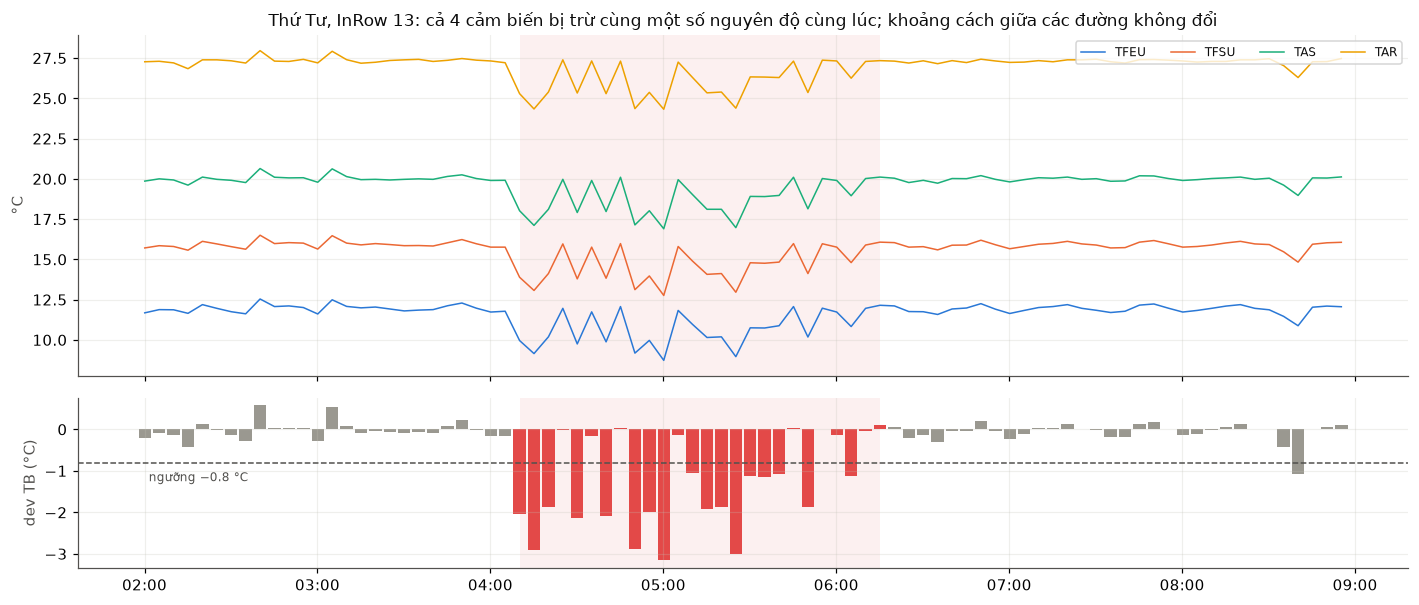

In [40]:
fig, axes = plt.subplots(2, 1, figsize=(13, 5.6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
x = wed[(wed.time.dt.hour >= 2) & (wed.time.dt.hour < 9)]
for i, s in enumerate(SENSORS):
    g = x[x.sensor == s]; axes[0].plot(g.time, g.value, color=SERIES[i], lw=1, label=s)
lab = x[x.label == 1]
for a in axes: a.axvspan(lab.time.min(), lab.time.max(), color=ALERT, alpha=0.08, lw=0)
axes[0].set_ylabel("°C"); axes[0].legend(ncol=4, fontsize=8, loc="upper right")
axes[0].set_title("Thứ Tư, InRow 13: cả 4 cảm biến bị trừ cùng một số nguyên độ cùng lúc; khoảng cách giữa các đường không đổi")
nd = nodes[(nodes.inrow == 13) & (nodes.slot.isin(x.slot.unique()))]
axes[1].bar(nd.time, nd.dev, width=0.003, color=[ALERT if l else MUTED for l in nd.label])
axes[1].axhline(-dm.DEV_T, color=INK2, ls="--", lw=1); axes[1].set_ylabel("dev TB (°C)")
axes[1].text(nd.time.min(), -dm.DEV_T - 0.45, f" ngưỡng −{dm.DEV_T} °C", fontsize=8, color=INK2)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=TZ))
plt.tight_layout(); save(fig, "D4_sua_gia_tri"); plt.show()

**Dấu vết của sửa giá trị — phát hiện quan trọng nhất về dữ liệu:**
- **Tra file gốc:** bảng T3 trong [`KIEM_CHUNG_DU_LIEU_GOC.md`](../KIEM_CHUNG_DU_LIEU_GOC.md): frame 2657–2661 (04:05, bình thường), 2707–2716 (04:10, bị trừ ≈ 1,9 °C), 2855–2863 (04:25, nhãn 1 nhưng giá trị không đổi). Bài báo chỉ mô tả sửa giá trị là "changing the temperature to be sent, without following the established pattern" ([1] mục 4.1); cách trừ số nguyên độ là phát hiện của dự án.
- Kẻ tấn công **trừ một số nguyên độ (0, 1, 2 hoặc 3 °C) cùng lúc trên cả 4 cảm biến** của tủ. Phần lẻ giữ nguyên, nên **khoảng cách giữa các cảm biến không đổi** (TAR − TAS vẫn ≈ 7,3 °C) và thứ tự vật lý vẫn đúng.
- Hệ quả: **mọi kiểm tra chéo trong cùng một tủ đều không thấy** (bất biến vật lý, cân bằng nhiệt, hiệu giữa các cảm biến). Chỉ có cách so tủ đó **với chính quá khứ của nó** (baseline).
- Giá trị bị sửa **luôn thấp hơn** thật, và mức trừ thay đổi mỗi chu kỳ: chuỗi trông như "răng cưa" lệch âm kéo dài nhiều chu kỳ. Nhiễu bình thường thì đơn lẻ, đối xứng, không quá 2 bản tin liền (mục “Nhiễu”). Từ đó ra đặc trưng phát hiện: **đếm số chu kỳ lệch dưới baseline quá 0,8 °C trong 6 chu kỳ gần nhất** (D4, Phần “Đúc kết nghiệp vụ”).
- **Khoảng một phần ba số slot có nhãn bị trừ 0 °C**: bản tin mang nhãn 1 nhưng giá trị **không hề đổi**. Không phương pháp nào nhìn vào giá trị có thể bắt được những bản tin này, nên **chấm ở mức từng bản tin sẽ không bao giờ đạt 100%**. Chấm ở mức **cửa sổ sự cố** mới đúng bản chất bài toán.
- Vì kẻ tấn công trừ cả 4 cảm biến **cùng lúc** và nhịp gửi không đổi, thứ Tư là kiểu tấn công **khó nhất và nguy hiểm nhất**: hệ thống làm mát tưởng phòng mát hơn 1–3 °C, đúng kịch bản CITIC.

## Danh sách sự cố chuẩn: 11 cửa sổ

In [41]:
cause = {}
for i, w in gt.iterrows():
    x = r13[(r13.time_utc >= w.start) & (r13.time_utc <= w.end)]
    if w.kind == "interception":
        cause[i] = inter.loc[w.local, "nguyên nhân"]
    else:
        cause[i] = "chèn bản tin + giá trị thấp" if x.early.sum() > 4 else "sửa giá trị"
gt_tab = gt.assign(loại=gt.kind.map({"labeled": "có nhãn", "interception": "không nhãn"}), nguyên_nhân=pd.Series(cause),
                   bản_tin_nhãn_1=[int(r13[(r13.time_utc >= w.start) & (r13.time_utc <= w.end)].label.sum()) for _, w in gt.iterrows()])
gt_tab.index = [f"S{i + 1:02d}" for i in range(len(gt_tab))]
fact("tổng số cửa sổ sự cố", len(gt_tab), 11)
fact("cửa sổ có nhãn / không nhãn", (int((gt.kind == "labeled").sum()), int((gt.kind == "interception").sum())), (6, 5))
fact("bản tin nhãn 1 nằm trong 6 cửa sổ có nhãn", int(gt_tab.bản_tin_nhãn_1.sum()), 544)
gt_tab[["local", "dur_min", "loại", "nguyên_nhân", "bản_tin_nhãn_1"]].rename(columns={"local": "giờ Madrid", "dur_min": "phút"})

,giờ Madrid,phút,loại,nguyên_nhân,bản_tin_nhãn_1
S01,Tue 22/10 00:15–00:55,40.0,không nhãn,bản tin bị xoá giữa phiên (chặn gói),0
S02,Tue 22/10 01:25–02:25,60.0,không nhãn,bản tin bị xoá giữa phiên (chặn gói),0
S03,Wed 23/10 04:10–06:15,125.0,có nhãn,sửa giá trị,104
S04,Thu 24/10 03:05–03:22,17.0,có nhãn,chèn bản tin + giá trị thấp,56
S05,Thu 24/10 23:03–00:00,56.0,không nhãn,node gửi xong phiên rồi tự ngắt kết nối sớm,0
S06,Fri 25/10 03:25–05:00,95.0,không nhãn,bản tin bị xoá giữa phiên (chặn gói),0
S07,Fri 25/10 06:00–06:25,26.0,có nhãn,chèn bản tin + giá trị thấp,96
S08,Fri 25/10 14:27–16:22,115.0,có nhãn,sửa giá trị,96
S09,Sat 26/10 03:00–05:00,120.0,không nhãn,bản tin bị xoá giữa phiên (chặn gói),0
S10,Sat 26/10 06:00–06:25,25.0,có nhãn,chèn bản tin + giá trị thấp,96


- **11 cửa sổ, đều ở InRow 13**: 5 cửa sổ không nhãn (4 chặn gói giữa phiên + 1 phiên kết thúc sớm), 6 cửa sổ có nhãn (3 chèn bản tin lúc rạng sáng/6h, 3 sửa giá trị).
- Cửa sổ có nhãn = gộp các bản tin nhãn 1 cách nhau dưới 30 phút; cửa sổ không nhãn = gộp các khoảng hở hơn 1,5 chu kỳ (`dm.ground_truth`). 544 bản tin nhãn 1 nằm trọn trong 6 cửa sổ có nhãn.
- Đây là **đáp án** để chấm các quy tắc ở Phần E. Chấm theo cửa sổ (bắt được bao nhiêu cửa sổ, trễ bao lâu, báo giả bao nhiêu) thay vì theo bản tin, vì lý do ở mục “Sửa giá trị”.

## Trông như bất thường nhưng không phải

In [42]:
conn_day = con.assign(c=con.src + ":" + con.sport.astype(int).astype(str)).set_index("c").day.astype(str)
opened_on = (pubs.src + ":" + pubs.sport.astype(int).astype(str)).map(conn_day)   # ngày mở kết nối của từng bản tin
carry = pubs[opened_on != pubs.day.astype(str)]
carry_tab = carry.groupby(["day", "inrow"], observed=True).agg(số_bản_tin=("ts", "size"), lúc=("time", lambda s: sorted(s.dt.strftime("%H:%M:%S").unique())))
sun_extra = carry[carry.day == "sun"]
artifacts = pd.DataFrame([
    ("keepalive 18.000 giây vào T3, T6, T7", "mọi tủ, cả 3 tủ không bị tấn công", "cấu hình chung của phiên thu dữ liệu ngày đó", "báo cả những tủ không bị tấn công"),
    ("InRow 13 tách khỏi InRow 15/23 suốt T3–T7", f"tương quan TAS 13~15: {twin.loc['T2 21/10', '13~15']:.3f} (T2) → {twin.loc['T4 23/10', '13~15']:.3f} (T4)", "chuỗi nhiệt độ của InRow 13 khác nhóm cả ngày, không chỉ trong cửa sổ tấn công", "báo động cả ngày, kể cả giờ không có tấn công"),
    ("hiệu giữa các cảm biến lặp lại mỗi 12 bản tin", f"tự tương quan trễ 12 ≈ {ac['trễ 12'].median():.2f}", "mẫu lặp chu kỳ 1 giờ của dữ liệu", "không có ý nghĩa vật lý"),
    ("bản tin của phiên hôm trước đến sau nửa đêm, không được PUBACK", f"{len(carry)} bản tin, đều trong 00:00–00:03 (bảng dưới)", "kết nối lại trễ, hoặc pha gửi bị xô sau đợt chèn; broker đã chuyển sang phiên mới nên không xác nhận", "bỏ qua khung 00:00–00:03"),
    ("InRow 25 không có NTP", "0 gói NTP cả tuần", "đồng bộ giờ qua card mạng khác (bài báo)", "không phải mất đồng bộ giờ"),
    ("gai ±1–2 °C đơn lẻ", f"{int((c.dev.abs() > 1).sum())} bản tin sạch lệch > 1 °C", "nhiễu bình thường của cảm biến", "không báo động trên 1 điểm"),
    ("tấn công luôn vào khung giờ cố định, chỉ InRow 13", "giờ, thứ, IP đủ để đoán nhãn", "các đợt tấn công trong tuần này rơi vào khung giờ cố định ([1] mục 5)", "chỉ đúng với tuần dữ liệu này, không phải dấu hiệu tấn công"),
], columns=["hiện tượng", "bằng chứng trong dữ liệu", "giải thích", "nếu dùng làm tín hiệu tấn công thì"])
fact("bản tin của phiên hôm trước đến sau nửa đêm: đều trong 00:00–00:03", bool(((carry.time.dt.hour == 0) & (carry.time.dt.minute < 3)).all()), True)
fact("bản tin của phiên thứ Bảy đến sau nửa đêm Chủ nhật (lý do CN có 1.156 bản tin/tủ)", len(sun_extra), 16)
unacked_keys = set(zip(un.day.astype(str), un.frame))
fact("bản tin phiên cũ sau nửa đêm chính là 20 bản tin không được PUBACK", set(zip(carry.day.astype(str), carry.frame)) == unacked_keys, True)
display(artifacts)
carry_tab

,hiện tượng,bằng chứng trong dữ liệu,giải thích,nếu dùng làm tín hiệu tấn công thì
0,"keepalive 18.000 giây vào T3, T6, T7","mọi tủ, cả 3 tủ không bị tấn công",cấu hình chung của phiên thu dữ liệu ngày đó,báo cả những tủ không bị tấn công
1,InRow 13 tách khỏi InRow 15/23 suốt T3–T7,tương quan TAS 13~15: 0.998 (T2) → 0.015 (T4),"chuỗi nhiệt độ của InRow 13 khác nhóm cả ngày, không chỉ trong cửa sổ tấn công","báo động cả ngày, kể cả giờ không có tấn công"
2,hiệu giữa các cảm biến lặp lại mỗi 12 bản tin,tự tương quan trễ 12 ≈ 0.99,mẫu lặp chu kỳ 1 giờ của dữ liệu,không có ý nghĩa vật lý
3,"bản tin của phiên hôm trước đến sau nửa đêm, không được PUBACK","20 bản tin, đều trong 00:00–00:03 (bảng dưới)","kết nối lại trễ, hoặc pha gửi bị xô sau đợt chèn; broker đã chuyển sang phiên mới nên ...",bỏ qua khung 00:00–00:03
4,InRow 25 không có NTP,0 gói NTP cả tuần,đồng bộ giờ qua card mạng khác (bài báo),không phải mất đồng bộ giờ
5,gai ±1–2 °C đơn lẻ,568 bản tin sạch lệch > 1 °C,nhiễu bình thường của cảm biến,không báo động trên 1 điểm
6,"tấn công luôn vào khung giờ cố định, chỉ InRow 13","giờ, thứ, IP đủ để đoán nhãn",các đợt tấn công trong tuần này rơi vào khung giờ cố định ([1] mục 5),"chỉ đúng với tuần dữ liệu này, không phải dấu hiệu tấn công"


số_bản_tin         lúc
day inrow                        
sat 13              4  [00:02:25]
sun 13              4  [00:01:37]
    15              4  [00:00:32]
    23              4  [00:00:32]
    25              4  [00:00:32]

**Tra file gốc:** bảng T8 (bản tin phiên cũ sau nửa đêm), T9 (keepalive từng ngày) trong [`KIEM_CHUNG_DU_LIEU_GOC.md`](../KIEM_CHUNG_DU_LIEU_GOC.md). Lịch tấn công cố định: [1] mục 5.

> **Thông điệp (Phần “Bất thường”).** Ba kiểu tấn công để lại ba dấu vết khác hẳn nhau: **chặn gói = khoảng hở** trong nhịp gửi, **chèn = bản tin đến sớm** 30–104 giây, **sửa giá trị = cả tủ bị trừ 1–3 °C** trong nhiều chu kỳ liền. Cả ba đều tác động **đồng thời lên 4 cảm biến** của một tủ. Sửa giá trị là kiểu nguy hiểm nhất: nhịp gửi bình thường, các cảm biến vẫn khớp nhau, chỉ lộ khi so với quá khứ. Dữ liệu còn có những đặc điểm trông như bất thường nhưng không phản ánh tấn công (keepalive, ba tủ gần như trùng nhau, mẫu lặp 1 giờ, khung giờ tấn công cố định): **đừng giám sát chúng**.

---
# Đúc kết nghiệp vụ: từ dữ liệu, giám sát được gì

Phần này biến hiểu biết ở các phần trên thành **quyết định giám sát**. Mỗi tín hiệu ứng viên được đo hai lần: **khi bình thường** và **khi bị tấn công**. Tín hiệu nào tách được hai trạng thái đó với biên an toàn rõ ràng thì đưa vào cảnh báo. Tín hiệu nào có ích nhưng không tách được thì chỉ hiển thị. Tín hiệu nào chỉ đúng với riêng bộ dữ liệu này, không phản ánh tấn công, thì loại.

## Bốn lớp tín hiệu, và lớp nào thấy được tấn công

Một hệ thống giám sát làm mát cần trả lời 4 câu hỏi, từ trên xuống:

| Lớp | Câu hỏi | Tín hiệu từ dữ liệu DAD | Nguồn của khái niệm và ngưỡng |
|---|---|---|---|
| 1 | Phòng máy có an toàn không? | nhiệt độ khí cấp (TAS) trong vùng khuyến nghị **18–27 °C** (cho phép loại A1: 15–32 °C); Rack Cooling Index (RCI) | [4] Table 2.1 (ASHRAE 2021); [5] trang 8 (công thức RCI; "<90% is often considered poor, 95% is often considered good, and 100% is ideal") |
| 2 | Tủ làm mát có làm việc tốt không? | ΔT khí = TAR − TAS; ΔT nước = TFSU − TFEU; approach = TAS − TFEU; cân bằng nhiệt = ΔT khí / ΔT nước | ΔT khí: [8]; ΔT nước, "low ΔT syndrome": [9]; approach (khí ra khỏi dàn trừ nước vào dàn): [10]; cân bằng nhiệt: tỉ số do dự án đặt ra |
| 3 | Dữ liệu cảm biến có đáng tin không? | độ tươi, độ đầy đủ, gửi dồn, dải hợp lệ, đứng giá trị, lệch baseline, thứ tự vật lý | độ tươi, độ đầy đủ, độ trễ: [11]; các tín hiệu còn lại và mọi ngưỡng: dự án đặt ra từ dữ liệu (Phần “Hành vi bình thường”) |
| 4 | Đường truyền dữ liệu có khoẻ không? | độ trễ PUBLISH → PUBACK, bản tin không được xác nhận | 4 tín hiệu vàng "latency, traffic, errors, and saturation": [7] |

TAS được dùng thay cho nhiệt độ đầu vào rack vì DAD không có cảm biến ở rack; bài báo coi các cảm biến rack và PDU là "static" ([1] mục 3.1).

Câu hỏi then chốt: **tấn công có làm lớp 1 và lớp 2 đổi không?** Nếu có, chỉ cần giám sát vận hành thông thường. Nếu không, phải có lớp 3.

In [43]:
kpi = pubs.pivot_table(index=["inrow", "slot"], columns="sensor", values="value", aggfunc="mean").dropna().reset_index()
kpi = kpi.assign(dT_air=kpi.TAR - kpi.TAS, dT_water=kpi.TFSU - kpi.TFEU, approach=kpi.TAS - kpi.TFEU)
kpi["ratio"] = kpi.dT_air / kpi.dT_water
kpi["trạng thái"] = "bình thường"
for i, w in gt.iterrows():
    m = (kpi.inrow == w.inrow) & (kpi.slot >= w.start.floor("5min")) & (kpi.slot <= w.end)
    kpi.loc[m, "trạng thái"] = gt_tab.iloc[i]["nguyên_nhân"]
k13 = kpi[kpi.inrow == 13]
lay = k13.groupby("trạng thái").agg(số_slot=("TAS", "size"), TAS_TB=("TAS", "mean"),
                                   TAS_trong_18_27=("TAS", lambda s: s.between(18, 27).mean() * 100),
                                   ΔT_khí=("dT_air", "mean"), ΔT_nước=("dT_water", "mean"), cân_bằng_nhiệt=("ratio", "mean"),
                                   approach=("approach", "mean")).round(2)
print("InRow 13, theo trạng thái của slot (giá trị trung bình; TAS_trong_18_27 tính theo %):")
lay

InRow 13, theo trạng thái của slot (giá trị trung bình; TAS_trong_18_27 tính theo %):


,số_slot,TAS_TB,TAS_trong_18_27,ΔT_khí,ΔT_nước,cân_bằng_nhiệt,approach
trạng thái,,,,,,,
bình thường,1846,20.01,99.73,7.33,3.95,1.85,8.07
bản tin bị xoá giữa phiên (chặn gói),32,20.12,100.00,7.34,3.97,1.85,8.12
chèn bản tin + giá trị thấp,16,18.54,87.50,7.32,3.95,1.85,8.12
node gửi xong phiên rồi tự ngắt kết nối sớm,2,19.95,100.00,7.38,3.97,1.86,8.08
sửa giá trị,74,18.77,74.32,7.32,3.97,1.84,8.15


In [44]:
tas_all = pubs[pubs.sensor == "TAS"].sort_values("ts")
rci = tas_all.groupby(["inrow", "day"], observed=True).value.apply(
    lambda s: 100 * (1 - (18 - s).clip(lower=0).sum() / ((18 - 15) * len(s)))).unstack().round(1)
rci.columns = [DAY_VI[d] for d in rci.columns]
low30 = tas_all.groupby("client_id").value.transform(lambda s: s.rolling(6).max() < 18)
mod_slots = k13[k13["trạng thái"] == "sửa giá trị"]
norm13 = k13[k13["trạng thái"] == "bình thường"]
fact("số lần TAS dưới 18 °C liền 30 phút, cả tuần, mọi tủ", int(low30.sum()), 0)
fact("RCI_LO thấp nhất cả tuần (%)", float(rci.values.min()), 98.4, tol=0.05)
fact("ΔT khí không đổi khi bị sửa giá trị (lệch < 0,1 °C)", bool(abs(mod_slots.dT_air.mean() - norm13.dT_air.mean()) < 0.1), True)
fact("cân bằng nhiệt không đổi khi bị sửa giá trị (lệch < 0,05)", bool(abs(mod_slots.ratio.mean() - norm13.ratio.mean()) < 0.05), True)
print("RCI_LO (%) của nhiệt độ khí cấp theo tủ và ngày: 100 = lý tưởng, ≥ 95 tốt, < 90 kém")
rci

RCI_LO (%) của nhiệt độ khí cấp theo tủ và ngày: 100 = lý tưởng, ≥ 95 tốt, < 90 kém


,T2 21/10,T3 22/10,T4 23/10,T5 24/10,T6 25/10,T7 26/10,CN 27/10
inrow,,,,,,,
13,100.0,100.0,99.5,99.5,98.9,98.4,100.0
15,100.0,100.0,100.0,100.0,100.0,100.0,100.0
23,100.0,100.0,100.0,100.0,100.0,100.0,100.0
25,100.0,100.0,100.0,100.0,100.0,100.0,100.0


**Kết luận then chốt: lớp 1 và lớp 2 gần như mù trước tấn công.**
- Khi bị sửa giá trị, TAS trung bình giảm ≈ 1,2 °C nhưng vẫn **phần lớn thời gian (khoảng 3/4) nằm trong vùng 18–27 °C**. Chưa lần nào TAS dưới 18 °C liền 30 phút, nên một cảnh báo ASHRAE thông thường **không bao giờ kêu**. RCI vẫn ≥ 98%, tức vẫn "tốt" theo thang của Herrlin ([5] trang 8).
- **ΔT khí, ΔT nước, approach, cân bằng nhiệt không đổi** ở mọi kiểu tấn công, vì kẻ tấn công luôn tác động cùng một lượng lên cả 4 cảm biến.
- Chặn gói không làm đổi giá trị. Chèn bản tin có hạ giá trị (bản tin chèn mang giá trị thấp) nhưng chỉ trong 17–26 phút, cũng không đủ để lớp 1 kêu. Cả hai lộ rõ nhất ở **thời gian**.
- Vậy hệ thống giám sát vận hành thông thường (lớp 1, 2) sẽ **bỏ sót toàn bộ** 11 sự cố của DAD. **Lớp 3, "dữ liệu có đáng tin không", là lớp bắt buộc.** Đây là lập luận trung tâm của dự án.
- Lớp 1, 2 vẫn cần (để thấy quá nhiệt thật, tủ làm mát yếu dần), nhưng là để **hiển thị và theo dõi xu hướng**, không phải để phát hiện tấn công.

## Danh mục tín hiệu: đưa vào, chỉ hiển thị, hay loại

In [45]:
gapP = pubs.gap_s / P
normal_m = CLEAN
att_win = pd.Series(False, index=pubs.index)
for _, w in gt.iterrows():
    att_win |= (pubs.inrow == w.inrow) & (pubs.time_utc >= w.start) & (pubs.time_utc <= w.end + pd.Timedelta("1s"))
mod_win = pd.Series(False, index=nodes.index)
for i, w in gt.iterrows():
    if gt_tab.iloc[i]["nguyên_nhân"] in ("sửa giá trị", "chèn bản tin + giá trị thấp"):
        mod_win |= (nodes.inrow == w.inrow) & (nodes.slot >= w.start.floor("5min")) & (nodes.slot <= w.end)
node_clean = (nodes.inrow != 13) | nodes.day.isin(["mon", "sun"])
s_sorted = pubs.sort_values(["client_id", "ts"])
c6_sensor = (s_sorted.dev < -dm.DEV_T).groupby(s_sorted.client_id).transform(lambda x: x.rolling(dm.DEV_W).sum())
lo_rng = {s: min(REAL_TABLE1[(i, s)][2] for i in (13, 15, 23, 25)) - 2 for s in SENSORS}
hi_rng = {s: max(REAL_TABLE1[(i, s)][3] for i in (13, 15, 23, 25)) + 2 for s in SENSORS}
out_rng = (pubs.value < pubs.sensor.map(lo_rng)) | (pubs.value > pubs.sensor.map(hi_rng))
stuck_run = pubs.sort_values(["client_id", "ts"]).groupby("client_id").value.apply(lambda s: s.groupby((s != s.shift()).cumsum()).size().max())
early_all = (pubs.gap_s < dm.BURST_FACTOR * P) & ~pubs.new_conn
slots_day = pubs.groupby(["client_id", "day"], observed=True).slot.nunique()
clean_sd = slots_day[[(c, d) for c, d in slots_day.index if not c.startswith("13") or d in ("mon", "sun")]]
att_sd = slots_day[[(c, d) for c, d in slots_day.index if c.startswith("13") and d not in ("mon", "sun")]]

N = lambda v: f"{v}"
catalog = pd.DataFrame([
    ("độ tươi: (bây giờ − lần nhận cuối) / P", "3", f"tối đa {gapP[normal_m].max():.2f} P", f"tới {gapP[pubs.inrow == 13].max():.1f} P khi mất bản tin", "ĐƯA VÀO cảnh báo (D1)", "tách tuyệt đối; ngưỡng 1,5 P"),
    ("bản tin đến sớm < 0,8 P trên cùng kết nối", "3", f"{int(early_all[normal_m].sum())} bản tin", f"{int(early_all[~normal_m].sum())} bản tin ({int((early_all & (pubs.label == 1)).sum())} có nhãn, còn lại ngay sau đợt chèn)", "ĐƯA VÀO cảnh báo (D2)", "tách tuyệt đối"),
    ("đầy đủ: số ô 5 phút có dữ liệu / 288 mỗi ngày", "3", f"thấp nhất {clean_sd.min() / 2.88:.1f}%", f"thấp nhất {att_sd.min() / 2.88:.1f}%", "ĐƯA VÀO báo cáo ngày", "đếm ô, không đếm bản tin (mục “Lịch tấn công”)"),
    ("lệch âm kéo dài: số chu kỳ dev < −0,8 °C trong 6, gộp theo tủ", "3", f"tối đa {nodes[node_clean].neg_count6.max():.0f}/6", f"tới {nodes[mod_win].neg_count6.max():.0f}/6 khi bị sửa", "ĐƯA VÀO cảnh báo (D4)", "ngưỡng ≥ 3/6"),
    ("lệch âm kéo dài, theo từng cảm biến", "3", f"tối đa {c6_sensor[CLEAN.reindex(s_sorted.index)].max():.0f}/6", "≥ 3/6 sớm hơn bản gộp", "ĐƯA VÀO cảnh báo sớm", "nhanh hơn, 1 báo giả/tuần (mục “Ba quy tắc phát hiện”)"),
    ("thứ tự vật lý TFEU < TFSU < TAS < TAR", "3", "0 vi phạm", "0 vi phạm", "ĐƯA VÀO (rẻ)", "không bắt được gì trong DAD; dành cho cảm biến lẻ hỏng"),
    ("dải hợp lệ: dải đo thật 14 ngày ± 2 °C", "3", f"{int(out_rng[normal_m].sum())} vi phạm", f"{int(out_rng[~normal_m].sum())} vi phạm", "ĐƯA VÀO (rẻ)", "giá trị rác, lỗi đơn vị; DAD không có"),
    ("đứng giá trị: ≥ 12 bản tin liền giống hệt", "3", f"dài nhất {int(same.max())} bản tin", f"dài nhất {int(stuck_run.max())} bản tin", "ĐƯA VÀO (rẻ)", "cảm biến treo; DAD không có"),
    ("TAS trong vùng ASHRAE 18–27 °C", "1", "≥ 99% thời gian", f"{lay.loc['sửa giá trị', 'TAS_trong_18_27']:.0f}% khi bị sửa", "HIỂN THỊ", "không kêu khi bị tấn công (mục “Bốn lớp tín hiệu”)"),
    ("RCI_LO / RCI_HI theo tủ và ngày", "1", "≈ 100%", f"thấp nhất {rci.values.min():.1f}%", "HIỂN THỊ tổng quan", "một con số/tủ/ngày cho quản lý"),
    ("ΔT khí, ΔT nước, approach, cân bằng nhiệt", "2", "gần như hằng số", "không đổi khi bị sửa", "HIỂN THỊ xu hướng", "phát hiện tủ yếu dần, cảm biến lẻ trôi"),
    ("độ trễ PUBLISH → PUBACK", "4", f"p99 {pa.puback_ms.quantile(.99):.2f} ms", "không đổi", "HIỂN THỊ", "DAD không có sự cố truyền dẫn"),
    ("bản tin không được xác nhận (PUBACK)", "4", f"{len(un)} bản tin, đều 00:00–00:03", "không liên quan", "HIỂN THỊ, bỏ khung 00:00–00:03", ""),
    ("DISCONNECT ngoài giờ chuyển ngày", "4", "0", "1 lần (đêm T5)", "DÙNG KHI ĐIỀU TRA", "phân biệt thiết bị tự dừng với bị chặn"),
    ("biến động: TB |Δ| trong 6 chu kỳ (D3 cũ)", "3", "gai nhiễu làm tăng", "tăng", "LOẠI", "9 báo giả/tuần (mục “Ba quy tắc phát hiện”)"),
    ("so với tủ bên cạnh (độ lệch, tương quan)", "3", "3 tủ gần như trùng nhau", "InRow 13 lệch cả ngày T3–T7", "LOẠI", "báo cả giờ không bị tấn công (mục “Cấu trúc giữa các cảm biến và giữa các tủ”)"),
    ("keepalive, cờ clean session", "4", "đổi theo ngày", "đổi theo ngày, mọi node", "LOẠI", "áp lên mọi tủ, cả tủ không bị tấn công (mục “MQTT”)"),
    ("khoảng nhảy của msgid", "4", "luôn +1", "luôn +1", "LOẠI (với DAD)", "luôn liên tục dù mất bản tin; ngoài đời nên giữ"),
    ("số bản tin mỗi ngày", "3", "288", "288 dù mất 11 ô (T5)", "THAY bằng độ đầy đủ theo ô", "che mất bản tin bị mất"),
    ("giờ trong ngày, thứ, IP, clientId", "—", "—", "trùng khung giờ bị tấn công", "LOẠI", "chỉ đúng với tuần dữ liệu này (mục “Trông như bất thường nhưng không phải”)"),
], columns=["tín hiệu", "lớp", "khi bình thường", "khi bị tấn công", "quyết định", "lý do"])
fact("độ tươi khi bình thường không vượt 1,5 P", bool(gapP[normal_m].max() < dm.SILENCE_FACTOR), True)
fact("bản tin đến sớm khi bình thường", int(early_all[normal_m].sum()), 0)
fact("lệch âm theo tủ khi bình thường: tối đa < 3/6", bool(nodes[node_clean].neg_count6.max() < dm.DEV_K), True)
fact("vi phạm dải hợp lệ trên toàn bộ dữ liệu", int(out_rng.sum()), 0)
dec = catalog["quyết định"]
counts = (int(dec.str.startswith("ĐƯA VÀO").sum()), int(dec.str.startswith(("HIỂN THỊ", "DÙNG KHI")).sum()),
          int(dec.str.startswith("LOẠI").sum()), int(dec.str.startswith("THAY").sum()))
fact("số tín hiệu: đưa vào / hiển thị hoặc điều tra / loại / thay", counts, (8, 6, 5, 1))
catalog

,tín hiệu,lớp,khi bình thường,khi bị tấn công,quyết định,lý do
0,độ tươi: (bây giờ − lần nhận cuối) / P,3,tối đa 1.00 P,tới 11.2 P khi mất bản tin,ĐƯA VÀO cảnh báo (D1),"tách tuyệt đối; ngưỡng 1,5 P"
1,"bản tin đến sớm < 0,8 P trên cùng kết nối",3,0 bản tin,"248 bản tin (236 có nhãn, còn lại ngay sau đợt chèn)",ĐƯA VÀO cảnh báo (D2),tách tuyệt đối
2,đầy đủ: số ô 5 phút có dữ liệu / 288 mỗi ngày,3,thấp nhất 100.0%,thấp nhất 94.8%,ĐƯA VÀO báo cáo ngày,"đếm ô, không đếm bản tin (mục “Lịch tấn công”)"
3,"lệch âm kéo dài: số chu kỳ dev < −0,8 °C trong 6, gộp theo tủ",3,tối đa 2/6,tới 6/6 khi bị sửa,ĐƯA VÀO cảnh báo (D4),ngưỡng ≥ 3/6
4,"lệch âm kéo dài, theo từng cảm biến",3,tối đa 3/6,≥ 3/6 sớm hơn bản gộp,ĐƯA VÀO cảnh báo sớm,"nhanh hơn, 1 báo giả/tuần (mục “Ba quy tắc phát hiện”)"
5,thứ tự vật lý TFEU < TFSU < TAS < TAR,3,0 vi phạm,0 vi phạm,ĐƯA VÀO (rẻ),không bắt được gì trong DAD; dành cho cảm biến lẻ hỏng
6,dải hợp lệ: dải đo thật 14 ngày ± 2 °C,3,0 vi phạm,0 vi phạm,ĐƯA VÀO (rẻ),"giá trị rác, lỗi đơn vị; DAD không có"
7,đứng giá trị: ≥ 12 bản tin liền giống hệt,3,dài nhất 4 bản tin,dài nhất 4 bản tin,ĐƯA VÀO (rẻ),cảm biến treo; DAD không có
8,TAS trong vùng ASHRAE 18–27 °C,1,≥ 99% thời gian,74% khi bị sửa,HIỂN THỊ,không kêu khi bị tấn công (mục “Bốn lớp tín hiệu”)
9,RCI_LO / RCI_HI theo tủ và ngày,1,≈ 100%,thấp nhất 98.4%,HIỂN THỊ tổng quan,một con số/tủ/ngày cho quản lý


**Đọc danh mục:**
- **8 tín hiệu đưa vào**, đều thuộc lớp 3:
  - 7 cảnh báo: độ tươi (D1), đến sớm (D2), lệch âm theo tủ (D4) và theo cảm biến, cộng 3 kiểm tra rẻ (thứ tự vật lý, dải hợp lệ, đứng giá trị) cho những lỗi DAD không có nhưng ngoài đời có. 4 tín hiệu đầu **tách hoàn toàn** bình thường với tấn công trên DAD;
  - 1 chỉ số báo cáo ngày: độ đầy đủ theo ô 5 phút.
- **6 tín hiệu chỉ hiển thị hoặc dùng khi điều tra**: an toàn phòng máy (lớp 1), hiệu quả làm mát (lớp 2), sức khoẻ đường truyền (lớp 4). Người vận hành cần nhìn chúng, nhưng đó không phải nơi tấn công lộ ra. Riêng DISCONNECT ngoài giờ chuyển ngày giúp phân biệt "thiết bị tự dừng" với "bị chặn".
- **Loại 5 tín hiệu**: hoặc báo giả nhiều (biến động), hoặc là đặc điểm chỉ đúng với riêng bộ dữ liệu này, không phản ánh tấn công (so với tủ bên cạnh, keepalive, `msgid`, giờ/thứ/IP).
- **1 tín hiệu bị thay**: đếm bản tin mỗi ngày đổi thành đếm ô 5 phút có dữ liệu.

## Ba quy tắc phát hiện chính và kết quả trên cả tuần

| Quy tắc | Định nghĩa (chỉ dùng dữ liệu quá khứ) | Ngưỡng | Bắt kiểu nào |
|---|---|---|---|
| **D1 im lặng** | khoảng cách từ bản tin cuối của một cảm biến tới hiện tại | > **1,5 P** (7,5 phút) | mất bản tin, node ngừng gửi |
| **D2 gửi dồn** | khoảng cách tới bản tin trước trên **cùng kết nối** | < **0,8 P** (4 phút) | chèn bản tin |
| **D4 lệch âm** | trung bình dev của 4 cảm biến trong slot; đếm slot có dev < −0,8 °C trong 6 slot gần nhất | ≥ **3/6** | sửa giá trị |
| D4 theo cảm biến | như D4 nhưng tính riêng từng cảm biến | ≥ 3/6 | cảnh báo sớm, khoanh vùng cảm biến |

**Cách chấm:** gộp các cảnh báo cùng tủ cách nhau dưới 20 phút thành một **sự kiện**. Sự kiện **đúng** nếu chồng lên một cửa sổ sự cố (±15 phút), ngược lại là **báo giả**. **Độ trễ** = cảnh báo đầu tiên trừ lúc cửa sổ bắt đầu. Chấm trên **cả 4 tủ, cả tuần**.

In [46]:
A = dm.alarms(pubs, nodes)
A = {"D1 im lặng": A["D1 im lặng"], "D2 gửi dồn": A["D2 gửi dồn"], "D3 biến động (loại)": A["D3 biến động (cũ)"],
     "D4 lệch âm (theo tủ)": A["D4 lệch âm 3/6 (mới)"]}
hit = s_sorted[c6_sensor >= dm.DEV_K]
A["D4 theo cảm biến"] = pd.DataFrame({"inrow": hit.inrow, "t": hit.time_utc})
A["D1 + D2 + D4 (đề xuất)"] = pd.concat([A["D1 im lặng"], A["D2 gửi dồn"], A["D4 lệch âm (theo tủ)"]])
score, delays, events = [], {}, {}
for k, a in A.items():
    ev, dl = dm.evaluate(a, gt)
    delays[k], events[k] = dl, ev
    score.append({"quy tắc": k, "số cảnh báo thô": len(a), "sự kiện": len(ev), "đúng": int(ev.dung.sum()),
                  "báo giả / tuần": int((~ev.dung).sum()), "cửa sổ bắt được / 11": int(dl.notna().sum())})
score = pd.DataFrame(score).set_index("quy tắc")
fact("D1 + D2 + D4 bắt được bao nhiêu cửa sổ", int(score.loc["D1 + D2 + D4 (đề xuất)", "cửa sổ bắt được / 11"]), 11)
fact("D1 + D2 + D4 báo giả trong tuần", int(score.loc["D1 + D2 + D4 (đề xuất)", "báo giả / tuần"]), 0)
fact("D3 biến động báo giả trong tuần", int(score.loc["D3 biến động (loại)", "báo giả / tuần"]), 9)
fact("D4 theo cảm biến báo giả trong tuần", int(score.loc["D4 theo cảm biến", "báo giả / tuần"]), 1)
score

,số cảnh báo thô,sự kiện,đúng,báo giả / tuần,cửa sổ bắt được / 11
quy tắc,,,,,
D1 im lặng,64,12,12,0,5
D2 gửi dồn,248,3,3,0,3
D3 biến động (loại),70,15,6,9,3
D4 lệch âm (theo tủ),85,6,6,0,6
D4 theo cảm biến,497,7,6,1,6
D1 + D2 + D4 (đề xuất),397,18,18,0,11


In [47]:
lat = pd.DataFrame(delays).round(1)
lat.index = gt_tab.index + "  " + gt_tab.local + "  (" + gt_tab["nguyên_nhân"] + ")"
fact("độ trễ D1 với chặn gói (phút)", sorted(lat["D1 im lặng"].dropna().unique().tolist()), [7.5])
fact("độ trễ lớn nhất của bộ đề xuất (phút)", float(lat["D1 + D2 + D4 (đề xuất)"].max()), 27.8, tol=0.05)
print("Độ trễ phát hiện (phút thời gian thật, tính từ đầu cửa sổ; trống = không bắt được):")
lat[["D1 im lặng", "D2 gửi dồn", "D4 lệch âm (theo tủ)", "D4 theo cảm biến", "D1 + D2 + D4 (đề xuất)"]]

Độ trễ phát hiện (phút thời gian thật, tính từ đầu cửa sổ; trống = không bắt được):


,D1 im lặng,D2 gửi dồn,D4 lệch âm (theo tủ),D4 theo cảm biến,D1 + D2 + D4 (đề xuất)
S01 Tue 22/10 00:15–00:55 (bản tin bị xoá giữa phiên (chặn gói)),7.5,NaN,NaN,NaN,7.5
S02 Tue 22/10 01:25–02:25 (bản tin bị xoá giữa phiên (chặn gói)),7.5,NaN,NaN,NaN,7.5
S03 Wed 23/10 04:10–06:15 (sửa giá trị),NaN,NaN,14.9,10.0,14.9
S04 Thu 24/10 03:05–03:22 (chèn bản tin + giá trị thấp),NaN,1.5,14.9,6.1,1.5
S05 Thu 24/10 23:03–00:00 (node gửi xong phiên rồi tự ngắt kết nối sớm),7.5,NaN,NaN,NaN,7.5
S06 Fri 25/10 03:25–05:00 (bản tin bị xoá giữa phiên (chặn gói)),7.5,NaN,NaN,NaN,7.5
S07 Fri 25/10 06:00–06:25 (chèn bản tin + giá trị thấp),NaN,1.1,14.9,3.9,1.1
S08 Fri 25/10 14:27–16:22 (sửa giá trị),NaN,NaN,27.8,25.0,27.8
S09 Sat 26/10 03:00–05:00 (bản tin bị xoá giữa phiên (chặn gói)),7.5,NaN,NaN,NaN,7.5
S10 Sat 26/10 06:00–06:25 (chèn bản tin + giá trị thấp),NaN,1.0,9.8,3.3,1.0


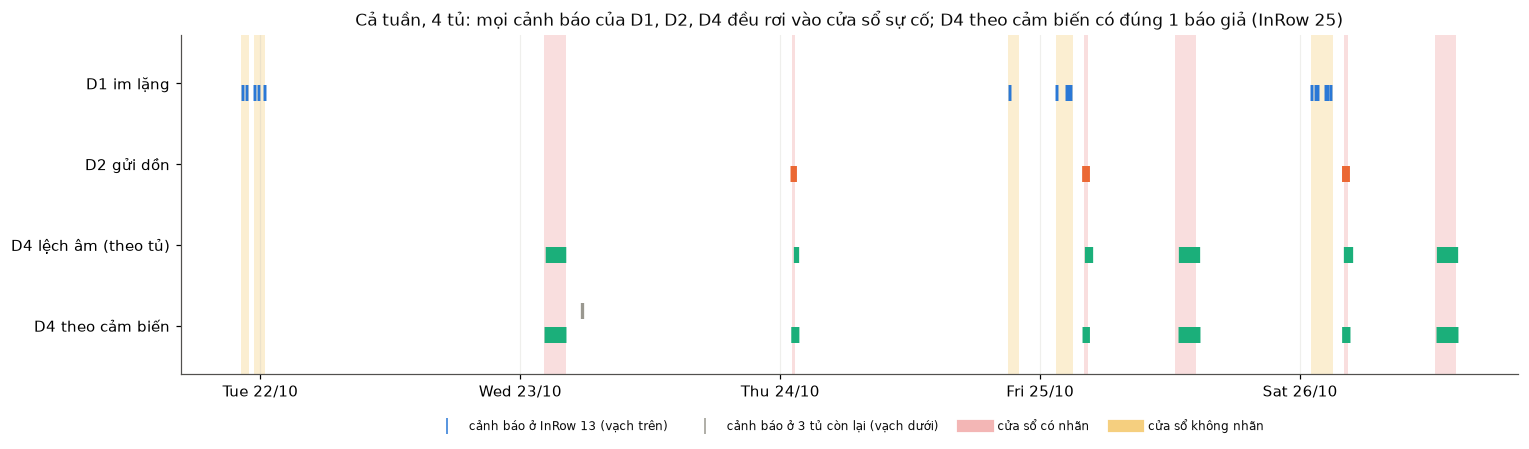

In [48]:
fig, ax = plt.subplots(figsize=(14, 4.2))
lanes = ["D1 im lặng", "D2 gửi dồn", "D4 lệch âm (theo tủ)", "D4 theo cảm biến"]
for _, w in gt.iterrows():
    ax.axvspan(w.start, w.end, color=ALERT if w.kind == "labeled" else SERIES[3], alpha=0.18, lw=0)
for y, k in enumerate(lanes):
    a = A[k]
    for inrow, col, dy in [(13, [SERIES[0], SERIES[1], SERIES[2], SERIES[2]][y], 0.12), (None, MUTED, -0.18)]:
        x = a[a.inrow == 13] if inrow else a[a.inrow != 13]
        ax.scatter(x.t.dt.tz_convert(TZ), np.full(len(x), y + dy), marker="|", s=120, color=col, lw=1.5)
ax.set_yticks(range(len(lanes))); ax.set_yticklabels(lanes); ax.set_ylim(-0.6, len(lanes) - 0.4); ax.invert_yaxis()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d/%m", tz=TZ)); ax.grid(axis="y", alpha=0)
ax.plot([], [], color=SERIES[0], marker="|", ls="", ms=10, label="cảnh báo ở InRow 13 (vạch trên)")
ax.plot([], [], color=MUTED, marker="|", ls="", ms=10, label="cảnh báo ở 3 tủ còn lại (vạch dưới)")
ax.plot([], [], color=ALERT, alpha=0.4, lw=8, label="cửa sổ có nhãn"); ax.plot([], [], color=SERIES[3], alpha=0.5, lw=8, label="cửa sổ không nhãn")
ax.legend(ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False)
ax.set_title("Cả tuần, 4 tủ: mọi cảnh báo của D1, D2, D4 đều rơi vào cửa sổ sự cố; D4 theo cảm biến có đúng 1 báo giả (InRow 25)")
plt.tight_layout(); save(fig, "E3_dong_thoi_gian_phat_hien"); plt.show()

- **D1 + D2 + D4 bắt đủ 11/11 cửa sổ, 0 báo giả** trên cả 4 tủ trong cả tuần. Mỗi quy tắc bắt đúng kiểu nó nhắm tới: D1 bắt 5/5 lần mất bản tin (trễ đúng 7,5 phút = 1,5 P), D2 bắt 3/3 lần chèn (trễ 1–1,5 phút), D4 bắt 6/6 cửa sổ có nhãn (trễ 10–28 phút).
- **D4 theo cảm biến nhanh hơn** (bắt sớm hơn 3–11 phút) nhưng có **1 báo giả** (InRow 25, sáng thứ Tư): một cảm biến lẻ có 3 gai âm trong 6 chu kỳ. Dùng nó làm **cảnh báo sớm mức thấp**, còn D4 theo tủ làm **xác nhận mức cao**.
- **D3 "biến động" bị loại**: 9 báo giả, chỉ bắt 3 cửa sổ. Gai nhiễu đối xứng làm biến động tăng y như khi bị tấn công.
- Lúc 6h thứ Sáu và thứ Bảy, D2 báo trước (vì có chèn); cửa sổ 14–16h chỉ có sửa giá trị, nên chỉ D4 bắt, trễ 19–28 phút. Đây là kiểu tấn công khó nhất.

## Ngưỡng có bị "khớp" vào chính dữ liệu dùng để chấm không?

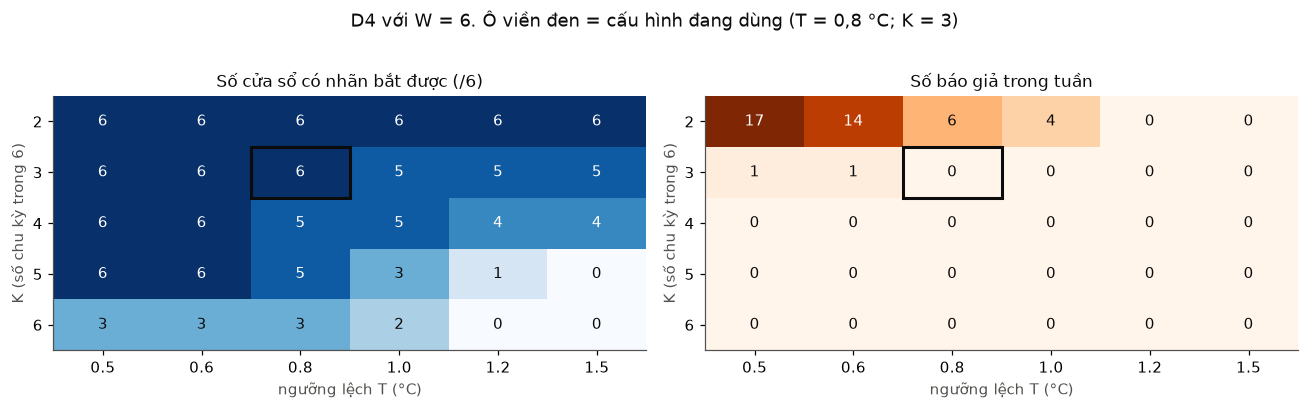

Cấu hình bắt 6/6 và 0 báo giả: [(2, 1.2), (2, 1.5), (3, 0.8), (4, 0.5), (4, 0.6), (5, 0.5), (5, 0.6)]


In [49]:
labeled = gt[gt.kind == "labeled"]
def d4_alarm(T, K, W, n=nodes):
    cnt = (n.dev < -T).groupby(n.inrow).transform(lambda s: s.rolling(W).sum())
    s = n[cnt >= K]
    return pd.DataFrame({"inrow": s.inrow, "t": s.slot + pd.Timedelta("5min")})
TS = [0.5, 0.6, 0.8, 1.0, 1.2, 1.5]; KS = [2, 3, 4, 5, 6]
caught = pd.DataFrame(index=KS, columns=TS, dtype=float); fps = caught.copy()
for K in KS:
    for T in TS:
        ev, dl = dm.evaluate(d4_alarm(T, K, 6), gt)
        caught.loc[K, T] = dl[labeled.index].notna().sum(); fps.loc[K, T] = (~ev.dung).sum()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, M, title, cmap in [(axes[0], caught, "Số cửa sổ có nhãn bắt được (/6)", "Blues"), (axes[1], fps, "Số báo giả trong tuần", "Oranges")]:
    vmax = max(6, float(M.values.max()))
    ax.imshow(M.values.astype(float), cmap=cmap, aspect="auto", vmin=0, vmax=vmax); ax.grid(False)
    for i in range(len(KS)):
        for j in range(len(TS)):
            v = int(M.values[i, j]); ax.text(j, i, v, ha="center", va="center", fontsize=10, color="white" if v > 0.6 * vmax else INK)
    ax.set_xticks(range(len(TS))); ax.set_xticklabels(TS); ax.set_yticks(range(len(KS))); ax.set_yticklabels(KS)
    ax.set_xlabel("ngưỡng lệch T (°C)"); ax.set_ylabel("K (số chu kỳ trong 6)"); ax.set_title(title)
    ax.add_patch(plt.Rectangle((TS.index(0.8) - 0.5, KS.index(3) - 0.5), 1, 1, fill=False, ec=INK, lw=2))
plt.suptitle("D4 với W = 6. Ô viền đen = cấu hình đang dùng (T = 0,8 °C; K = 3)", y=1.02); plt.tight_layout(); save(fig, "E4_luoi_tham_so_D4"); plt.show()
perfect = [(K, T) for K in KS for T in TS if caught.loc[K, T] == 6 and fps.loc[K, T] == 0]
fact("cấu hình D4 hoàn hảo (6/6, 0 báo giả) với W = 6", perfect, [(2, 1.2), (2, 1.5), (3, 0.8), (4, 0.5), (4, 0.6), (5, 0.5), (5, 0.6)])
print("Cấu hình bắt 6/6 và 0 báo giả:", perfect)

In [50]:
cut = pd.Timestamp("2019-10-24 22:00", tz="UTC")                  # hết thứ Năm (giờ Madrid)
tr_w, te_w = labeled[labeled.start < cut], labeled[labeled.start >= cut]
rows = []
for W in [4, 6, 8, 12]:
    for K in range(2, min(W, 6) + 1):
        for T in TS:
            a = d4_alarm(T, K, W)
            if a.empty:
                continue
            ev, dl = dm.evaluate(a, gt)
            rows.append(dict(W=W, K=K, T=T, train_bắt=int(dl[tr_w.index].notna().sum()), train_báo_giả=int(((~ev.dung) & (ev.start < cut)).sum()),
                             test_bắt=int(dl[te_w.index].notna().sum()), test_báo_giả=int(((~ev.dung) & (ev.start >= cut)).sum())))
sweep = pd.DataFrame(rows)
chosen = sweep[(sweep.train_bắt == len(tr_w)) & (sweep.train_báo_giả == 0)]
fact("cấu hình hoàn hảo trên T2–T5 cũng hoàn hảo trên T6–T7", bool(((chosen.test_bắt == len(te_w)) & (chosen.test_báo_giả == 0)).all()), True)
print(f"{len(chosen)} cấu hình hoàn hảo khi chỉ nhìn T2–T5 ({len(tr_w)} cửa sổ); trên T6–T7 ({len(te_w)} cửa sổ chưa thấy):")
chosen[["test_bắt", "test_báo_giả"]].value_counts().rename("số cấu hình").to_frame()

28 cấu hình hoàn hảo khi chỉ nhìn T2–T5 (2 cửa sổ); trên T6–T7 (4 cửa sổ chưa thấy):


,,số cấu hình
test_bắt,test_báo_giả,
4,0,28


- Có **một dải** cấu hình hoàn hảo (K = 2 với T ≥ 1,2; K = 3 với T = 0,8; K = 4–5 với T = 0,5–0,6), không phải một điểm đơn lẻ. Cấu hình đang dùng (K = 3, T = 0,8) đứng một mình trong dải: nhanh nhất nhưng ít biên an toàn. Khối K = 4–5, T = 0,5–0,6 chịu nhiễu tốt hơn, đổi lại chậm hơn khoảng 7 phút.
- **Chọn ngưỡng trên quá khứ, kiểm tra trên tương lai:** chỉ nhìn thứ Hai đến thứ Năm để chọn, mọi cấu hình hoàn hảo đều bắt đủ 4/4 cửa sổ thứ Sáu, thứ Bảy, không báo giả. Quy tắc **tổng quát hoá sang ngày chưa thấy**.
- Giới hạn: 2 cửa sổ để chọn, 4 để kiểm tra, cùng một kẻ tấn công. Đủ để nói "không phải khớp may mắn", chưa đủ để nói về hiệu năng ngoài đời.

## Gộp cảnh báo theo tủ: từ "lụt cảnh báo" về 2–3 sự cố mỗi ngày

In [51]:
raw = A["D1 + D2 + D4 (đề xuất)"]
per10 = raw.groupby(raw.t.dt.floor("10min")).size()
n_days = 7
flood = pd.Series({"cảnh báo thô (mỗi bản tin / slot vi phạm)": len(raw), "cảnh báo thô / ngày": round(len(raw) / n_days, 1),
                   "cảnh báo thô nhiều nhất trong 10 phút": int(per10.max()),
                   "sự kiện sau khi gộp theo tủ (≥ 20 phút)": len(events["D1 + D2 + D4 (đề xuất)"]),
                   "sự kiện / ngày": round(len(events["D1 + D2 + D4 (đề xuất)"]) / n_days, 1),
                   "sự kiện nhiều nhất trong 10 phút": int(events["D1 + D2 + D4 (đề xuất)"].groupby(events["D1 + D2 + D4 (đề xuất)"].start.dt.floor("10min")).size().max())})
fact("cảnh báo thô nhiều nhất trong 10 phút", int(per10.max()), 41)
fact("sự kiện sau khi gộp, mỗi ngày", round(len(events["D1 + D2 + D4 (đề xuất)"]) / n_days, 1), 2.6, tol=0.05)
flood.to_frame("giá trị")

,giá trị
cảnh báo thô (mỗi bản tin / slot vi phạm),397.0
cảnh báo thô / ngày,56.7
cảnh báo thô nhiều nhất trong 10 phút,41.0
sự kiện sau khi gộp theo tủ (≥ 20 phút),18.0
sự kiện / ngày,2.6
sự kiện nhiều nhất trong 10 phút,1.0


- Nếu bắn một cảnh báo cho **mỗi bản tin vi phạm**, lúc bị chèn bản tin sẽ có tới **41 cảnh báo trong 10 phút**. Theo EEMUA-191, một khoảng 10 phút có hơn 10 cảnh báo mới là bắt đầu **"lụt cảnh báo"** (alarm flood); bảng chỉ tiêu tổng hợp từ EEMUA-191, ISA-18.2 và IEC 62682 đặt mục tiêu ≤ 10 cảnh báo trong một khoảng 10 phút, trung bình 1–2 cảnh báo/10 phút, dưới 288 cảnh báo/người trực/ngày ([6] Table 1 và đoạn định nghĩa alarm flood).
- **Gộp theo tủ** (4 cảm biến, nhiều quy tắc, cách nhau dưới 20 phút) còn **2,6 sự kiện/ngày**, tối đa 1 trong 10 phút: nằm trong mọi chỉ tiêu trên. 18 sự kiện cho 11 cửa sổ: một cửa sổ dài có thể sinh vài sự kiện (ví dụ chặn gói nhiều đợt cách nhau hơn 20 phút).
- **Nghiệp vụ:** một sự cố = một tủ. 4 cảm biến cùng lệch là **một** vấn đề của tủ, không phải 4.

## Điều tra tự động: chỉ từ dữ liệu, trả lời được gì về mỗi sự cố

In [52]:
inv_rows = []
for i, w in gt.iterrows():
    x = pubs[(pubs.inrow == w.inrow) & (pubs.time_utc >= w.start - pd.Timedelta("5min")) & (pubs.time_utc <= w.end + pd.Timedelta("5min"))]
    nn = nodes[(nodes.inrow == w.inrow) & (nodes.slot >= w.start.floor("5min")) & (nodes.slot <= w.end)]
    lost = int(((x.gap_s / P).round() - 1).clip(lower=0)[x.gap_s > dm.SILENCE_FACTOR * P].sum())
    extra = int(((x.gap_s < dm.BURST_FACTOR * P) & ~x.new_conn).sum())
    drops = nn.dev[nn.dev < -dm.DEV_T]
    n_disc = int(((disc.ts > w.start.timestamp()) & (disc.ts < w.end.timestamp())).sum())
    if lost and n_disc:
        guess = "node gửi xong phiên rồi tự ngắt kết nối sớm"
    elif lost:
        guess = "bản tin bị xoá giữa phiên (chặn gói)"
    elif extra:
        guess = "chèn bản tin + giá trị thấp"
    elif len(drops) >= dm.DEV_K:
        guess = "sửa giá trị"
    else:
        guess = "không rõ"
    inv_rows.append({"sự cố": gt_tab.index[i], "giờ Madrid": w.local, "hệ thống suy ra": guess,
                     "bản tin mất (4 cảm biến)": lost, "bản tin thừa (4 cảm biến)": extra, "slot bị trừ": len(drops),
                     "mức trừ hay gặp": f"{-drops.round().mode().iloc[0]:.0f} °C" if len(drops) else "",
                     "số cảm biến bị ảnh hưởng": x.client_id.nunique(), "khớp nguyên nhân thật (mục “Danh sách sự cố chuẩn”)": guess == gt_tab.iloc[i]["nguyên_nhân"]})
inv_tab = pd.DataFrame(inv_rows).set_index("sự cố")
fact("điều tra tự động suy đúng nguyên nhân", int(inv_tab["khớp nguyên nhân thật (mục “Danh sách sự cố chuẩn”)"].sum()), 11)
inv_tab

,giờ Madrid,hệ thống suy ra,bản tin mất (4 cảm biến),bản tin thừa (4 cảm biến),slot bị trừ,mức trừ hay gặp,số cảm biến bị ảnh hưởng,khớp nguyên nhân thật (mục “Danh sách sự cố chuẩn”)
sự cố,,,,,,,,
S01,Tue 22/10 00:15–00:55,bản tin bị xoá giữa phiên (chặn gói),16,0,0,,4,True
S02,Tue 22/10 01:25–02:25,bản tin bị xoá giữa phiên (chặn gói),24,0,0,,4,True
S03,Wed 23/10 04:10–06:15,sửa giá trị,0,0,17,2 °C,4,True
S04,Thu 24/10 03:05–03:22,chèn bản tin + giá trị thấp,0,56,3,2 °C,4,True
S05,Thu 24/10 23:03–00:00,node gửi xong phiên rồi tự ngắt kết nối sớm,40,0,0,,4,True
S06,Fri 25/10 03:25–05:00,bản tin bị xoá giữa phiên (chặn gói),60,0,0,,4,True
S07,Fri 25/10 06:00–06:25,chèn bản tin + giá trị thấp,0,96,6,2 °C,4,True
S08,Fri 25/10 14:27–16:22,sửa giá trị,0,0,15,2 °C,4,True
S09,Sat 26/10 03:00–05:00,bản tin bị xoá giữa phiên (chặn gói),40,0,0,,4,True


Với mỗi sự cố, chỉ từ dữ liệu (không nhìn nhãn), hệ thống trả lời được:
- **Kiểu sự cố**: mất bản tin, node tự dừng, chèn bản tin, hay sửa giá trị. Đúng **11/11** so với nguyên nhân thật ở mục “Danh sách sự cố chuẩn”.
- **Mức độ**: mất bao nhiêu bản tin, thừa bao nhiêu, bị trừ bao nhiêu độ (thường **2 °C**).
- **Phạm vi**: luôn là **4/4 cảm biến**, nên kết luận được "sự cố của node/tủ", không phải "hỏng một cảm biến". Nếu chỉ 1/4 cảm biến lệch, nhiều khả năng là cảm biến hỏng: hướng xử lý khác hẳn.

Đây là phần "điều tra" của nghiệp vụ: người trực nhận được không chỉ "có chuyện" mà cả **chuyện gì, nặng cỡ nào, ở đâu**.


## Bảng ngưỡng chốt, kèm biên an toàn

**Mọi ngưỡng trong bảng này do dự án chọn từ dữ liệu** (Phần “Hành vi bình thường”, mục “Ba quy tắc phát hiện” và “Ngưỡng có bị khớp”), không lấy từ một chuẩn nào. Mọi ngưỡng thời gian viết theo **bội số của chu kỳ P**, để dùng được ở mọi tốc độ phát lại (thời gian thật P = 300,1 s; phát lại nhanh ×k thì P = 300,1/k s).

In [53]:
thr = pd.DataFrame([
    ("D1 im lặng", "khoảng cách tới bản tin cuối / P", f"{gapP[normal_m].max():.3f}", "> 1,5", "7,5 phút", f"cao gấp {1.5 / gapP[normal_m].max():.2f} lần mức bình thường cao nhất"),
    ("D2 gửi dồn", "khoảng cách tới bản tin trước, cùng kết nối / P", f"{gapP[normal_m & ~pubs.new_conn].min():.3f}", "< 0,8", "4 phút", "bản tin chèn: 0,10–0,35 P"),
    ("D4 lệch âm (tủ)", "số slot dev < −0,8 °C trong 6 slot", f"{nodes[node_clean].neg_count6.max():.0f}", "≥ 3", "10–28 phút để đủ bằng chứng", "nhiễu dài nhất 2 bản tin liền (mục “Nhiễu”)"),
    ("D4 theo cảm biến", "số bản tin dev < −0,8 °C trong 6 bản tin", f"{c6_sensor[CLEAN.reindex(s_sorted.index)].max():.0f}", "≥ 3", "sớm hơn 3–11 phút", "1 báo giả/tuần: dùng mức thấp"),
    ("đứng giá trị", "số bản tin liền giống hệt", f"{int(same.max())}", "≥ 12", "1 giờ", "gấp 3 lần mức bình thường dài nhất"),
    ("dải hợp lệ", "giá trị ngoài dải đo thật ± 2 °C", "0 vi phạm", "> 0", "tức thì", "dải: " + ", ".join(f"{s} {lo_rng[s]:.1f}–{hi_rng[s]:.1f}" for s in SENSORS)),
    ("thứ tự vật lý", "TFEU < TFSU < TAS < TAR trong slot", f"cách nhau ≥ {margins.min():.2f} °C", "vi phạm", "tức thì", "biên rất rộng"),
    ("gộp sự cố", "cảnh báo cùng tủ cách nhau", "—", "< 20 phút", "", "một sự cố = một tủ"),
    ("đóng sự cố", "số chu kỳ sạch liên tiếp", "—", "≥ 3", "15 phút", "tránh cảnh báo bật tắt liên tục"),
    ("bỏ qua", "khung chuyển ngày", "—", "00:00–00:03 giờ Madrid", "", "kết nối lại, bản tin phiên cũ (mục “Trông như bất thường nhưng không phải”)"),
], columns=["quy tắc", "đại lượng", "bình thường: mức cực trị đo được", "ngưỡng", "thời gian thật", "biên an toàn / ghi chú"])
thr.set_index("quy tắc")

,đại lượng,bình thường: mức cực trị đo được,ngưỡng,thời gian thật,biên an toàn / ghi chú
quy tắc,,,,,
D1 im lặng,khoảng cách tới bản tin cuối / P,1.000,"> 1,5","7,5 phút",cao gấp 1.50 lần mức bình thường cao nhất
D2 gửi dồn,"khoảng cách tới bản tin trước, cùng kết nối / P",1.000,"< 0,8",4 phút,"bản tin chèn: 0,10–0,35 P"
D4 lệch âm (tủ),"số slot dev < −0,8 °C trong 6 slot",2,≥ 3,10–28 phút để đủ bằng chứng,nhiễu dài nhất 2 bản tin liền (mục “Nhiễu”)
D4 theo cảm biến,"số bản tin dev < −0,8 °C trong 6 bản tin",3,≥ 3,sớm hơn 3–11 phút,1 báo giả/tuần: dùng mức thấp
đứng giá trị,số bản tin liền giống hệt,4,≥ 12,1 giờ,gấp 3 lần mức bình thường dài nhất
dải hợp lệ,giá trị ngoài dải đo thật ± 2 °C,0 vi phạm,> 0,tức thì,"dải: TFEU 6.1–16.3, TFSU 10.8–19.8, TAS 15.9–23.2, TAR 23.1–30.1"
thứ tự vật lý,TFEU < TFSU < TAS < TAR trong slot,cách nhau ≥ 3.53 °C,vi phạm,tức thì,biên rất rộng
gộp sự cố,cảnh báo cùng tủ cách nhau,—,< 20 phút,,một sự cố = một tủ
đóng sự cố,số chu kỳ sạch liên tiếp,—,≥ 3,15 phút,tránh cảnh báo bật tắt liên tục


> **Thông điệp (Phần “Đúc kết nghiệp vụ”).** Giám sát vận hành thông thường (nhiệt độ có an toàn không, tủ có làm mát tốt không) **không thấy** cả 11 sự cố của DAD: kẻ tấn công trừ đều cả 4 cảm biến nên mọi chỉ số làm mát vẫn đẹp. Phải thêm lớp **"dữ liệu có đáng tin không"**. Ba quy tắc đơn giản, giải thích được (im lặng > 1,5 chu kỳ, đến sớm < 0,8 chu kỳ, lệch âm ≥ 3/6 chu kỳ) bắt **11/11 sự cố, 0 báo giả**, tổng quát hoá sang ngày chưa thấy, và tự điều tra được kiểu, mức độ, phạm vi của từng sự cố. Gộp theo tủ đưa 41 cảnh báo/10 phút về 2,6 sự cố/ngày.

---
# Metrics: thu thập gì và giám sát gì

Phần “Đúc kết nghiệp vụ” chọn tín hiệu theo bằng chứng. Phần này gom lại thành **bộ metrics tối thiểu** để bắt tay vào làm: ít nhất có thể, mà vẫn bắt đủ 11/11 sự cố của DAD và vẫn cho người vận hành thấy phòng máy có an toàn không.

**Nguyên tắc chọn:**
- chỉ giữ metric **tách được bình thường với sự cố** trên dữ liệu (đã đo ở Phần “Đúc kết nghiệp vụ”), hoặc metric người vận hành **bắt buộc phải nhìn**;
- mỗi metric tính được **chỉ từ bản tin nhiệt độ** (thời điểm nhận, cảm biến, giá trị, kết nối): không cần dữ liệu nào ngoài bản ghi chuẩn ở mục “Bản ghi chuẩn”;
- tính **theo tủ** (gộp 4 cảm biến) để một sự cố của tủ thành một cảnh báo (mục “Gộp cảnh báo”); giữ nhãn cảm biến để điều tra.

Các metric khác trong danh mục “Danh mục tín hiệu” (thứ tự vật lý, dải hợp lệ, đứng giá trị, ΔT, RCI…) **để sau**: chúng hợp lý ngoài đời nhưng không bắt thêm được sự cố nào trong DAD.

## Bộ metrics tối thiểu

| # | Metric | Đo cái gì | Cách tính | Tính theo | Tần suất | Dùng để |
|---|---|---|---|---|---|---|
| 1 | **nhiệt độ** | giá trị cảm biến gửi lên | `value` của từng bản tin | cảm biến | mỗi bản tin | thu thập gốc; mọi metric khác tính từ đây |
| 2 | **độ tươi** | tủ còn gửi dữ liệu không | (bây giờ − lần nhận cuối) / P, lấy **lớn nhất** trong 4 cảm biến | tủ | mỗi phút | cảnh báo im lặng (D1) |
| 3 | **bản tin đến sớm** | có bản tin chèn / gửi dồn không | số bản tin đến sớm hơn 0,8 P so với bản tin trước trên **cùng kết nối**, trong 2 chu kỳ gần nhất | tủ | mỗi bản tin | cảnh báo gửi dồn (D2) |
| 4 | **lệch âm kéo dài** | giá trị có bị hạ bất thường không | số slot (trong 6 slot gần nhất) có trung bình (giá trị − baseline) của 4 cảm biến < −0,8 °C; baseline = trung vị 288 bản tin trước của từng cảm biến | tủ | mỗi slot 5 phút | cảnh báo dữ liệu không đáng tin (D4) |
| 5 | **độ đầy đủ** | bao nhiêu phần dữ liệu đã nhận | số ô 5 phút có ít nhất 1 bản tin / 288, trung bình 4 cảm biến | tủ | mỗi ngày | báo cáo chất lượng dữ liệu |
| 6 | **nhiệt độ khí cấp** | phòng máy có an toàn không | TAS của tủ | tủ | mỗi bản tin | theo dõi an toàn theo ASHRAE [4] |

P = chu kỳ gửi = 300,1 giây (ở tốc độ phát lại ×k thì P = 300,1/k).

Dưới đây tính cả 6 metric trên **toàn bộ tuần, cả 4 tủ**, để có số đo bình thường và khi bị tấn công.

In [54]:
# Metric 2: độ tươi trên lưới 1 phút, theo cảm biến rồi lấy lớn nhất theo tủ
grid = pd.date_range(pubs.time_utc.min().ceil("min"), pubs.time_utc.max().floor("min"), freq="1min")
g_s = grid.asi8 / 1e9
fresh = {}
for cid, s in pubs.groupby("client_id"):
    ts = np.sort(s.ts.values)
    i = np.searchsorted(ts, g_s, side="right") - 1
    v = np.full(len(grid), np.nan)
    v[i >= 0] = (g_s[i >= 0] - ts[i[i >= 0]]) / P
    fresh[cid] = v
fresh = pd.DataFrame(fresh, index=grid)
m_fresh = fresh.T.groupby(fresh.columns.str[:2].astype(int)).max().T             # cột = tủ

# Metric 3: số bản tin đến sớm trong 2 chu kỳ gần nhất, theo tủ (đếm trên lưới 1 phút)
early_ts = pubs[(pubs.gap_s < dm.BURST_FACTOR * P) & ~pubs.new_conn]
m_early = {}
for r in (13, 15, 23, 25):
    e_r = np.sort(early_ts[early_ts.inrow == r].ts.values)
    m_early[r] = np.searchsorted(e_r, g_s, side="right") - np.searchsorted(e_r, g_s - 2 * P, side="right")
m_early = pd.DataFrame(m_early, index=grid)

# Metric 4: lệch âm kéo dài theo tủ (đã có trong nodes.neg_count6)
m_neg = nodes.pivot_table(index="slot", columns="inrow", values="neg_count6")

# Metric 5: độ đầy đủ theo tủ và ngày (ngày theo file, tức nửa đêm giờ Madrid)
m_full = (pubs.groupby(["inrow", "client_id", "day"], observed=True).slot.nunique() / 288 * 100).groupby(["inrow", "day"], observed=True).mean().unstack().round(1)
m_full.columns = [DAY_VI[d] for d in m_full.columns]

# Metric 6: nhiệt độ khí cấp theo tủ
m_tas = pubs[pubs.sensor == "TAS"].pivot_table(index="time_utc", columns="inrow", values="value")

clean_day = pd.Series(grid.tz_convert(TZ).day.isin([21, 27]), index=grid)
print("Đã tính 6 metric trên", len(grid), "mốc 1 phút ×", m_fresh.shape[1], "tủ")

Đã tính 6 metric trên 10075 mốc 1 phút × 4 tủ


In [55]:
def norm_max(df13, others=(15, 23, 25)):
    return float(np.nanmax(df13[list(others)].values))
summ = pd.DataFrame([
    ("2 độ tươi (P)", round(norm_max(m_fresh), 2), round(float(m_fresh[13][clean_day.values].max()), 2), round(float(m_fresh[13].max()), 1), "> 1,5", "cảnh báo"),
    ("3 bản tin đến sớm (trong 2P)", int(norm_max(m_early)), int(m_early[13][clean_day.values].max()), int(m_early[13].max()), "≥ 1", "cảnh báo"),
    ("4 lệch âm kéo dài (/6 slot)", int(np.nanmax(m_neg[[15, 23, 25]].values)), int(nodes[(nodes.inrow == 13) & nodes.day.isin(["mon", "sun"])].neg_count6.max()), int(m_neg[13].max()), "≥ 3", "cảnh báo"),
    ("5 độ đầy đủ (%/ngày)", float(m_full.loc[[15, 23, 25]].values.min()), float(m_full.loc[13, ["T2 21/10", "CN 27/10"]].min()), float(m_full.loc[13].min()), "< 99", "báo cáo ngày"),
    ("6 nhiệt độ khí cấp TAS (°C)", f"{np.nanmin(m_tas[[15, 23, 25]].values):.2f}–{np.nanmax(m_tas[[15, 23, 25]].values):.2f}",
     f"{m_tas[13][pd.Series(m_tas.index.tz_convert(TZ).day.isin([21, 27]), index=m_tas.index)].min():.2f}–{m_tas[13][pd.Series(m_tas.index.tz_convert(TZ).day.isin([21, 27]), index=m_tas.index)].max():.2f}",
     f"{m_tas[13].min():.2f}–{m_tas[13].max():.2f}", "ngoài 18–27 kéo dài 30 phút: chú ý; ngoài 15–32: nghiêm trọng [4]", "theo dõi"),
], columns=["metric", "3 tủ sạch, cả tuần", "InRow 13, ngày sạch (T2, CN)", "InRow 13, cả tuần (có tấn công)", "ngưỡng", "loại"]).set_index("metric")
fact("metric độ tươi: bình thường không vượt 1,0 P", bool(max(float(summ.iloc[0, 0]), float(summ.iloc[0, 1])) <= 1.0), True)
fact("metric độ tươi: InRow 13 tối đa (P)", float(summ.iloc[0, 2]), 11.2, tol=0.05)
fact("metric đến sớm: bình thường = 0", int(summ.iloc[1, 0]) + int(summ.iloc[1, 1]), 0)
fact("metric lệch âm: bình thường tối đa 2/6", max(int(summ.iloc[2, 0]), int(summ.iloc[2, 1])), 2)
fact("metric độ đầy đủ: tủ sạch mọi ngày 100%", float(summ.iloc[3, 0]), 100.0)
fact("metric độ đầy đủ: InRow 13 thấp nhất (%)", float(summ.iloc[3, 2]), 94.8, tol=0.05)
fact("metric khí cấp: InRow 13 thấp nhất (°C)", float(m_tas[13].min()), 16.9, tol=0.005)
summ

,"3 tủ sạch, cả tuần","InRow 13, ngày sạch (T2, CN)","InRow 13, cả tuần (có tấn công)",ngưỡng,loại
metric,,,,,
2 độ tươi (P),0.99,0.99,11.2,"> 1,5",cảnh báo
3 bản tin đến sớm (trong 2P),0,0,48,≥ 1,cảnh báo
4 lệch âm kéo dài (/6 slot),2,1,6,≥ 3,cảnh báo
5 độ đầy đủ (%/ngày),100.0,100.0,94.8,< 99,báo cáo ngày
6 nhiệt độ khí cấp TAS (°C),17.91–22.07,18.03–22.05,16.90–22.11,ngoài 18–27 kéo dài 30 phút: chú ý; ngoài 15–32: nghiêm trọng [4],theo dõi


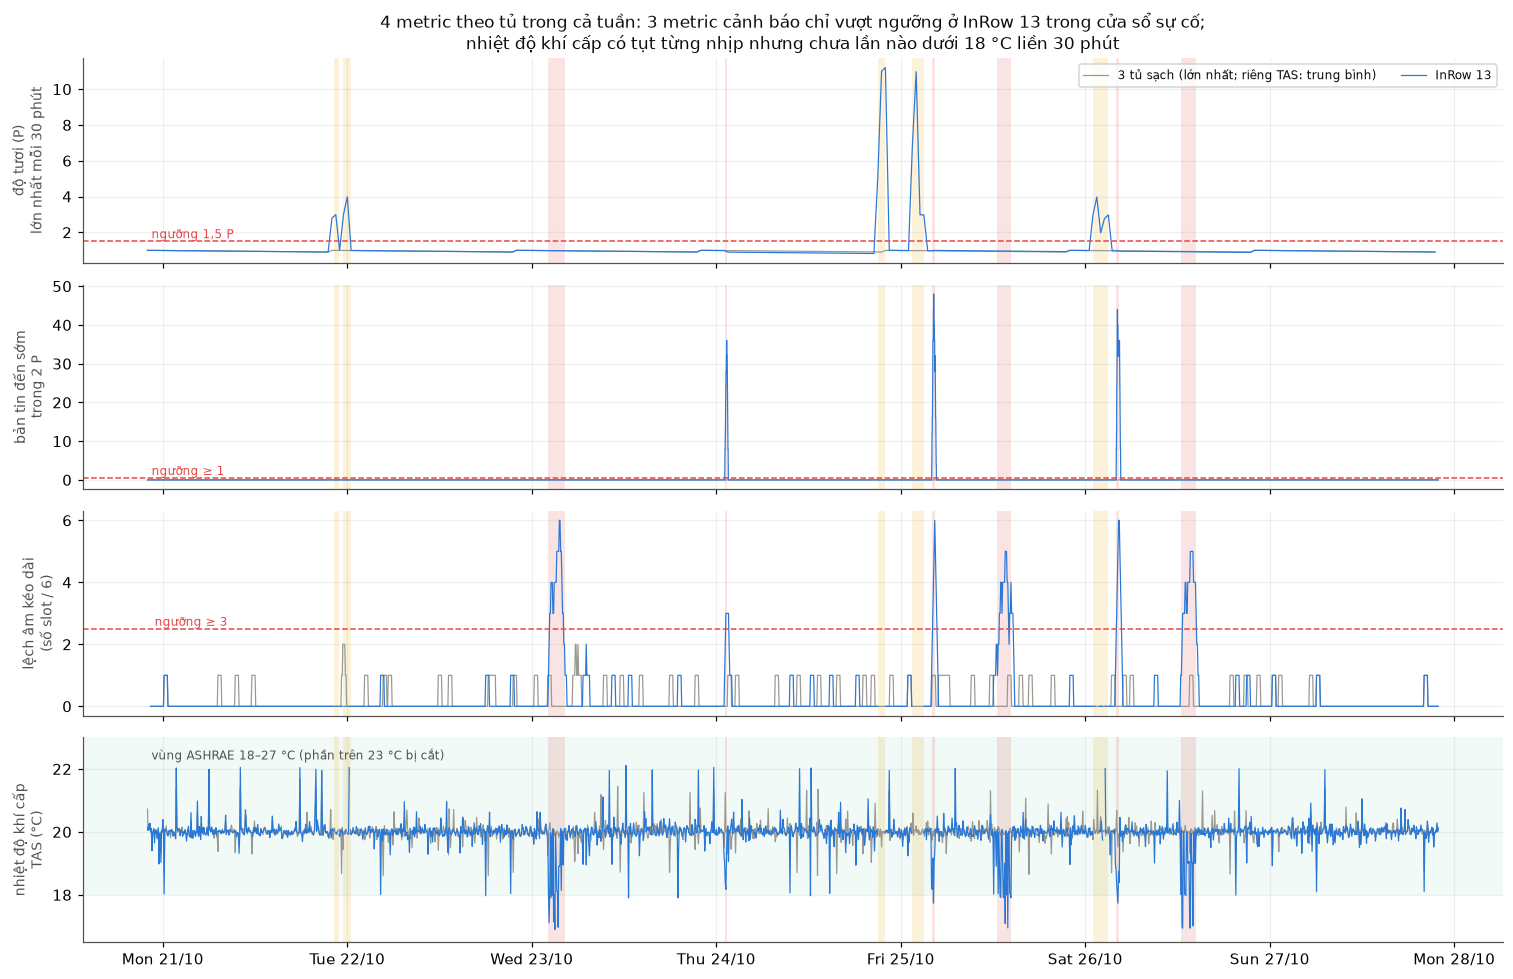

In [56]:
fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
tas_slot = pubs[pubs.sensor == "TAS"].pivot_table(index="slot", columns="inrow", values="value", aggfunc="mean")
panels = [(m_fresh.resample("30min").max(), "độ tươi (P)\nlớn nhất mỗi 30 phút", dm.SILENCE_FACTOR, "ngưỡng 1,5 P"),
          (m_early, "bản tin đến sớm\ntrong 2 P", 0.5, "ngưỡng ≥ 1"),
          (m_neg, "lệch âm kéo dài\n(số slot / 6)", dm.DEV_K - 0.5, "ngưỡng ≥ 3"),
          (tas_slot, "nhiệt độ khí cấp\nTAS (°C)", None, "vùng ASHRAE 18–27 °C")]
for ax, (df, lab, thr, thr_lab) in zip(axes, panels):
    for _, w in gt.iterrows():
        ax.axvspan(w.start, w.end, color=ALERT if w.kind == "labeled" else SERIES[3], alpha=0.15, lw=0)
    others = df[[15, 23, 25]].mean(axis=1) if thr is None else df[[15, 23, 25]].max(axis=1)
    ax.plot(df.index, others, color=MUTED, lw=0.8, label="3 tủ sạch (lớn nhất; riêng TAS: trung bình)")
    ax.plot(df.index, df[13], color=SERIES[0], lw=0.8, label="InRow 13")
    if thr is not None:
        ax.axhline(thr, color=ALERT, ls="--", lw=1); ax.text(df.index.min(), thr, f" {thr_lab}", va="bottom", fontsize=8, color=ALERT)
    else:
        ax.axhspan(18, 27, color=SERIES[2], alpha=0.06, lw=0); ax.set_ylim(16.5, 23); ax.text(df.index.min(), 22.3, f" {thr_lab} (phần trên 23 °C bị cắt)", fontsize=8, color=INK2)
    ax.set_ylabel(lab, fontsize=9)
axes[0].legend(ncol=2, fontsize=8, loc="upper right")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%a %d/%m", tz=TZ))
axes[0].set_title("4 metric theo tủ trong cả tuần: 3 metric cảnh báo chỉ vượt ngưỡng ở InRow 13 trong cửa sổ sự cố;\nnhiệt độ khí cấp có tụt từng nhịp nhưng chưa lần nào dưới 18 °C liền 30 phút")
plt.tight_layout(); save(fig, "F1_bo_metrics_mot_tuan"); plt.show()

In [57]:
print("Metric 5, độ đầy đủ (% ô 5 phút có dữ liệu), theo tủ và ngày:")
m_full

Metric 5, độ đầy đủ (% ô 5 phút có dữ liệu), theo tủ và ngày:


,T2 21/10,T3 22/10,T4 23/10,T5 24/10,T6 25/10,T7 26/10,CN 27/10
inrow,,,,,,,
13,100.0,96.5,100.0,96.2,94.8,96.5,100.0
15,100.0,100.0,100.0,100.0,100.0,100.0,100.0
23,100.0,100.0,100.0,100.0,100.0,100.0,100.0
25,100.0,100.0,100.0,100.0,100.0,100.0,100.0


**Đọc kết quả:**
- **Độ tươi** của 3 tủ sạch không bao giờ vượt 1,0 P; InRow 13 vọt tới 11,2 P khi mất bản tin. Ngưỡng 1,5 P nằm giữa hai mức, biên an toàn rộng.
- **Bản tin đến sớm** bằng 0 ở mọi tủ sạch và mọi ngày sạch; chỉ khác 0 khi bị chèn.
- **Lệch âm kéo dài** khi bình thường tối đa 2/6; khi bị sửa giá trị lên tới 6/6. Ngưỡng ≥ 3 nằm ngay trên mức nhiễu.
- **Độ đầy đủ** của tủ sạch luôn 100%; InRow 13 xuống 94,8–96,5% vào các ngày mất bản tin. Không cảnh báo tức thời theo metric này (độ tươi đã làm việc đó), nhưng nó là con số tóm tắt tốt cho báo cáo ngày.
- **Nhiệt độ khí cấp** của InRow 13 có tụt khi bị sửa giá trị (thấp nhất 16,9 °C), nhưng chỉ từng nhịp ngắn xen với giá trị bình thường: khoảng 3/4 thời gian vẫn trong vùng 18–27 °C và chưa lần nào dưới 18 °C liền 30 phút (mục “Bốn lớp tín hiệu”). Nhìn bằng mắt trên đồ thị thì thấy lạ, nhưng một quy tắc an toàn theo ASHRAE sẽ không kêu. Metric này **không** dùng để phát hiện tấn công, mà để người vận hành biết phòng máy có an toàn không.

## Từ metric đến cảnh báo

| Cảnh báo | Điều kiện | Gộp | Đóng khi | Ý nghĩa cho người vận hành |
|---|---|---|---|---|
| **Tủ không gửi dữ liệu** | độ tươi > 1,5 P | theo tủ | độ tươi < 1,2 P trong 3 chu kỳ | mù nhiệt độ của tủ; kiểm tra kết nối, thiết bị |
| **Tủ gửi dồn bất thường** | bản tin đến sớm ≥ 1 | theo tủ | 0 bản tin đến sớm trong 3 chu kỳ | thiết bị lỗi hoặc bị chèn dữ liệu |
| **Dữ liệu tủ không đáng tin** | lệch âm kéo dài ≥ 3/6 | theo tủ | lệch âm kéo dài = 0 trong 3 chu kỳ | **không dùng dữ liệu tủ này để điều khiển làm mát**; kiểm tra tại chỗ |
| *(theo dõi)* nhiệt độ khí cấp | ngoài 18–27 °C liên tục 30 phút; ngoài 15–32 °C | theo tủ | trở lại vùng 18–27 °C | quá nhiệt / quá lạnh thật [4] |

- 3 cảnh báo đầu đúng là bộ D1, D2, D4 đã chấm ở mục “Ba quy tắc phát hiện”: **11/11 sự cố, 0 báo giả**, gộp theo tủ còn 2,6 sự cố/ngày.
- Ngưỡng của 3 cảnh báo đầu do dự án chọn từ dữ liệu (Phần “Hành vi bình thường”, E). Ngưỡng nhiệt độ khí cấp lấy theo ASHRAE ([4] Table 2.1). Điều kiện "liên tục 30 phút" là lựa chọn của dự án để một gai đơn lẻ không gây cảnh báo (mục “Nhiễu”).
- Bỏ qua khung **00:00–00:03 giờ Madrid** (kết nối lại mỗi ngày, mục “Trông như bất thường nhưng không phải”).

> **Thông điệp (Phần “Metrics”).** Chỉ cần **6 metric**, tính hoàn toàn từ bản tin nhiệt độ: nhiệt độ (thu thập gốc), **độ tươi**, **bản tin đến sớm**, **lệch âm kéo dài** (3 metric cảnh báo), **độ đầy đủ** (báo cáo ngày) và **nhiệt độ khí cấp** (an toàn phòng máy, không dùng để phát hiện tấn công). Ba metric cảnh báo tách bình thường với sự cố với biên rõ ràng, bắt đủ 11/11 sự cố của DAD, 0 báo giả.

## Nguồn tham khảo

Mỗi nguồn dưới đây đã được mở và đối chiếu nguyên văn; cột cuối ghi chỗ cụ thể để mở ra kiểm. Trong notebook, nguồn được gọi bằng số trong ngoặc vuông, ví dụ [4] Table 2.1.

| # | Nguồn | Dùng cho | Chỗ cụ thể |
|---|---|---|---|
| [1] | L. Vigoya, D. Fernandez, V. Carneiro, F. Cacheda, *Annotated Dataset for Anomaly Detection in a Data Center with IoT Sensors*, Sensors 2020, 20(13), 3745, doi:10.3390/s20133745. https://pmc.ncbi.nlm.nih.gov/articles/PMC7374380/ | bối cảnh, môi trường thu dữ liệu, tấn công, số liệu | sự cố CITIC: mục 1.1; cảm biến, NetBotz: mục 3.1; Table 1: mục 3.2; testbed: mục 3.3; tấn công, MQTT không xác thực: mục 4.1; lịch tấn công: mục 5; Table 5, flow, card mạng thứ hai: mục 5.1 |
| [2] | Repo dữ liệu gốc DAD. https://github.com/dad-repository/dad | file dữ liệu, lịch tấn công | `README.md` |
| [3] | B. Saridou, G. Bendiab, S. N. Shiaeles, B. K. Papadopoulos, *Thermal Management in Large Data Centers: Security Threats and Mitigation*, SSCC 2020, CCIS 1364. https://arxiv.org/abs/2108.13261 | tấn công vào hệ thống đo nhiệt | tóm tắt |
| [4] | ASHRAE TC 9.9, *2021 Equipment Thermal Guidelines for Data Processing Environments*, Reference Card (5th ed.). https://www.ashrae.org/file%20library/technical%20resources/bookstore/supplemental%20files/therm-gdlns-5th-r-e-refcard.pdf | 18–27 °C khuyến nghị; A1 cho phép 15–32 °C | Table 2.1 |
| [5] | M. K. Herrlin, *Data Center Air Management Research*, PG&E ET Report #0912, 2010. https://datacenters.lbl.gov/sites/default/files/AirManagement_Herrlin2010.pdf | RCI và thang đánh giá | trang 8/53 |
| [6] | K. VanCamp, *Alarm Management By the Numbers*, Chemical Engineering, 3/2016 (Emerson). https://www.emerson.com/is/content/emerson/en/corporate/news-and-events/articles/documents/alarm-management-by-the-numbers.pdf | chỉ tiêu cảnh báo, định nghĩa lụt cảnh báo (EEMUA-191, ISA-18.2, IEC 62682) | Table 1; đoạn "alarm flood" |
| [7] | Google SRE Book, *Monitoring Distributed Systems*. https://sre.google/sre-book/monitoring-distributed-systems/ | 4 tín hiệu vàng | mục *The Four Golden Signals* |
| [8] | I. Seaton, *The 4 Delta T's of Data Center Cooling*, Upsite, 2015. https://www.upsite.com/blog/the-4-delta-ts-of-data-center-cooling-what-youre-missing | ΔT khí của tủ làm mát | đoạn "cooling unit ΔT" |
| [9] | N. Kroman, *Data Centers and Correct ΔT Control*, FlowCon, 2025. https://flowcon.com/articles/data-centers-and-correct-dt-control | ΔT nước, low ΔT | đoạn định nghĩa ΔT |
| [10] | US8209993B2, *Warm water cooling* (Exaflop LLC / Google). https://patents.google.com/patent/US8209993B2/en | định nghĩa approach | phần mô tả |
| [11] | Litmus, *How to Measure Industrial Data Quality: SLOs for Latency, Completeness and Freshness*. https://litmus.io/blog/how-to-measure-industrial-data-quality-slos-for-latency-completeness-and-freshness | độ tươi, độ đầy đủ, độ trễ | các mục định nghĩa |

**Kết luận của dự án, không lấy từ nguồn nào** (đều tính từ dữ liệu trong notebook): mọi ngưỡng phát hiện (1,5 P; 0,8 P; 3/6 chu kỳ; 0,8 °C), danh mục tín hiệu mục “Danh mục tín hiệu”, ánh xạ chữ số cuối `clientId` → loại cảm biến, cách trừ số nguyên độ khi sửa giá trị, phát hiện "node tự ngắt kết nối" đêm thứ Năm, và các đặc điểm dễ gây hiểu nhầm ở mục “Trông như bất thường nhưng không phải”.

**Kiểm chứng trên file gốc:** [`KIEM_CHUNG_DU_LIEU_GOC.md`](../KIEM_CHUNG_DU_LIEU_GOC.md) giải thích từng file của dataset, cách mở bằng Wireshark và trình soạn thảo, và liệt kê các bản ghi cụ thể (tên file, số frame, nguyên văn dòng CSV) cho từng phát hiện. Script `src/xem_frame.py` in nội dung một frame bất kỳ kèm dòng nhãn của nó.

Các hình `figures/paper/*.png` trích từ [1] theo giấy phép CC BY 4.0.